# Hockey project: 1. Business understanding, data understanding and data preparation

Predicting NHL team strength and in-season coach changes from information available the day before the season starts.

*FEUP Master, Machine Learning. Notebook 1 of 4 (next: 2_regression, 3_classification, 4_feature_selection).*

**Contents**

| Section | Topic | CRISP-DM phase |
|---|---|---|
| 1 | Stakeholders, business goals, data mining goals | Business understanding |
| 2 | Inventory, distributions, era effects, correlations, regression to the mean, logistic regression, PCA, clustering, mutual information | Data understanding |
| 3 | Integration, quality, feature engineering, transformation, outliers, missing data, redundancy, sampling, class imbalance, export | Data preparation |
| 4 | Decisions table and hand-off to notebooks 2-4 | Conclusion |

Each section says what we do and why, then shows the code and what we found. Where we had to choose something, the decision is written at the end of the section.

**CRISP-DM note.** We follow the CRISP-DM cycle: business understanding, data understanding, data preparation, modeling, evaluation. This notebook covers the first three phases. Notebooks 2 and 3 do modeling and evaluation; notebook 4 does feature selection. We went back and forth between phases: for example the missing-data and window experiments in section 3 changed which features we kept.

**Team rules used everywhere**
- Prediction time is the day before the season starts. Features for season *t* use only season *t-1* information plus facts about the opening-day coach (stint 1).
- NHL only. 2009 is the final test season: never used for fitting, tuning or any choice. Targets of 2009 are never printed here.
- Task (c) of the assignment is still TBA, so it is not covered.

## 1. Business understanding

We write down who would use the predictions, what each of them needs, and what a wrong prediction costs them. From that we derive business goals with measurable success criteria, and then translate every goal into a data mining task with a target, a metric, a baseline and a threshold.

The metric and the threshold must come from the decision being supported, not from what is easy to compute. For example a coach-change alarm is only useful if it finds many real changes, so recall of changes matters more than accuracy.

### 1.1 Stakeholders and their requirements

| Who | What they need | Decision supported | Cost of a wrong prediction |
|---|---|---|---|
| Front office / general manager | A preseason estimate of how strong the team and its rivals will be, and an early warning when a coach is at risk | Budget, trades and signings, ticket pricing, contingency plan for the coaching staff | Overrated team: overspending and a failed season. Missed coach change: no successor plan. False alarm: unrest and a bad message to the current coach |
| League analysts | A full ordering of the 30 teams that beats the naive rule "same order as last year", and a clear view of how much of last year was luck | Preseason power rankings, scouting reports, playoff odds | A ranking no better than last year's order adds no information |
| Sports media | Short, explainable stories: which teams will rise or fall, which coach is on the hot seat | Season previews, articles, TV segments | Wrong stories hurt credibility, but the cost is small |
| Betting and fantasy markets | Calibrated probabilities and a ranking, ideally better than the market or the previous-year baseline | Season-long odds, pick'em pools, draft rankings | Over-confident probabilities lose money: miscalibration is costly |

**Requirements that follow**
1. All inputs must be known on the day before the season starts (no leakage).
2. The ranking is judged inside each season (a league ranking is a relative thing), over many seasons, not on one lucky season.
3. Predictions must be explainable in plain words (interpretable models are preferred).
4. Coach-change errors are **asymmetric**: a missed change (false negative) and a false alarm (false positive) do not cost the same. The class is also rare (about one team in five), so accuracy is meaningless (always answering "no change" scores about 80%). We therefore focus on **recall of changes at an acceptable precision**, and on PR-AUC, not on accuracy.

### 1.2 Business goals and success criteria

| # | Business goal | Measurable success criterion (team decision) |
|---|---|---|
| G1 | Anticipate each team's competitive standing before the season | Mean within-season Spearman between predicted and actual standing is at least 0.03 above the persistence baseline ("same order as last season") on the validation seasons, and the model beats persistence in more than half of the individual seasons |
| G2 | Anticipate which teams replace their coach during the season | PR-AUC at least 25% above the prevalence baseline, and the 25% of teams flagged as riskiest contain at least 40% of the real changes (lift 1.6) |
| G3 | Understand why (explainability) | At least one interpretable model per task with readable coefficients or rules, and feature importance that agrees across methods |

These thresholds are our own choice (there is no real client to confirm them). They are deliberately modest because earlier exploration suggested that coach change is hard to predict.

### 1.3 Data mining goals

| Business goal | Task type | Target | Metric | Baseline | Success threshold |
|---|---|---|---|---|---|
| G1 standing | Regression, then rank within the season | Points per game of season *t* (z-scored within the season for training); rank = sort within season | Within-season Spearman (primary), MAE of points per game, mean absolute rank error | Persistence: rank by last season's points per game; also "predict the mean" | Spearman above persistence by at least 0.03 in mean and in more than half of the seasons |
| G2 coach change | Binary classification | More than one distinct coach stint in season *t* (1 = change) | PR-AUC (primary), recall and precision at a chosen threshold, F2, lift in top quartile | Prevalence (random scorer) and "never change" | PR-AUC at least 1.25 times prevalence, top-quartile recall at least 40% |
| G3 explain | Interpretation | Same targets | Coefficients, permutation importance, rules | Not applicable | Importance rankings agree across at least two methods |

**Evaluation design.** Chronological validation only (never shuffled team rows), all teams of a season stay together, 2009 is the final test. The validation scheme is chosen in section 3.9.

**Task (c)** of the assignment is still to be announced (TBA). When it arrives, this notebook's table and export can be reused.

**Note on the target.** "Coach change" means more than one coach stint in the season (an in-season replacement). A coach hired in the offseason is already known on the day before the season, so that is a feature, not a target.

## 2. Data understanding

We first load the data, then study it with simple tests and plots, and finish with multivariate methods (3 or more variables at once). All analysis here uses seasons up to 2008. The 2009 season is never used.

### 2.1 Load the 22 CSV files into DuckDB and take an inventory

Load every CSV into an in-memory DuckDB database and describe each table with SQL (rows, columns, years, leagues, missing share).

**Why DuckDB.** The data is relational (teams, players, goalies, coaches, awards) and the tables must be joined on keys. SQL makes the grain of each join explicit, and DuckDB reads CSV directly with no server.

In [34]:
# Setup
import warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, duckdb, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats

np.random.seed(42)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# Load every CSV into an in-memory DuckDB table with the same name
ROOT = next((p for p in [Path('.'), Path('..'), Path('../..')] if (p / 'hockey_development_data').exists()), None)
assert ROOT is not None, 'hockey_development_data folder not found next to the notebook or up to two levels above it'
con = duckdb.connect()
for p in sorted((ROOT / 'hockey_development_data').glob('*.csv')):
    con.execute(f"CREATE TABLE {p.stem} AS SELECT * FROM read_csv_auto('{p.as_posix()}')")

# Inventory: size, years, leagues and missing share of each table
rows = []
for t in con.execute("SELECT table_name FROM information_schema.tables ORDER BY 1").df()['table_name']:
    cols = con.execute(f"SELECT column_name FROM information_schema.columns WHERE table_name = '{t}'").df()['column_name'].tolist()
    n = con.execute(f"SELECT count(*) FROM {t}").fetchone()[0]
    filled = con.execute("SELECT " + " + ".join(f'count("{c}")' for c in cols) + f" FROM {t}").fetchone()[0]
    years = con.execute(f"SELECT min(year), max(year) FROM {t}").fetchone() if 'year' in cols else (None, None)
    leagues = con.execute(f"SELECT string_agg(DISTINCT lgID, ',' ORDER BY lgID) FROM {t}").fetchone()[0] if 'lgID' in cols else ''
    rows.append({'table': t, 'rows': n, 'columns': len(cols), 'first_year': years[0], 'last_year': years[1],
                 'leagues': leagues, 'missing_%': round(100 * (1 - filled / (n * len(cols))), 1)})
inventory = pd.DataFrame(rows)
display(inventory)
print(f"{len(inventory)} tables, {inventory['rows'].sum():,} rows in total")
# Team-seasons per league
display(con.execute("SELECT lgID, count(*) AS team_seasons, min(year) AS first, max(year) AS last FROM Teams GROUP BY lgID ORDER BY team_seasons DESC").df())

,table,rows,columns,first_year,last_year,leagues,missing_%
0,AwardsCoaches,75,5,1930.0,2009.0,"NHL,WHA",20.0
1,AwardsMisc,120,6,1965.0,2009.0,NHL,19.7
2,AwardsPlayers,2021,6,1917.0,2009.0,"NHL,WHA",22.5
3,Coaches,1741,14,1909.0,2009.0,"NHA,NHL,PCHA,WCHL,WHA",21.0
4,CombinedShutouts,50,8,1929.0,2009.0,,0.0
5,Goalies,4096,23,1909.0,2009.0,"NHA,NHL,PCHA,WCHL,WHA",30.8
6,GoaliesSC,31,11,1912.0,1925.0,"NHA,NHL,PCHA,WCHL",0.0
7,GoaliesShootout,346,8,2005.0,2009.0,,0.0
8,HOF,356,4,1945.0,2009.0,,0.0
9,Master,7469,31,NaN,NaN,,38.8


22 tables, 90,667 rows in total


,lgID,team_seasons,first,last
0,NHL,1265,1917,2009
1,WHA,84,1972,1978
2,NHA,45,1909,1916
3,PCHA,41,1911,1923
4,WCHL,24,1921,1925


**What we found:** The database holds 22 tables and 90,667 rows. Teams has 1,459 rows from five leagues: NHL 1,265 team-seasons (1917-2009), WHA 84, NHA 45, PCHA 41 and WCHL 24. The main seasonal tables (Teams, Scoring, Goalies, Coaches, TeamSplits) end in 2009. The missing share differs a lot: Master 38.8%, Scoring 34.1%, TeamSplits 33.2%, Goalies 30.8%, Teams 21.7%; the small tables (HOF, GoaliesSC, TeamsHalf, shootout tables) are complete but cover special purposes or short periods.

**Decision:** NHL only. It is the only league with data up to 2009 and one continuous history. Awards and the Hall of Fame are not used: they are decided after the season (or years later) and would leak the future. TeamVsTeam is skipped to keep the feature set manageable.

### 2.2 Exploration table: one row per team and season

Build a compact team-season table with SQL (points per game, goals for/against per game, special teams, penalties, shots, save percentage). Then we compute within-season z-scores and join each season to the previous season of the same franchise. The full integration of all sources is in section 3.1; this smaller table is enough to explore.

All questions below are of the form "what did the team do last season, and what happened this season", so we need pairs of consecutive seasons. We join on the franchise (franchID) and not on the team code, because codes change when a team moves.

In [35]:
# Team-season stats; shootout goals removed from GF/GA, save % only when every goalie row has shots against
con.execute("""
CREATE OR REPLACE TABLE team_year AS
WITH goalie AS (
    SELECT year, tmID, CASE WHEN count(SA) = count(*) THEN 1 - sum(GA) / sum(SA) END AS save_pct, sum(SA) AS shots_against
    FROM Goalies WHERE lgID = 'NHL' GROUP BY year, tmID),
skater AS (SELECT year, tmID, sum(SOG) AS shots_for FROM Scoring WHERE lgID = 'NHL' GROUP BY year, tmID)
SELECT t.year, t.tmID, t.franchID, t.G AS games, t.Pts / t.G AS ppg,
       (t.GF - coalesce(t.SoW, 0)) / t.G AS gf_pg, (t.GA - coalesce(t.SoL, 0)) / t.G AS ga_pg,
       t.PPG / t.PPC AS pp_pct, 1 - t.PKG / t.PKC AS pk_pct, t.PIM / t.G AS pim_pg,
       skater.shots_for / t.G AS shots_for_pg, goalie.shots_against / t.G AS shots_against_pg, goalie.save_pct
FROM Teams t
LEFT JOIN goalie ON t.year = goalie.year AND t.tmID = goalie.tmID
LEFT JOIN skater ON t.year = skater.year AND t.tmID = skater.tmID
WHERE t.lgID = 'NHL'
""")

# First and last coach of each franchise-season; more than one stint = in-season change
# The same query is reused in 3.3 on the corrected coach table, so the table name and source are parameters
COACH_SQL = """
CREATE OR REPLACE TABLE {name} AS
WITH c AS (
    -- Number the coaches of each franchise-season twice:
    -- first_rank = 1 is the opening-day coach (lowest stint), last_rank = 1 is the coach at the end (highest stint).
    -- Co-coaches in the same stint are ordered by games coached, then by coachID.
    SELECT c.year, t.franchID, c.coachID, c.stint,
           ROW_NUMBER() OVER (PARTITION BY c.year, t.franchID ORDER BY c.stint, coalesce(c.g, 0) DESC, c.coachID) AS first_rank,
           ROW_NUMBER() OVER (PARTITION BY c.year, t.franchID ORDER BY c.stint DESC, coalesce(c.g, 0) DESC, c.coachID) AS last_rank
    FROM {src} c JOIN Teams t ON c.year = t.year AND c.lgID = t.lgID AND c.tmID = t.tmID
    WHERE c.lgID = 'NHL')
SELECT year, franchID,
       max(CASE WHEN first_rank = 1 THEN coachID END) AS start_coach,
       max(CASE WHEN last_rank = 1 THEN coachID END) AS end_coach,
       count(DISTINCT stint) AS stints
FROM c GROUP BY year, franchID
"""
con.execute(COACH_SQL.format(name='coach_raw', src='Coaches'))

# Pythagorean expectation and luck, then z-scores within each season
def zscore(s):
    return (s - s.mean()) / s.std()

ty = con.execute("SELECT * FROM team_year ORDER BY year, tmID").df()
ty['pythag'] = ty['gf_pg'] ** 2 / (ty['gf_pg'] ** 2 + ty['ga_pg'] ** 2)
ty['luck'] = ty['ppg'] / 2 - ty['pythag']
ZCOLS = ['ppg', 'gf_pg', 'ga_pg', 'luck', 'pp_pct', 'pk_pct', 'pim_pg', 'shots_for_pg', 'shots_against_pg', 'save_pct']
for c in ZCOLS:
    ty[c + '_z'] = ty.groupby('year')[c].transform(zscore)

# Link every season to the previous one (2005 -> 2003 because of the lockout)
seasons = sorted(ty['year'].unique())
ty['prev_year'] = ty['year'].map(dict(zip(seasons[1:], seasons[:-1])))
prev = ty[['year', 'franchID'] + [c + '_z' for c in ZCOLS]].rename(
    columns={'year': 'prev_year', **{c + '_z': 'prev_' + c + '_z' for c in ZCOLS}})

# Coach change flags for this season and last season
cs = con.execute("SELECT * FROM coach_raw").df()
cs['coach_change'] = (cs['stints'] > 1).astype(int)
prev_cs = cs[['year', 'franchID', 'end_coach', 'coach_change']].rename(
    columns={'year': 'prev_year', 'end_coach': 'prev_end_coach', 'coach_change': 'prev_coach_change'})

# Pairs: this season + last season of the same franchise (franchID survives relocations)
pairs = (ty[['year', 'tmID', 'franchID', 'prev_year', 'ppg', 'ppg_z', 'gf_pg']]
         .merge(prev, on=['prev_year', 'franchID'])
         .merge(cs[['year', 'franchID', 'start_coach', 'coach_change']], on=['year', 'franchID'])
         .merge(prev_cs, on=['prev_year', 'franchID'], how='left'))
pairs['coach_new'] = (pairs['start_coach'] != pairs['prev_end_coach']).astype(float).where(pairs['prev_end_coach'].notna())
pairs = pairs[pairs['year'].between(1967, 2008)].reset_index(drop=True)
pairs['change_z'] = pairs['ppg_z'] - pairs['prev_ppg_z']
dev = ty[ty['year'].between(1967, 2008)].copy()

print(f"team_year: {len(ty)} NHL team-seasons (1917-2009) | development rows 1967-2008: {len(dev)}")
print(f"pairs (season t with a previous season of the same franchise, 1967-2008): {len(pairs)}")
print(f"coach change rate in pairs: {pairs['coach_change'].mean():.3f}")
display(pairs.head(4).round(2))

team_year: 1265 NHL team-seasons (1917-2009) | development rows 1967-2008: 908
pairs (season t with a previous season of the same franchise, 1967-2008): 883
coach change rate in pairs: 0.211


,year,tmID,franchID,prev_year,ppg,ppg_z,gf_pg,prev_ppg_z,prev_gf_pg_z,prev_ga_pg_z,prev_luck_z,prev_pp_pct_z,prev_pk_pct_z,prev_pim_pg_z,prev_shots_for_pg_z,prev_shots_against_pg_z,prev_save_pct_z,start_coach,coach_change,prev_end_coach,prev_coach_change,coach_new,change_z
0,1967,BOS,BOS,1966.0,1.14,0.81,3.50,-1.51,-0.91,1.36,-0.79,-1.45,-1.00,0.15,NaN,NaN,NaN,sindeha01c,0,sindeha01c,0,0.0,2.32
1,1967,CHI,CHI,1966.0,1.08,0.48,2.86,1.40,1.89,-1.18,-1.05,1.21,0.54,0.05,NaN,NaN,NaN,reaybi01c,0,reaybi01c,0,0.0,-0.91
2,1967,DET,DET,1966.0,0.89,-0.65,3.31,-0.70,0.11,0.99,-0.65,0.58,-0.17,-0.48,NaN,NaN,NaN,abelsi01c,0,abelsi01c,0,0.0,0.05
3,1967,MTL,MTL,1966.0,1.27,1.62,3.19,0.41,-0.23,-0.63,0.42,0.64,1.21,1.77,NaN,NaN,NaN,blaketo01c,0,blaketo01c,0,0.0,1.21


**What we found:** The SQL table has 1,265 NHL team-seasons. For 1967-2008 there are 908 rows, and 883 of them have a previous season of the same franchise; the other 25 are first seasons of new franchises. The coach-change rate in these 883 pairs is 0.211 (186 changes). The first rows show the structure: one row per team and season, with last season's z-scores (prev_*) next to this season's outcomes.

### 2.3 Descriptive statistics and the distribution of points per game

Describe the main team statistics, then look at the distribution of points per game (ppg) with a histogram and KDE, a Q-Q plot, and the Shapiro-Wilk and D'Agostino normality tests.

Many classical tests (t-test, ANOVA, Pearson correlation) assume normal data. We check that assumption before choosing tests. If it fails, we use rank-based tests (Mann-Whitney, Kruskal-Wallis, Spearman) that do not need it.

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
ppg,908.0,1.024,0.225,0.262,0.874,1.036,1.176,1.650,-0.259,0.016
gf_pg,908.0,3.204,0.611,1.841,2.731,3.103,3.641,5.575,0.523,-0.094
ga_pg,908.0,3.204,0.640,2.000,2.707,3.122,3.625,5.575,0.518,-0.141
pp_pct,908.0,0.190,0.038,0.093,0.162,0.187,0.215,0.319,0.409,0.025
pk_pct,908.0,0.811,0.037,0.677,0.787,0.814,0.838,0.893,-0.490,-0.061
pim_pg,908.0,17.326,4.899,7.405,13.620,16.393,20.724,33.912,0.664,0.033
save_pct,654.0,0.896,0.016,0.845,0.884,0.899,0.908,0.930,-0.500,-0.316


Shapiro-Wilk ppg: W = 0.9952, p = 5.91e-03 | ppg z-score: W = 0.9953, p = 6.47e-03
D'Agostino K2 ppg: statistic = 10.0, p = 6.81e-03


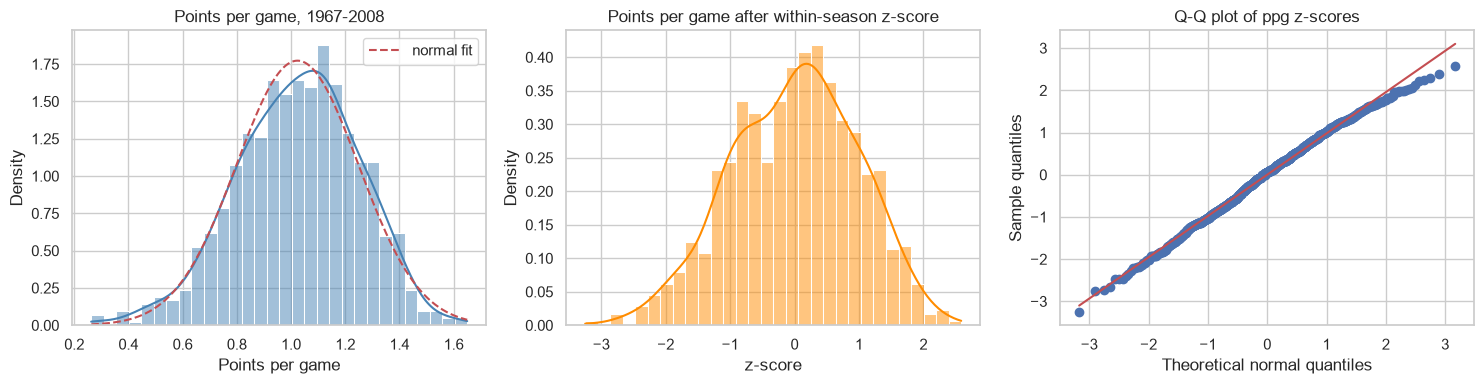

In [36]:
# Summary stats with skewness and kurtosis
cols = ['ppg', 'gf_pg', 'ga_pg', 'pp_pct', 'pk_pct', 'pim_pg', 'save_pct']
desc = dev[cols].describe().T
desc['skew'] = dev[cols].skew()
desc['kurtosis'] = dev[cols].kurt()
display(desc.round(3))

# Normality tests on raw and z-scored points per game
sw, sw_z = stats.shapiro(dev['ppg']), stats.shapiro(dev['ppg_z'])
dag = stats.normaltest(dev['ppg'])
print(f"Shapiro-Wilk ppg: W = {sw.statistic:.4f}, p = {sw.pvalue:.2e} | ppg z-score: W = {sw_z.statistic:.4f}, p = {sw_z.pvalue:.2e}")
print(f"D'Agostino K2 ppg: statistic = {dag.statistic:.1f}, p = {dag.pvalue:.2e}")

# Histogram + normal fit, z-score histogram, Q-Q plot
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(dev['ppg'], kde=True, stat='density', bins=30, ax=ax[0], color='steelblue')
x = np.linspace(dev['ppg'].min(), dev['ppg'].max(), 200)
ax[0].plot(x, stats.norm.pdf(x, dev['ppg'].mean(), dev['ppg'].std()), 'r--', label='normal fit')
ax[0].set(title='Points per game, 1967-2008', xlabel='Points per game', ylabel='Density')
ax[0].legend()
sns.histplot(dev['ppg_z'], kde=True, stat='density', bins=30, ax=ax[1], color='darkorange')
ax[1].set(title='Points per game after within-season z-score', xlabel='z-score', ylabel='Density')
stats.probplot(dev['ppg_z'], dist='norm', plot=ax[2])
ax[2].set(title='Q-Q plot of ppg z-scores', xlabel='Theoretical normal quantiles', ylabel='Sample quantiles')
plt.tight_layout()
plt.show()

**What we found:** Points per game (1967-2008, n = 908) has mean 1.024, SD 0.225, range 0.262 to 1.650, skewness -0.26 and excess kurtosis 0.02: nearly symmetric with a slightly longer lower tail (a few very weak teams). Save percentage exists for only 654 team-seasons (mean 0.896), because goalie shots are missing before 1982. Both normality tests reject normality at the 5% level (Shapiro-Wilk W = 0.995, p = 0.006; D'Agostino K2 = 10.0, p = 0.007), also after the within-season z-score (p = 0.006). The histogram and the Q-Q plot show that the departure is mild: the points follow the line except in the tails.

**Decision:** with 908 rows the tests detect even small departures, so the data is close to normal in practice but not exactly. We use rank-based tests (Mann-Whitney, Kruskal-Wallis, Spearman) for inference, and OLS or Pearson only where an easy-to-read coefficient is useful (sections 2.6 and 2.9), treated as approximate.

### 2.4 Era analysis

Compare points per game and goals per game across decades with boxplots, a Kruskal-Wallis test (rank-based ANOVA) and a Brown-Forsythe test of equal spread.

NHL rules changed a lot (overtime loss points from 1999, shootouts from 2005, more or fewer goals in different eras). If the level of ppg or its spread changes by decade, then raw values from different decades are not comparable. A test tells us whether the visible differences are real, and the answer justifies standardizing inside each season (section 3.4).

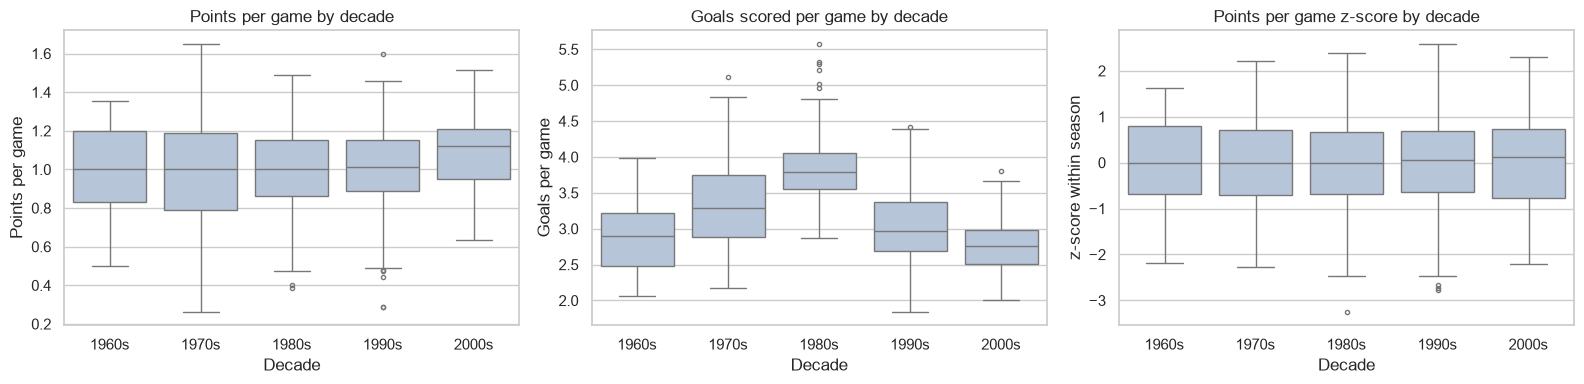

,variable,Kruskal H,p (levels differ),epsilon^2,Brown-Forsythe F,p (spread differs)
0,ppg,26.1565,0.0000,0.0245,10.3536,0.000
1,gf_pg,384.4590,0.0000,0.4213,11.9861,0.000
2,ppg_z,0.2425,0.9932,-0.0042,0.1672,0.955


,teams,mean_ppg,sd_ppg,mean_goals
decade,,,,
1960s,36,1.000,0.222,2.891
1970s,170,1.000,0.286,3.327
1980s,210,1.000,0.220,3.833
1990s,252,1.006,0.209,3.064
2000s,240,1.084,0.185,2.759


In [37]:
# Boxplots by decade
dev['decade'] = (dev['year'] // 10 * 10).astype(str) + 's'
order = sorted(dev['decade'].unique())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (col, title, ylab) in zip(ax, [('ppg', 'Points per game by decade', 'Points per game'),
                                      ('gf_pg', 'Goals scored per game by decade', 'Goals per game'),
                                      ('ppg_z', 'Points per game z-score by decade', 'z-score within season')]):
    sns.boxplot(data=dev, x='decade', y=col, order=order, ax=a, color='lightsteelblue', fliersize=3)
    a.set(title=title, xlabel='Decade', ylabel=ylab)
plt.tight_layout()
plt.show()

# Kruskal-Wallis (levels) and Brown-Forsythe (spread) across decades; epsilon^2 = effect size
def groups(col):
    return [g[col].values for _, g in dev.groupby('decade')]

rows = []
for col in ['ppg', 'gf_pg', 'ppg_z']:
    h, p = stats.kruskal(*groups(col))
    eps2 = (h - len(order) + 1) / (len(dev) - len(order))
    lev = stats.levene(*groups(col), center='median')
    rows.append({'variable': col, 'Kruskal H': h, 'p (levels differ)': p, 'epsilon^2': eps2,
                 'Brown-Forsythe F': lev.statistic, 'p (spread differs)': lev.pvalue})
display(pd.DataFrame(rows).round(4))
display(dev.groupby('decade').agg(teams=('ppg', 'size'), mean_ppg=('ppg', 'mean'), sd_ppg=('ppg', 'std'),
                                  mean_goals=('gf_pg', 'mean')).round(3))

**What we found:** Level and spread of points per game differ between decades (Kruskal-Wallis H = 26.2, p < 0.0001, epsilon^2 = 0.025, a small effect). The mean is 1.000 in the 1960s-1980s and 1.006 in the 1990s, but 1.084 in the 2000s, when overtime-loss points made some games worth 3 points. The spread changes too (Brown-Forsythe F = 10.4, p < 0.0001): the SD of points per game is 0.286 in the 1970s and 0.185 in the 2000s. Goals per game differ much more (H = 384.5, epsilon^2 = 0.42, a large effect): 2.89 (1960s), 3.33, 3.83 (1980s), 3.06, 2.76 (2000s). After the within-season z-score the differences disappear (H = 0.24, p = 0.993; spread F = 0.17, p = 0.955).

**Decision:** standardize every statistic inside its own season (section 3.4). This removes era drift in level and spread, which is what a within-season ranking needs. Raw values from different decades are not compared.

### 2.5 Correlation heatmap: last season versus next season

Spearman correlation matrix of last season's z-scored team statistics together with this season's points per game and coach change, with p-values corrected for multiple testing (Benjamini-Hochberg).

**Why Spearman.** The data is not normal (section 2.3) and coach change is binary, so rank correlation is the safe choice. With 12 variables we do many tests at once, so we control the false discovery rate.

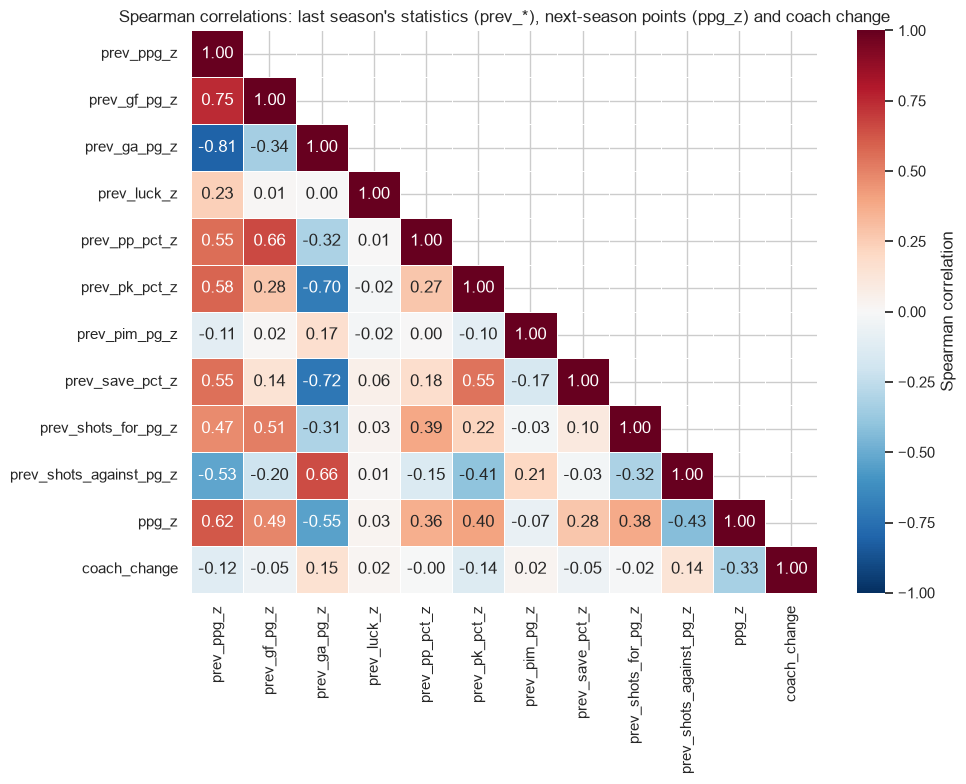

rho          p_adj (BH)       
target                  coach_change  ppg_z coach_change  ppg_z
feature                                                        
prev_ga_pg_z                   0.149 -0.545        0.000  0.000
prev_gf_pg_z                  -0.049  0.488        0.205  0.000
prev_luck_z                    0.017  0.030        0.682  0.476
prev_pim_pg_z                  0.025 -0.071        0.541  0.054
prev_pk_pct_z                 -0.136  0.403        0.000  0.000
prev_pp_pct_z                 -0.003  0.360        0.924  0.000
prev_ppg_z                    -0.118  0.622        0.001  0.000
prev_save_pct_z               -0.051  0.278        0.272  0.000
prev_shots_against_pg_z        0.138 -0.429        0.001  0.000
prev_shots_for_pg_z           -0.015  0.381        0.682  0.000

In [38]:
from statsmodels.stats.multitest import multipletests

# Spearman between last season's stats and this season's targets
feat = ['prev_ppg_z', 'prev_gf_pg_z', 'prev_ga_pg_z', 'prev_luck_z', 'prev_pp_pct_z', 'prev_pk_pct_z',
        'prev_pim_pg_z', 'prev_save_pct_z', 'prev_shots_for_pg_z', 'prev_shots_against_pg_z']
heat_cols = feat + ['ppg_z', 'coach_change']
corr = pairs[heat_cols].corr(method='spearman')

# Lower triangle only
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title("Spearman correlations: last season's statistics (prev_*), next-season points (ppg_z) and coach change")
plt.tight_layout()
plt.show()

# p-values corrected for the 20 tests (Benjamini-Hochberg)
res = []
for target in ['ppg_z', 'coach_change']:
    for f in feat:
        ok = pairs[[f, target]].dropna()
        r, p = stats.spearmanr(ok[f], ok[target])
        res.append({'target': target, 'feature': f, 'n': len(ok), 'rho': r, 'p': p})
res = pd.DataFrame(res)
res['p_adj (BH)'] = multipletests(res['p'], method='fdr_bh')[1]
display(res.pivot(index='feature', columns='target', values=['rho', 'p_adj (BH)']).round(3))

**What we found:** Next-season points (z) correlate most with last season's points (rho = 0.62), then goals against (-0.55), goals for (0.49), shots against (-0.43), penalty kill (0.40), shots for (0.38), power play (0.36) and save percentage (0.28); all are significant after Benjamini-Hochberg correction. Last season's luck is not correlated with next-season points (rho = 0.03, adjusted p = 0.48) and penalty minutes hardly (-0.07, adjusted p = 0.054). Coach change is only weakly related to anything: goals against (rho = 0.15), shots against (0.14), penalty kill (-0.14) and last season's points (-0.12) are significant (adjusted p about 0.001 or less), while goals for (-0.05, adjusted p = 0.21), luck and power play are not.

a weak defence last season is a stronger warning sign for a coach than weak scoring. All correlations with coach change are below 0.15, so we expect coach change to be much harder to predict than points.

### 2.6 Regression to the mean

Scatter plot of this season's points z-score against last season's, with an OLS line, its confidence interval and the identity line. We also estimate the slope in each decade.

If a team's result were pure skill, the slope would be 1 (same strength every year). A slope below 1 means part of last year's result was luck that does not repeat. This number limits how well any preseason prediction can do and tells us whether a model should shrink last year's results.

Slope = 0.622 (95% CI 0.572 to 0.673), intercept = 0.032, R^2 = 0.399, n = 883
Teams above +1 SD last season (n=144): average z last season 1.42 -> this season 0.96
Teams below -1 SD last season (n=146): average z last season -1.50 -> this season -0.88


decade,1960s,1970s,1980s,1990s,2000s
slope,0.595,0.762,0.644,0.568,0.569
n,30.000,160.000,210.000,245.000,238.000


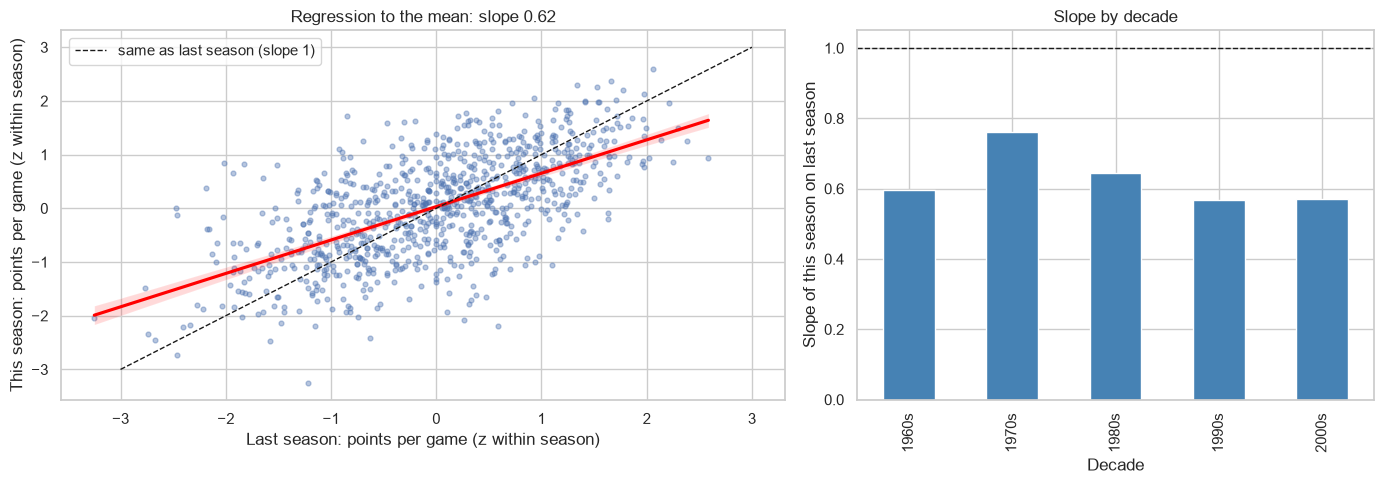

In [39]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# OLS of this season on last season: the slope measures persistence
m = smf.ols('ppg_z ~ prev_ppg_z', data=pairs).fit()
lo, hi = m.conf_int().loc['prev_ppg_z']
print(f"Slope = {m.params['prev_ppg_z']:.3f} (95% CI {lo:.3f} to {hi:.3f}), intercept = {m.params['Intercept']:.3f}, R^2 = {m.rsquared:.3f}, n = {int(m.nobs)}")
# How far the extremes move back toward the middle
top = pairs[pairs['prev_ppg_z'] > 1]
bottom = pairs[pairs['prev_ppg_z'] < -1]
print(f"Teams above +1 SD last season (n={len(top)}): average z last season {top['prev_ppg_z'].mean():.2f} -> this season {top['ppg_z'].mean():.2f}")
print(f"Teams below -1 SD last season (n={len(bottom)}): average z last season {bottom['prev_ppg_z'].mean():.2f} -> this season {bottom['ppg_z'].mean():.2f}")

# Same slope per decade
pairs['decade'] = (pairs['year'] // 10 * 10).astype(str) + 's'
slopes = pairs.groupby('decade').apply(lambda g: pd.Series({'slope': np.polyfit(g['prev_ppg_z'], g['ppg_z'], 1)[0], 'n': len(g)}))
display(slopes.round(3).T)

# Scatter with identity line (dashed) and slope per decade
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.4, 1]})
sns.regplot(data=pairs, x='prev_ppg_z', y='ppg_z', scatter_kws={'s': 12, 'alpha': 0.4}, line_kws={'color': 'red'}, ax=ax[0])
ax[0].plot([-3, 3], [-3, 3], 'k--', lw=1, label='same as last season (slope 1)')
ax[0].set(xlabel='Last season: points per game (z within season)', ylabel='This season: points per game (z within season)',
          title=f"Regression to the mean: slope {m.params['prev_ppg_z']:.2f}")
ax[0].legend()
slopes['slope'].plot.bar(ax=ax[1], color='steelblue')
ax[1].axhline(1, color='k', ls='--', lw=1)
ax[1].set(title='Slope by decade', xlabel='Decade', ylabel='Slope of this season on last season')
plt.tight_layout()
plt.show()

**What we found:** The slope of this season's points z-score on last season's is 0.622 (95% CI 0.572 to 0.673, R^2 = 0.399, n = 883). About 38% of a team's distance from the league average disappears within a year. Teams more than 1 SD above average (n = 144) had +1.42 last season and +0.96 this season; teams more than 1 SD below (n = 146) had -1.50 and -0.88. The slope is stable across decades: 0.595 (1960s, only 30 pairs), 0.762, 0.644, 0.568, 0.569.

**Decision:** last season is the best single predictor, but it explains only 40% of the variance and extremes move back toward the middle. A model should shrink last year's result, and persistence (slope 1) is a weak baseline to beat. The stability across decades supports pooling many seasons for training.

### 2.7 What precedes a coach change? Univariate tests

Compare last season's statistics between teams that changed coach this season and those that did not (Mann-Whitney U with rank-biserial effect size). Test last season's standing in thirds with a chi-square test and Cramer's V, and show the change rate by quintile with confidence intervals. Also test whether a brand-new opening-day coach changes the picture.

Mann-Whitney is the rank-based alternative to the t-test (no normality assumption). Chi-square tests an association between two categorical variables. Effect sizes matter because with 900 rows even small differences can be significant.

,last season feature,median (change),median (no change),rank-biserial r,p,p_adj (BH)
0,prev_ppg_z,-0.2572,0.1133,0.1667,0.0005,0.0014
1,prev_luck_z,-0.0129,-0.0390,-0.0240,0.6143,0.7371
2,prev_gf_pg_z,-0.1603,-0.0515,0.0698,0.1433,0.2865
3,prev_ga_pg_z,0.2328,-0.1451,-0.2103,0.0000,0.0001
4,prev_pim_pg_z,-0.0428,-0.0981,-0.0353,0.4594,0.6891
5,prev_pp_pct_z,0.0135,-0.0785,0.0046,0.9238,0.9238


Standing in thirds vs coach change: chi2 = 11.72, dof = 2, p = 0.0029, Cramer's V = 0.115
{'bottom third': 0.275, 'middle third': 0.194, 'top third': 0.163}
Opening-day coach new (1) vs returning (0): change rate {0.0: 0.22, 1.0: 0.184}, chi2 = 1.17, p = 0.2788


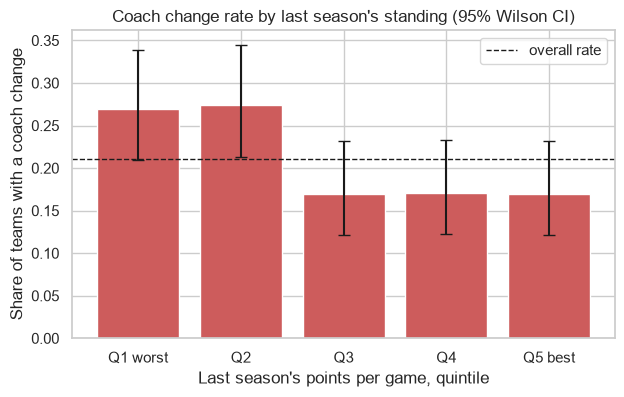

In [40]:
from statsmodels.stats.proportion import proportion_confint

# Mann-Whitney: changed vs kept coach, with rank-biserial effect size
rows = []
for f in ['prev_ppg_z', 'prev_luck_z', 'prev_gf_pg_z', 'prev_ga_pg_z', 'prev_pim_pg_z', 'prev_pp_pct_z']:
    a, b = pairs.loc[pairs['coach_change'] == 1, f].dropna(), pairs.loc[pairs['coach_change'] == 0, f].dropna()
    u, p = stats.mannwhitneyu(a, b)
    rows.append({'last season feature': f, 'median (change)': a.median(), 'median (no change)': b.median(),
                 'rank-biserial r': 1 - 2 * u / (len(a) * len(b)), 'p': p})
mw = pd.DataFrame(rows)
mw['p_adj (BH)'] = multipletests(mw['p'], method='fdr_bh')[1]
display(mw.round(4))

# Chi-square on last season's standing in thirds; Cramer's V = effect size
pairs['standing3'] = pd.qcut(pairs['prev_ppg_z'], 3, labels=['bottom third', 'middle third', 'top third'])
tab = pd.crosstab(pairs['standing3'], pairs['coach_change'])
chi2, p, dof, _ = stats.chi2_contingency(tab)
v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"Standing in thirds vs coach change: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4f}, Cramer's V = {v:.3f}")
print((tab[1] / tab.sum(axis=1)).round(3).to_dict())

# Does a new opening-day coach matter?
new = pd.crosstab(pairs['coach_new'], pairs['coach_change'])
chi2n, pn, _, _ = stats.chi2_contingency(new)
print(f"Opening-day coach new (1) vs returning (0): change rate {(new[1] / new.sum(axis=1)).round(3).to_dict()}, chi2 = {chi2n:.2f}, p = {pn:.4f}")

# Change rate by quintile with 95% Wilson intervals
pairs['standing5'] = pd.qcut(pairs['prev_ppg_z'], 5, labels=['Q1 worst', 'Q2', 'Q3', 'Q4', 'Q5 best'])
g = pairs.groupby('standing5', observed=True)['coach_change'].agg(['sum', 'count'])
g['rate'] = g['sum'] / g['count']
ci = proportion_confint(g['sum'], g['count'], method='wilson')
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(g.index.astype(str), g['rate'], yerr=[g['rate'] - ci[0], ci[1] - g['rate']], capsize=4, color='indianred')
ax.axhline(pairs['coach_change'].mean(), color='k', ls='--', lw=1, label='overall rate')
ax.set(title="Coach change rate by last season's standing (95% Wilson CI)", xlabel="Last season's points per game, quintile", ylabel='Share of teams with a coach change')
ax.legend()
plt.show()

**What we found:** Teams that changed coach had clearly lower points last season (median z -0.26 vs +0.11; Mann-Whitney p = 0.0005, 0.001 after correction) and worse goals against (median z +0.23 vs -0.15, p < 0.0001); both effects are small (rank-biserial |r| = 0.17 and 0.21). Goals for (p = 0.14), luck (p = 0.61), penalty minutes (p = 0.46) and power play (p = 0.92) show no difference. By thirds of last season's points, the change rate falls from 27.5% (bottom) to 19.4% (middle) and 16.3% (top): chi-square = 11.7, p = 0.003, Cramer's V = 0.115 (weak association). Whether the opening-day coach is new has no significant effect (18.4% new vs 22.0% returning, chi-square p = 0.279).

coach changes follow bad results and bad defence, but even the worst third has only about a quarter of changes, so most weak teams keep their coach. The signal is real and small.

### 2.8 Multivariable logistic regression of coach change

Fit a logistic regression of coach change on several last-season factors at the same time (statsmodels), and report odds ratios per +1 SD with 95% confidence intervals and p-values. We also show a forest plot and the variance inflation factors.

Univariate tests can mislead when factors are correlated: for example a good team scores a lot and wins a lot. A multivariable model estimates the effect of each factor while holding the others fixed. The odds ratio is easy to explain to a stakeholder (a ratio above 1 raises the odds of a change, below 1 lowers them). This is also an in-sample explanatory model, not a validated predictor.

,odds ratio,CI low,CI high,p-value
prev_ppg_z,0.495,0.366,0.670,0.000
prev_luck_z,1.222,1.018,1.467,0.031
prev_gf_pg_z,1.429,1.085,1.882,0.011
prev_pim_pg_z,1.008,0.848,1.198,0.926
coach_new,0.712,0.480,1.057,0.092
prev_coach_change,0.677,0.437,1.047,0.080


n = 883, events = 186, LR test p = 1.31e-04, McFadden R^2 = 0.030, in-sample AUC = 0.618
VIF: {'prev_ppg_z': np.float64(3.01), 'prev_luck_z': np.float64(1.15), 'prev_gf_pg_z': np.float64(2.59), 'prev_pim_pg_z': np.float64(1.04), 'coach_new': np.float64(1.05), 'prev_coach_change': np.float64(1.15)}


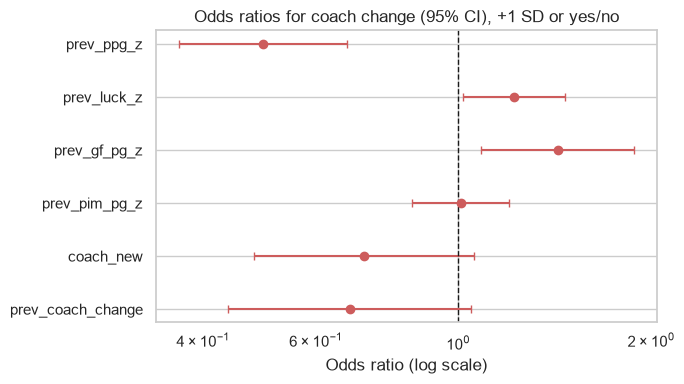

In [41]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score

# Logit with several last-season factors at once; report odds ratios
xs = ['prev_ppg_z', 'prev_luck_z', 'prev_gf_pg_z', 'prev_pim_pg_z', 'coach_new', 'prev_coach_change']
d = pairs.dropna(subset=xs + ['coach_change'])
logit = smf.logit('coach_change ~ ' + ' + '.join(xs), data=d).fit(disp=0)
ci = logit.conf_int()
orr = pd.DataFrame({'odds ratio': np.exp(logit.params), 'CI low': np.exp(ci[0]), 'CI high': np.exp(ci[1]), 'p-value': logit.pvalues}).drop('Intercept')
display(orr.round(3))
print(f"n = {int(logit.nobs)}, events = {int(d['coach_change'].sum())}, LR test p = {logit.llr_pvalue:.2e}, McFadden R^2 = {logit.prsquared:.3f}, in-sample AUC = {roc_auc_score(d['coach_change'], logit.predict(d)):.3f}")
# Check collinearity
X = sm.add_constant(d[xs])
print('VIF:', {c: round(variance_inflation_factor(X.values, i), 2) for i, c in enumerate(X.columns) if c != 'const'})

# Forest plot of the odds ratios
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(orr))[::-1]
ax.errorbar(orr['odds ratio'], y, xerr=[orr['odds ratio'] - orr['CI low'], orr['CI high'] - orr['odds ratio']], fmt='o', color='indianred', capsize=3)
ax.axvline(1, color='k', ls='--', lw=1)
ax.set_yticks(y, orr.index)
ax.set_xscale('log')
ax.set(title='Odds ratios for coach change (95% CI), +1 SD or yes/no', xlabel='Odds ratio (log scale)')
plt.tight_layout()
plt.show()

**What we found:** Logistic regression on 883 team-seasons (186 changes). Odds ratios per +1 SD: last season's points 0.495 (95% CI 0.366-0.670, p < 0.001), so each extra SD of points roughly halves the odds of a change. Goals for 1.43 (1.09-1.88, p = 0.011) and luck 1.22 (1.02-1.47, p = 0.031) are above 1; penalty minutes 1.01 (p = 0.93), new coach 0.71 (p = 0.092) and previous-year coach change 0.68 (p = 0.080) are not significant at 5%. The model is significant overall (likelihood-ratio p = 1.3e-4) but explains little: McFadden R^2 = 0.030, in-sample AUC = 0.618. All VIFs are below 3.1, so collinearity does not distort the odds ratios.

at equal points, a team that scored more has higher odds of a change, meaning its points came with a weak defence (consistent with goals against in 2.5 and 2.7). An odds ratio above 1 for luck means a team whose points flatter its goal difference is more likely to change coach next year (its record is expected to fall back). Both secondary effects have weak support (p between 0.01 and 0.03, not corrected for multiple tests). The odds are about 30% lower after a new coach or a change last year, but that is not significant. This is an explanatory in-sample model; predictive value is tested in notebook 3.

### 2.9 Does last season's luck matter once we control for last season's points?

Luck is points earned minus the points expected from goal difference (Pythagorean expectation: goals for squared over goals for squared plus goals against squared). We fit OLS models of this season's points on last season's points, with and without luck, run an F-test for adding luck, compute the partial correlation, and draw an added-variable plot.

Luck and points are correlated (lucky teams have more points). A partial correlation and a multiple regression separate the two effects. If luck has a negative partial effect, the team's *skill* is better measured by goal difference than by points, which is useful engineered information.

,coef,std err,t,p,CI low,CI high
Intercept,0.0314,0.0248,1.2663,0.2057,-0.0172,0.0800
prev_ppg_z,0.6574,0.0263,25.0304,0.0000,0.6058,0.7089
prev_luck_z,-0.1359,0.0263,-5.1756,0.0000,-0.1875,-0.0844


R^2 without luck = 0.3989, with luck = 0.4166, adjusted R^2 0.3982 -> 0.4153
F-test for adding luck: {'F': 26.7864, 'Pr(>F)': 0.0}
Partial correlation of luck with next-season points, controlling for last season's points: r = -0.172, p = 2.77e-07
Raw correlation luck vs next season points: 0.036; luck vs last season points: 0.260


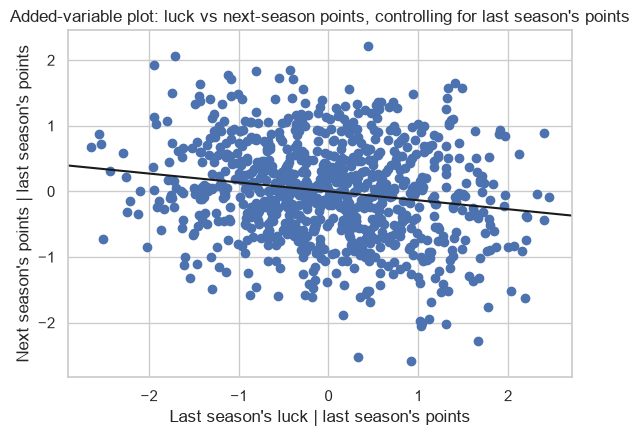

In [42]:
from statsmodels.stats.anova import anova_lm

# Points-only model vs points + luck
mA = smf.ols('ppg_z ~ prev_ppg_z', data=pairs).fit()
mB = smf.ols('ppg_z ~ prev_ppg_z + prev_luck_z', data=pairs).fit()
tab = pd.DataFrame({'coef': mB.params, 'std err': mB.bse, 't': mB.tvalues, 'p': mB.pvalues,
                    'CI low': mB.conf_int()[0], 'CI high': mB.conf_int()[1]})
display(tab.round(4))
print(f"R^2 without luck = {mA.rsquared:.4f}, with luck = {mB.rsquared:.4f}, adjusted R^2 {mA.rsquared_adj:.4f} -> {mB.rsquared_adj:.4f}")
print('F-test for adding luck:', anova_lm(mA, mB).iloc[1][['F', 'Pr(>F)']].round(5).to_dict())

# Partial correlation: correlate the residuals after removing last season's points
res_y = smf.ols('ppg_z ~ prev_ppg_z', data=pairs).fit().resid
res_x = smf.ols('prev_luck_z ~ prev_ppg_z', data=pairs).fit().resid
r, p = stats.pearsonr(res_x, res_y)
print(f"Partial correlation of luck with next-season points, controlling for last season's points: r = {r:.3f}, p = {p:.2e}")
print(f"Raw correlation luck vs next season points: {stats.pearsonr(pairs['prev_luck_z'], pairs['ppg_z'])[0]:.3f}; luck vs last season points: {stats.pearsonr(pairs['prev_luck_z'], pairs['prev_ppg_z'])[0]:.3f}")

# Added-variable plot
fig = plt.figure(figsize=(6.5, 4.5))
sm.graphics.plot_partregress('ppg_z', 'prev_luck_z', ['prev_ppg_z'], data=pairs, obs_labels=False, ax=fig.gca())
fig.gca().set(title="Added-variable plot: luck vs next-season points, controlling for last season's points",
              xlabel="Last season's luck | last season's points", ylabel="Next season's points | last season's points")
plt.show()

**What we found:** Adding last season's luck to the regression raises R^2 from 0.40 to 0.42 (F-test p < 0.0001). Coefficients: last season's points +0.657 (CI 0.606 to 0.709) and luck -0.136 (CI -0.188 to -0.084). The partial correlation of luck with next-season points, controlling for last season's points, is r = -0.172 (p = 2.8e-7), while the raw correlation is almost zero (0.036) because luck correlates positively with last season's points (0.260), so the two effects cancel (a suppression effect).

**Decision:** a team whose points were 1 SD luckier than its goal difference justified earns about 0.14 SD fewer points next year, on top of the normal fall-back. Luck is a useful engineered feature, but only together with points or goal features. We keep luck, and we do not judge features by their univariate correlation alone.

### 2.10 Multivariate scatter, coloured by coach change

A pair plot of four last-season variables (points, luck, goals for, goals against), coloured by whether the team changed coach this season. Diagonals show the distribution of each variable by class.

Three or more variables at once show whether coach changes live in a corner of the feature space (for example bad defence and bad luck together) that a pairwise view would hide.

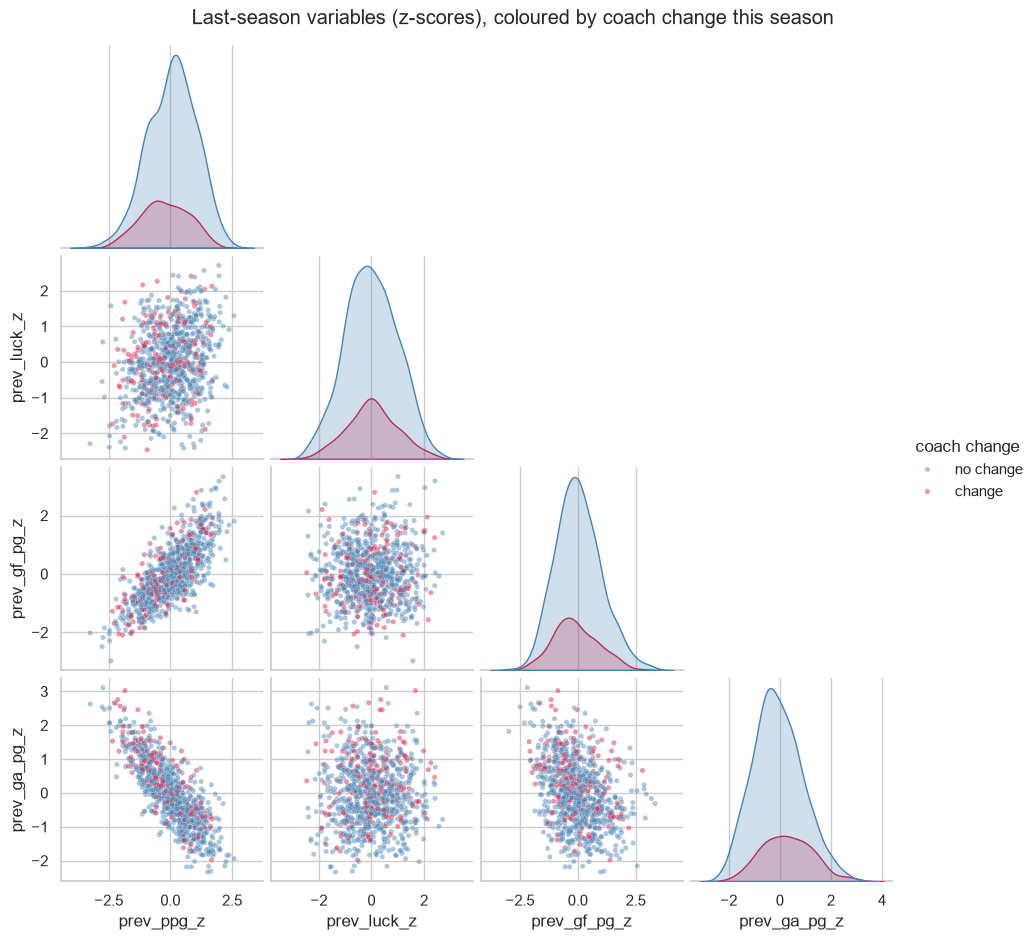

,prev_ppg_z,prev_luck_z,prev_gf_pg_z,prev_ga_pg_z
coach_change,,,,
0,0.06,-0.01,0.03,-0.08
1,-0.22,0.03,-0.09,0.29


In [43]:
# Pair plot of four last-season variables, coloured by coach change
cols = ['prev_ppg_z', 'prev_luck_z', 'prev_gf_pg_z', 'prev_ga_pg_z']
plot_df = pairs[cols + ['coach_change']].copy()
plot_df['coach change'] = plot_df['coach_change'].map({0: 'no change', 1: 'change'})
g = sns.pairplot(plot_df.drop(columns='coach_change'), hue='coach change', hue_order=['no change', 'change'],
                 palette={'no change': 'steelblue', 'change': 'crimson'}, diag_kind='kde', corner=True,
                 plot_kws={'s': 14, 'alpha': 0.45}, height=2.3)
g.figure.suptitle("Last-season variables (z-scores), coloured by coach change this season", y=1.02)
plt.show()
means = pairs.groupby('coach_change')[cols].mean().round(2)
display(means)

**What we found:** The two classes overlap strongly in every pair of variables. Mean z-scores of teams that changed coach (vs those that did not): points -0.22 (vs +0.06), goals against +0.29 (vs -0.08), goals for -0.09 (vs +0.03), luck +0.03 (vs -0.01). Changes are somewhat more frequent in the corner with low points and high goals against, but there is no region where a change is certain. Goals for and goals against both move with points (diagonal bands) and are partly related to each other.

this confirms the weak univariate and logistic results: a classifier will mostly rank risk and cannot draw a clean boundary. We therefore judge it by PR-AUC and top-quartile recall, not accuracy.

### 2.11 PCA biplot coloured by next-season points

Run PCA on eight last-season "style" variables (goals for and against, shots for and against, save percentage, power play, penalty kill, penalty minutes). The biplot shows teams in the first two components with loading arrows, coloured by next-season points. We use seasons from 1984 because shots against and save percentage exist only from 1983.

The eight variables are correlated. PCA compresses them into a few axes we can plot and name, and shows how much independent information there really is. Colouring by next-season points tells us whether the main axes carry predictive signal.

625 team-seasons with all eight style variables (seasons 1983-2008)
Variance explained: [0.4, 0.198, 0.132, 0.106, 0.072, 0.048, 0.042, 0.001]
Cumulative: [0.4, 0.597, 0.73, 0.836, 0.908, 0.956, 0.999, 1.0]


,PC1,PC2,PC3
gf_pg,-0.31,0.54,0.11
ga_pg,0.50,0.27,-0.02
shots_for_pg,-0.31,0.39,-0.25
shots_against_pg,0.36,0.08,0.57
save_pct,-0.36,-0.32,0.53
pp_pct,-0.30,0.49,0.20
pk_pct,-0.42,-0.27,0.17
pim_pg,0.16,0.25,0.50


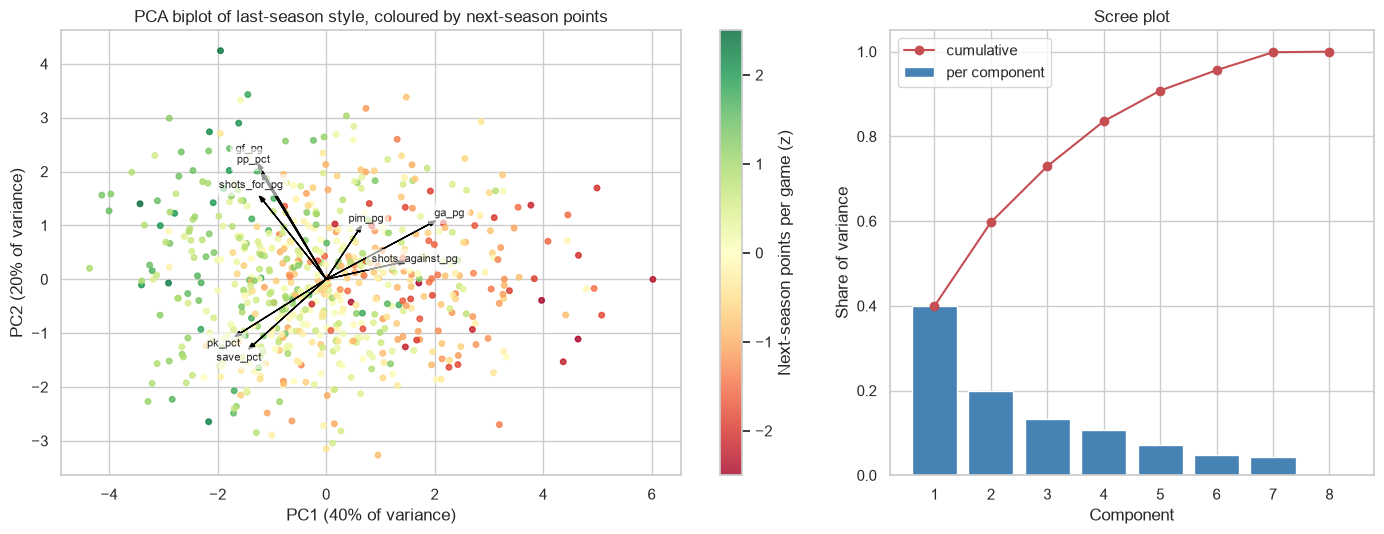

Spearman of PC1 with next-season points z: -0.564
Spearman of PC2 with next-season points z: 0.087
Spearman of PC3 with next-season points z: -0.088


In [44]:
from sklearn.decomposition import PCA

STYLE = ['prev_gf_pg_z', 'prev_ga_pg_z', 'prev_shots_for_pg_z', 'prev_shots_against_pg_z', 'prev_save_pct_z',
         'prev_pp_pct_z', 'prev_pk_pct_z', 'prev_pim_pg_z']
# Only seasons with all eight variables (shot data starts in 1983)
style = pairs.dropna(subset=STYLE).reset_index(drop=True)
print(f"{len(style)} team-seasons with all eight style variables (seasons {style['year'].min()}-{style['year'].max()})")

# Variance explained and loadings
pca = PCA().fit(style[STYLE])
scores = pca.transform(style[STYLE])
loads = pd.DataFrame(pca.components_[:3].T, index=[s.replace('prev_', '').replace('_z', '') for s in STYLE], columns=['PC1', 'PC2', 'PC3'])
print('Variance explained:', pca.explained_variance_ratio_.round(3).tolist())
print('Cumulative:', pca.explained_variance_ratio_.cumsum().round(3).tolist())
display(loads.round(2))

# Biplot coloured by next-season points + scree plot
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
sc = ax[0].scatter(scores[:, 0], scores[:, 1], c=style['ppg_z'].clip(-2.5, 2.5), cmap='RdYlGn', s=16, alpha=0.8)
for name, (x, y) in loads[['PC1', 'PC2']].iterrows():
    ax[0].arrow(0, 0, 4 * x, 4 * y, color='black', head_width=0.08, length_includes_head=True)
    ax[0].text(4.5 * x, 4.5 * y, name, ha='center', va='center', fontsize=8, bbox=dict(fc='white', alpha=0.6, lw=0))
plt.colorbar(sc, ax=ax[0], label='Next-season points per game (z)')
ax[0].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)',
          title="PCA biplot of last-season style, coloured by next-season points")
ax[1].bar(range(1, 9), pca.explained_variance_ratio_, color='steelblue', label='per component')
ax[1].plot(range(1, 9), pca.explained_variance_ratio_.cumsum(), 'ro-', label='cumulative')
ax[1].set(xlabel='Component', ylabel='Share of variance', title='Scree plot')
ax[1].legend()
plt.tight_layout()
plt.show()

# Which component carries signal for next season
for k in range(3):
    print(f"Spearman of PC{k+1} with next-season points z: {stats.spearmanr(scores[:, k], style['ppg_z'])[0]:.3f}")

**What we found:** 625 team-seasons (1983-2008) have all eight style variables. PC1 explains 40.0% of the variance, PC2 19.8%, PC3 13.2%, PC4 10.6%; five components reach 90.8%. PC1 separates weak from strong teams (loadings: goals against +0.50, penalty kill -0.42, save percentage -0.36, shots against +0.36, goals for -0.31), so a high PC1 means a leaky, weak team. PC2 is an offence axis (goals for +0.54, power play +0.49, shots for +0.39, save percentage -0.32). PC3 mixes shots against, save percentage and penalty minutes (+0.57, +0.53, +0.50): a team that concedes many shots and relies on its goalie. In the biplot the colour (next-season points) changes mostly along PC1: green on the left, red on the right. Spearman correlation with next-season points: PC1 -0.564, PC2 0.087, PC3 -0.088.

most of the predictive signal sits on the single strong-versus-weak axis; offence style (PC2) adds little linear signal. About five components are needed for 90% of the variance, so the eight variables are not fully redundant.

### 2.12 Clusters of team styles, with silhouette justification

K-means on the same eight style variables. We compare k = 2 to 8 with the silhouette score and inertia, choose k, and describe each cluster with a profile heatmap and a parallel-coordinates plot. Finally we test whether the coach-change rate and next-season points differ by cluster (chi-square, Kruskal-Wallis).

Clusters give named team types ("defensive", "open") that stakeholders understand, and show whether style adds information beyond last season's points. The silhouette score measures how well separated the clusters are (1 is perfect, 0 means overlapping).

Silhouette by k: {2: 0.222, 3: 0.174, 4: 0.155, 5: 0.138, 6: 0.131, 7: 0.129, 8: 0.133}


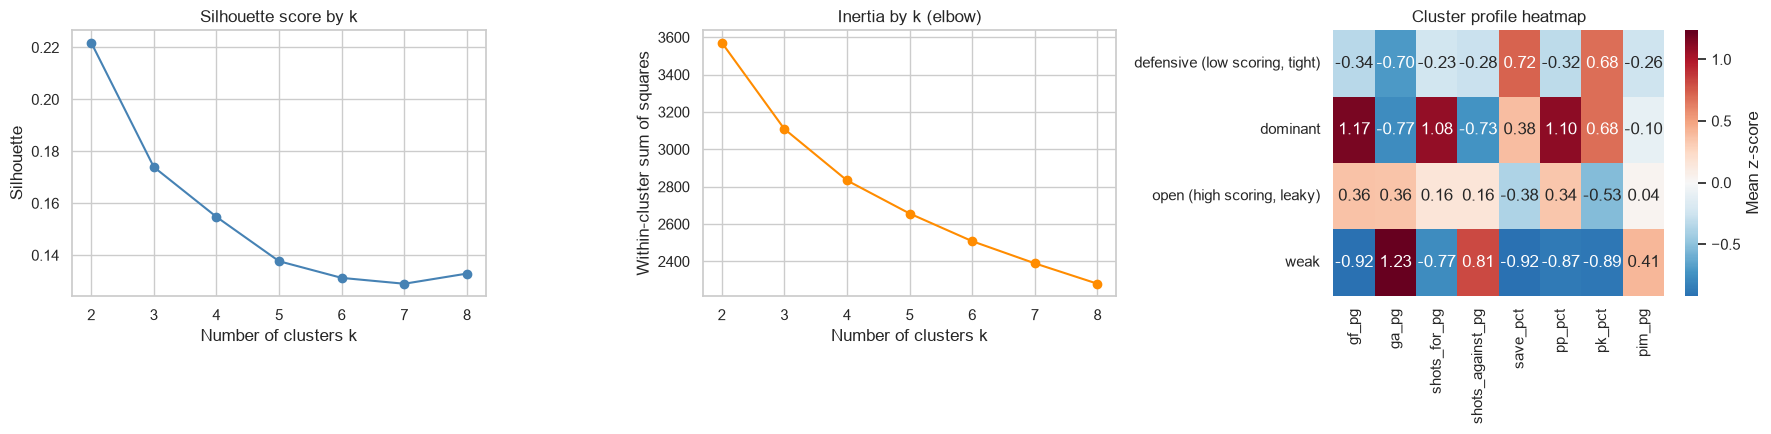

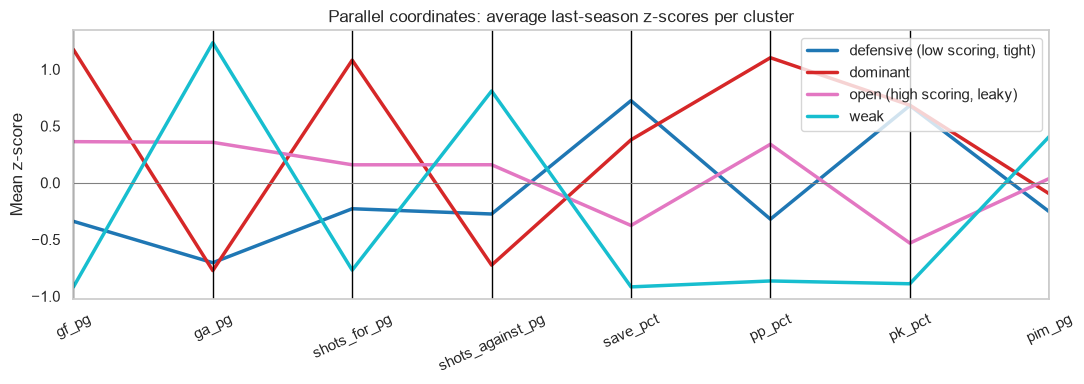

,teams,next_points_z,change_z,coach_change_rate
style,,,,
"defensive (low scoring, tight)",205,0.188,-0.086,0.146
dominant,110,0.888,-0.249,0.136
"open (high scoring, leaky)",175,-0.121,-0.084,0.229
weak,135,-0.770,0.524,0.244


Coach change by cluster: chi2 = 8.92, dof = 3, p = 0.0303
Next-season points z by cluster: Kruskal-Wallis H = 182.9, p = 2.13e-39


In [45]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from pandas.plotting import parallel_coordinates

# Silhouette and inertia for k = 2..8
Zs = style[STYLE]
sil, inertia = {}, {}
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=42).fit(Zs)
    sil[k], inertia[k] = silhouette_score(Zs, km.labels_), km.inertia_
print('Silhouette by k:', {k: round(v, 3) for k, v in sil.items()})

# Final k = 4. Name the clusters from their average goals for and against (see the profile heatmap below):
# best goal difference = dominant, worst = weak; of the two in the middle, the one with more goals at both ends = open
K = 4
km = KMeans(K, n_init=10, random_state=42).fit(Zs)
style['cluster'] = km.labels_
cent = style.groupby('cluster')[STYLE].mean()
goal_diff = cent['prev_gf_pg_z'] - cent['prev_ga_pg_z']    # how good the team is
goal_total = cent['prev_gf_pg_z'] + cent['prev_ga_pg_z']   # how open its games are
by_quality = goal_diff.sort_values().index.tolist()        # worst to best
weak, mid1, mid2, dominant = by_quality
if goal_total[mid1] >= goal_total[mid2]:
    open_c, defensive = mid1, mid2
else:
    open_c, defensive = mid2, mid1
names = {weak: 'weak', dominant: 'dominant', open_c: 'open (high scoring, leaky)', defensive: 'defensive (low scoring, tight)'}
style['style'] = style['cluster'].map(names)
profile = style.groupby('style')[STYLE].mean()
profile.columns = [c.replace('prev_', '').replace('_z', '') for c in STYLE]
profile['teams'] = style.groupby('style').size()

# Silhouette, elbow and profile heatmap
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(list(sil), list(sil.values()), 'o-', color='steelblue')
ax[0].set(title='Silhouette score by k', xlabel='Number of clusters k', ylabel='Silhouette')
ax[1].plot(list(inertia), list(inertia.values()), 'o-', color='darkorange')
ax[1].set(title='Inertia by k (elbow)', xlabel='Number of clusters k', ylabel='Within-cluster sum of squares')
sns.heatmap(profile.drop(columns='teams'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[2], cbar_kws={'label': 'Mean z-score'})
ax[2].set(title='Cluster profile heatmap', ylabel='')
plt.tight_layout()
plt.show()

# Parallel coordinates of the cluster averages
pc = profile.drop(columns='teams').reset_index()
fig, ax = plt.subplots(figsize=(11, 4))
parallel_coordinates(pc, 'style', colormap='tab10', ax=ax, linewidth=2.5)
ax.axhline(0, color='grey', lw=0.8)
ax.set(title='Parallel coordinates: average last-season z-scores per cluster', ylabel='Mean z-score')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Next-season outcomes per cluster, with chi-square and Kruskal-Wallis
out = style.groupby('style').agg(teams=('ppg_z', 'size'), next_points_z=('ppg_z', 'mean'), change_z=('change_z', 'mean'), coach_change_rate=('coach_change', 'mean'))
display(out.round(3))
ct = pd.crosstab(style['style'], style['coach_change'])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Coach change by cluster: chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4f}")
h, p2 = stats.kruskal(*[g['ppg_z'].values for _, g in style.groupby('style')])
print(f"Next-season points z by cluster: Kruskal-Wallis H = {h:.1f}, p = {p2:.2e}")

**What we found:** The silhouette score is low for every k (0.222 for k = 2, 0.174 for k = 3, 0.155 for k = 4, about 0.13 after) and the inertia curve has no clear elbow: team styles form a continuum, not separate groups. The silhouette alone would pick k = 2 (good against bad teams). With k = 4 we get four types (sizes in brackets): dominant (110; high scoring, tight defence, best power play), defensive (205; low scoring and low goals against, strong penalty kill and save percentage), open (175; more scoring and more goals against than average, weak penalty kill) and weak (135; low on almost everything). Next-season points z by cluster: +0.89, +0.19, -0.12, -0.77 (Kruskal-Wallis H = 182.9, p = 2e-39). Weak teams gain +0.52 SD on average (regression to the mean) while dominant teams lose 0.25. The coach-change rate differs by cluster (chi-square = 8.92, dof = 3, p = 0.030): open 22.9% and weak 24.4% against defensive 14.6% and dominant 13.6%.

**Decision:** k = 4 is used for description only, since the structure is weak. Cluster labels are not a feature: the other features carry the information and clusters fitted on all seasons would leak. The result that open, leaky teams change coach more often supports keeping goals-against and shots-against features.

### 2.13 Mutual information with both targets

Estimate the mutual information between each candidate feature and (a) next-season points (continuous target) and (b) coach change (binary target), and compare it to the absolute Spearman correlation. Mutual information is averaged over 5 random seeds.

Mutual information detects any kind of dependence (also non-linear), not only monotonic. If a feature has high mutual information but low correlation, a tree model might find something a linear model cannot. This is a first look; real feature selection is done inside folds in notebook 4.

,MI with next ppg,MI with coach change,|rho| next ppg,|rho| coach change
prev_ppg_z,0.283,0.024,0.622,0.118
prev_ga_pg_z,0.160,0.017,0.545,0.149
prev_shots_for_pg_z,0.124,0.000,0.379,0.015
prev_gf_pg_z,0.104,0.007,0.488,0.049
prev_pk_pct_z,0.080,0.000,0.403,0.136
prev_pp_pct_z,0.078,0.000,0.360,0.003
prev_save_pct_z,0.061,0.001,0.232,0.030
prev_shots_against_pg_z,0.059,0.013,0.348,0.104
prev_luck_z,0.018,0.000,0.030,0.017
coach_new,0.005,0.001,0.062,0.040


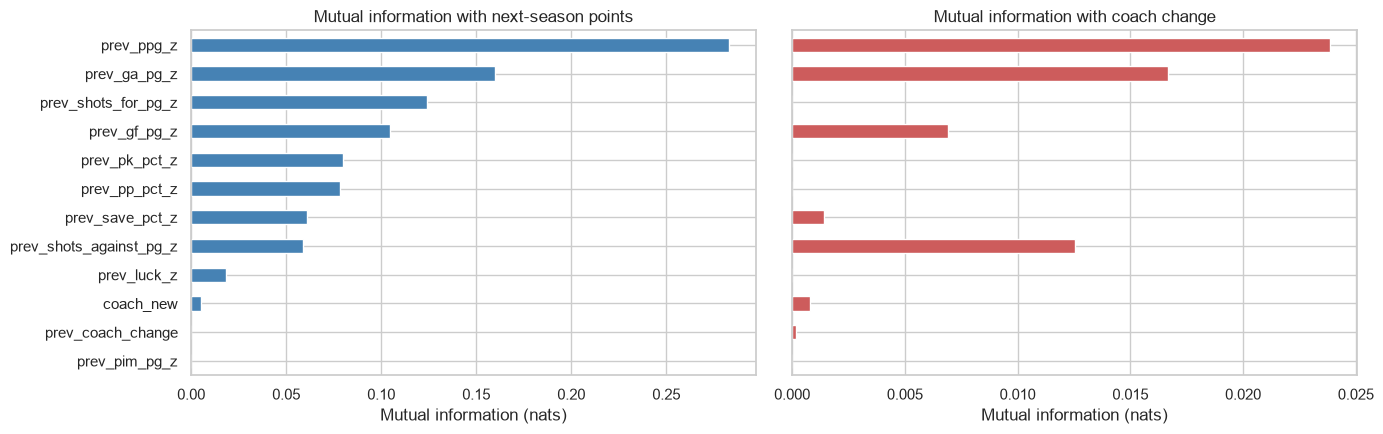

In [46]:
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif

# Mutual information averaged over 5 seeds (MI estimates are noisy)
mi_feats = feat + ['coach_new', 'prev_coach_change']
Xmi = pairs[mi_feats].fillna(pairs[mi_feats].median())
discrete = [f in ('coach_new', 'prev_coach_change') for f in mi_feats]
mi_ppg = np.mean([mutual_info_regression(Xmi, pairs['ppg_z'], discrete_features=discrete, random_state=s) for s in range(5)], axis=0)
mi_chg = np.mean([mutual_info_classif(Xmi, pairs['coach_change'], discrete_features=discrete, random_state=s) for s in range(5)], axis=0)
mi = pd.DataFrame({'MI with next ppg': mi_ppg, 'MI with coach change': mi_chg,
                   '|rho| next ppg': [abs(stats.spearmanr(Xmi[f], pairs['ppg_z'])[0]) for f in mi_feats],
                   '|rho| coach change': [abs(stats.spearmanr(Xmi[f], pairs['coach_change'])[0]) for f in mi_feats]}, index=mi_feats)
display(mi.sort_values('MI with next ppg', ascending=False).round(3))

# Bar charts for both targets
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
mi['MI with next ppg'].sort_values().plot.barh(ax=ax[0], color='steelblue')
ax[0].set(title='Mutual information with next-season points', xlabel='Mutual information (nats)')
mi['MI with coach change'].reindex(mi['MI with next ppg'].sort_values().index).plot.barh(ax=ax[1], color='indianred')
ax[1].set(title='Mutual information with coach change', xlabel='Mutual information (nats)')
plt.tight_layout()
plt.show()

**What we found:** For next-season points the most informative features are last season's points (MI = 0.283 nats), goals against (0.160), shots for (0.124), goals for (0.104), penalty kill (0.080) and power play (0.078); luck (0.018) and penalty minutes (0.000) carry almost nothing alone. For coach change all values are tiny: points 0.024, goals against 0.017, shots against 0.013, goals for 0.007 and the rest at or below 0.001. The order mostly agrees with the Spearman correlations, except that shots for ranks higher by MI than by correlation (0.124 vs |rho| 0.38).

the signal for points is strong and spread over several features, the signal for coach change is small. Luck has almost no MI alone although its partial effect was significant (2.9): MI, like a pairwise correlation, cannot see an effect that appears only after controlling for another variable. This is why real feature selection is done inside the folds in notebook 4.

### 2.14 Knowledge extracted from data understanding

| # | Insight | Evidence | What it means for the project |
|---|---|---|---|
| 1 | Era drift is large in goals (epsilon^2 = 0.42) and real in points (mean 1.000 to 1.084, SD 0.286 to 0.185) | Kruskal-Wallis, boxplots (2.4) | Standardize inside each season; never compare raw values across decades |
| 2 | About 38% of last season's distance from average is lost (slope 0.622, R^2 = 0.40) | OLS with CI, scatter, slopes by decade (2.6) | Last season is the best predictor but the persistence baseline is weak; models should shrink |
| 3 | Luck predicts a decline only after controlling for points (partial r = -0.172; raw r = 0.036) | Multiple OLS, F-test, added-variable plot (2.9) | Keep luck as a feature; univariate screening would have discarded it |
| 4 | Coach changes follow bad results and especially bad defence (bottom third 27.5% vs top third 16.3%; goals against rho = 0.15 vs goals for -0.05) | Mann-Whitney, chi-square, Spearman with BH correction (2.5, 2.7) | Defensive statistics are the key inputs for the classifier |
| 5 | In the logistic model one SD more points halves the odds (OR 0.495), but the model is weak (McFadden R^2 = 0.03, in-sample AUC 0.62) | statsmodels logit, forest plot (2.8) | Expect modest PR-AUC; judge recall at a useful precision, not accuracy |
| 6 | A new opening-day coach does not change the odds significantly (18.4% vs 22.0%, p = 0.28) | Chi-square (2.7), logistic (2.8) | Keep coach features but expect low importance |
| 7 | Team style is mostly one strength axis (PC1 = 40% of variance, rho = -0.56 with next points) and the types form a continuum (silhouette at most 0.22) | PCA biplot, k-means (2.11, 2.12) | Style gives only a small extra signal; open and weak teams change coach more (22.9% and 24.4% vs about 14%) |
| 8 | Points, goals for, goals against and luck are tightly linked, and mutual information puts points and goals against first (0.283, 0.160 nats) | Heatmap, MI (2.5, 2.13) | Redundancy removal is needed (3.7) |

**Visual summary.** The regression-to-the-mean scatter shows the fall-back at a glance; the pair plot shows that coach changes are not separable by a clean boundary; the biplot colour gradient follows PC1; the cluster heatmap names four team types.

## 3. Data preparation

From here we build the table that notebooks 2-4 will use: one row per NHL team-season (target year *t*), with features from season *t-1* and the opening-day coach, and two targets. Seasons up to 2008 drive every choice. 2009 stays untouched.

**Pipeline overview.** The diagram shows the order of the steps and where each one is done.

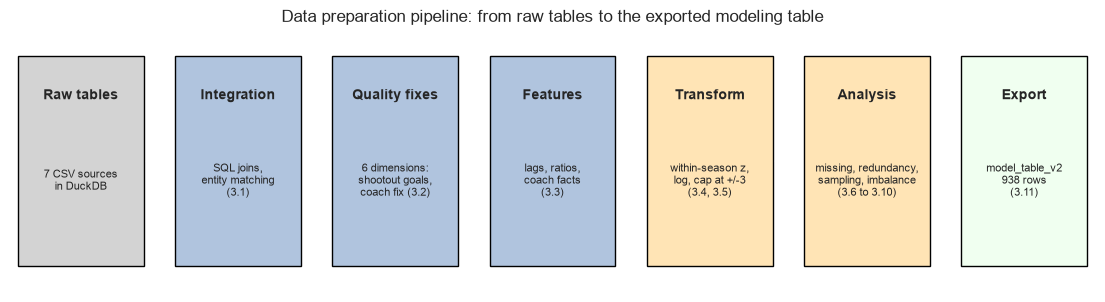

In [47]:
# Pipeline diagram
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.axis('off')
steps = [('Raw tables', '7 CSV sources\nin DuckDB', 'lightgrey'), ('Integration', 'SQL joins,\nentity matching\n(3.1)', 'lightsteelblue'),
         ('Quality fixes', '6 dimensions:\nshootout goals,\ncoach fix (3.2)', 'lightsteelblue'), ('Features', 'lags, ratios,\ncoach facts\n(3.3)', 'lightsteelblue'),
         ('Transform', 'within-season z,\nlog, cap at +/-3\n(3.4, 3.5)', 'moccasin'), ('Analysis', 'missing, redundancy,\nsampling, imbalance\n(3.6 to 3.10)', 'moccasin'),
         ('Export', 'model_table_v2\n938 rows\n(3.11)', 'honeydew')]
for i, (title, text, color) in enumerate(steps):
    x = i * 2.0
    ax.add_patch(plt.Rectangle((x, 0.2), 1.6, 1.6, facecolor=color, edgecolor='black'))
    ax.text(x + 0.8, 1.5, title, ha='center', va='center', fontweight='bold', fontsize=10)
    ax.text(x + 0.8, 0.85, text, ha='center', va='center', fontsize=8)
    if i < len(steps) - 1:
        ax.annotate('', xy=(x + 2.0, 1.0), xytext=(x + 1.6, 1.0), arrowprops=dict(arrowstyle='->'))
ax.set(xlim=(-0.1, 13.7), ylim=(0, 2), title='Data preparation pipeline: from raw tables to the exported modeling table')
plt.show()

### 3.1 Integration of seven sources with SQL

First we show the format conversions we need (text to number, birth date to age at season start, wide monthly columns to long format, ID matching). Then one SQL query joins Teams, TeamSplits, Scoring, Goalies, Master and SeriesPost into a team-season profile (Coaches is joined in 3.3). Finally we measure how well the entities match across sources.

The sources have different grains (team-season, player-season, goalie-season, coach-stint, series). Joining them directly would multiply rows, so each source is aggregated to team-season first and then joined on (year, league, team). We use franchID to link seasons, because the team code changes when a team moves.

In [48]:
# Format conversions in Master: which text values convert to numbers
master_csv = (ROOT / 'hockey_development_data' / 'Master.csv').as_posix()
parts = [f"""SELECT '{c}' AS column_name, count({c}) AS non_empty_text, count(TRY_CAST(TRY_CAST({c} AS DOUBLE) AS INTEGER)) AS cast_ok,
             any_value({c}) AS example_text FROM raw""" for c in ['birthYear', 'birthMon', 'height', 'weight']]
display(con.execute(f"WITH raw AS (SELECT * FROM read_csv('{master_csv}', all_varchar = true)) " + ' UNION ALL '.join(parts)).df())

# Age at season start (1 October)
print('Age at season start (1 October of the season year): season year + 0.75 minus birth year + (birth month - 1) / 12')
display(con.execute("""
SELECT m.firstName || ' ' || m.lastName AS player, s.year, m.birthYear, m.birthMon,
       round(s.year + 0.75 - (m.birthYear + (coalesce(m.birthMon, 6.5) - 1) / 12), 1) AS age_at_start
FROM Scoring s JOIN Master m ON s.playerID = m.playerID
WHERE s.lgID = 'NHL' AND s.year = 2008 AND s.tmID = 'PIT' ORDER BY s.Pts DESC LIMIT 4""").df())

# TeamSplits: 32 monthly columns -> long format
months = ['Sep', 'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr']
month_cols = [m + r for m in months for r in ['W', 'L', 'T', 'OL']]
month_sel = ', '.join(f'TRY_CAST({c} AS DOUBLE) AS {c}' for c in month_cols)
long = con.execute(f"""
SELECT year, tmID, regexp_extract(col, '^[A-Z][a-z]+') AS month, regexp_extract(col, '[A-Z]+$') AS result, val
FROM (UNPIVOT (SELECT year, tmID, {month_sel} FROM TeamSplits WHERE lgID = 'NHL' AND year = 2008 AND tmID = 'BOS')
      ON {', '.join(month_cols)} INTO NAME col VALUE val)""").df()
print('Monthly splits: 32 wide columns turned into long format (Boston 2008, wins and losses by month)')
display(long[long['result'].isin(['W', 'L'])].pivot(index='month', columns='result', values='val').reindex(months))
print('Note: the W-L-T record is stored in separate numeric columns in this database, so there is no "W-L-T" text string to split.')

# Previous NHL season for every season (2005 -> 2003)
con.execute("""CREATE OR REPLACE TABLE season_map AS
SELECT year, lag(year) OVER (ORDER BY year) AS prev_year, year - lag(year) OVER (ORDER BY year) AS prev_gap
FROM (SELECT DISTINCT year FROM Teams WHERE lgID = 'NHL')""")
display(con.execute("SELECT * FROM season_map WHERE prev_gap > 1 OR year IN (1967, 2009)").df())

,column_name,non_empty_text,cast_ok,example_text
0,birthYear,7251,7251,1975.0
1,birthMon,7214,7214,3.0
2,height,7048,7048,73.0
3,weight,7050,7050,210.0


Age at season start (1 October of the season year): season year + 0.75 minus birth year + (birth month - 1) / 12


,player,year,birthYear,birthMon,age_at_start
0,Evgeni Malkin,2008,1986.0,7.0,22.3
1,Sidney Crosby,2008,1987.0,8.0,21.2
2,Jordan Staal,2008,1988.0,9.0,20.1
3,Petr Sykora,2008,1976.0,11.0,31.9


Monthly splits: 32 wide columns turned into long format (Boston 2008, wins and losses by month)


result,L,W
month,,
Sep,NaN,NaN
Oct,3.0,5.0
Nov,1.0,11.0
Dec,1.0,12.0
Jan,3.0,8.0
Feb,4.0,6.0
Mar,5.0,7.0
Apr,2.0,4.0


Note: the W-L-T record is stored in separate numeric columns in this database, so there is no "W-L-T" text string to split.


,year,prev_year,prev_gap
0,1967,1966,1
1,2005,2003,2
2,2009,2008,1


**What we found:** All four Master text columns convert to numbers without failures (non-empty text values equal castable values: birth year 7,251, birth month 7,214, height 7,048, weight 7,050). Age at season start is a derived quantity, for example Malkin 22.3, Crosby 21.2, Staal 20.1 and Sykora 31.9 in 2008 (Pittsburgh). The 32 monthly columns of TeamSplits become a long table (Boston 2008 wins and losses per month; September is empty because the season starts in October). One monthly column (SepT) is entirely empty, so DuckDB reads it as text and the unpivot needed an explicit TRY_CAST, so all-empty columns need care when loading. The W-L-T record is stored in separate numeric columns, so no string splitting was needed. The season map shows the only bridged gap: 2005 uses 2003 (prev_gap = 2); 1967 uses 1966.

In [49]:
# The profile is built in small steps: one table per source with one row per team-season,
# then a final join. Goals for and against exclude shootout goals (see 3.2).

# Step 1: team stats from Teams
con.execute("""
CREATE OR REPLACE TABLE pf_team AS
SELECT year, lgID, tmID, franchID, G,
       Pts / G AS ppg,
       GF - coalesce(SoW, 0) AS gf_play,   -- goals scored in play (no shootout goals)
       GA - coalesce(SoL, 0) AS ga_play,
       PPG / PPC AS pp_pct,
       1 - PKG / PKC AS pk_pct,
       PIM / G AS pim_pg,
       (SHF - SHA) / G AS shorthanded_net_pg
FROM Teams
WHERE lgID = 'NHL'
""")

# Step 2: monthly results, from 32 wide columns (FebW, FebL, ...) to one row per team, month and result
con.execute(f"""
CREATE OR REPLACE TABLE pf_monthly AS
SELECT year, lgID, tmID,
       regexp_extract(col, '^[A-Z][a-z]+') AS month,   -- 'FebW' -> 'Feb'
       regexp_extract(col, '[A-Z]+$') AS result,       -- 'FebW' -> 'W'
       coalesce(val, 0) AS val
FROM (UNPIVOT (SELECT year, lgID, tmID, {month_sel} FROM TeamSplits WHERE lgID = 'NHL')
      ON {', '.join(month_cols)} INTO NAME col VALUE val)
""")

# Step 3: late-season form = win share in February-April minus win share over the whole season
con.execute("""
CREATE OR REPLACE TABLE pf_form AS
SELECT year, lgID, tmID,
       sum(CASE WHEN month IN ('Feb', 'Mar', 'Apr') AND result = 'W' THEN val END)
           / nullif(sum(CASE WHEN month IN ('Feb', 'Mar', 'Apr') THEN val END), 0) AS late_win_pct,
       sum(CASE WHEN result = 'W' THEN val END) / nullif(sum(val), 0) AS season_win_pct
FROM pf_monthly
GROUP BY year, lgID, tmID
""")

# Step 4: home edge = home win share minus road win share
con.execute("""
CREATE OR REPLACE TABLE pf_home AS
SELECT year, lgID, tmID,
       hW / (hW + hL + coalesce(hT, 0) + coalesce(hOTL, 0))
     - rW / (rW + rL + coalesce(rT, 0) + coalesce(rOTL, 0)) AS home_edge
FROM TeamSplits
WHERE lgID = 'NHL'
""")

# Step 5: playoff series won (every series has a winner and a loser)
con.execute("""
CREATE OR REPLACE TABLE pf_playoffs AS
WITH appearances AS (
    SELECT year, lgIDWinner AS lgID, tmIDWinner AS tmID, 1 AS won FROM SeriesPost
    UNION ALL
    SELECT year, lgIDLoser, tmIDLoser, 0 FROM SeriesPost)
SELECT year, lgID, tmID, sum(won) AS playoff_series_won, 1 AS made_playoffs
FROM appearances
GROUP BY year, lgID, tmID
""")

# Step 6: roster, first one row per skater and team-season, then one row per team-season
con.execute("""
CREATE OR REPLACE TABLE pf_player AS
SELECT s.year, s.lgID, s.tmID, s.playerID,
       sum(s.GP) AS gp, sum(s.Pts) AS pts, sum(s.G) AS goals, sum(s.SOG) AS shots,
       sum(CASE WHEN s.SOG IS NOT NULL THEN s.G END) AS goals_with_shots,   -- goals where shots were recorded
       any_value(s.year + 0.75 - (m.birthYear + (coalesce(m.birthMon, 6.5) - 1) / 12)) AS age   -- age on 1 October
FROM Scoring s
LEFT JOIN Master m ON s.playerID = m.playerID
WHERE s.lgID = 'NHL' AND s.pos IS DISTINCT FROM 'G'   -- skaters only
GROUP BY s.year, s.lgID, s.tmID, s.playerID
""")
con.execute("""
CREATE OR REPLACE TABLE pf_roster AS
SELECT year, lgID, tmID,
       count(*) AS players_used,
       sum(gp * age) / nullif(sum(CASE WHEN age IS NOT NULL THEN gp END), 0) AS roster_age,   -- weighted by games
       max(pts) / nullif(sum(pts), 0) AS top_scorer_share,
       sum(goals_with_shots) / nullif(sum(shots), 0) AS shooting_pct
FROM pf_player
GROUP BY year, lgID, tmID
""")

# Step 7: goalies, first one row per goalie and team-season, then one row per team-season
con.execute("""
CREATE OR REPLACE TABLE pf_goalie_player AS
SELECT year, lgID, tmID, playerID, sum(Min) AS minutes, sum(GA) AS ga, sum(SA) AS sa
FROM Goalies
WHERE lgID = 'NHL'
GROUP BY year, lgID, tmID, playerID
""")
con.execute("""
CREATE OR REPLACE TABLE pf_goalies AS
SELECT year, lgID, tmID,
       -- save % only if goalies with recorded shots played at least 95% of the minutes
       CASE WHEN sum(CASE WHEN sa IS NOT NULL THEN minutes END) / nullif(sum(minutes), 0) >= 0.95
            THEN 1 - sum(CASE WHEN sa IS NOT NULL THEN ga END) / sum(sa) END AS save_pct,
       max(minutes) / nullif(sum(minutes), 0) AS starter_minutes_share
FROM pf_goalie_player
GROUP BY year, lgID, tmID
""")

# Step 8: join everything to Teams (LEFT JOIN keeps every team-season)
con.execute("""
CREATE OR REPLACE TABLE profile AS
SELECT t.year, t.lgID, t.tmID, t.franchID, t.G,
       t.ppg,
       t.gf_play / t.G AS gf_pg,
       t.ga_play / t.G AS ga_pg,
       (t.gf_play - t.ga_play) / t.G AS gd_pg,
       t.gf_play ^ 2 / (t.gf_play ^ 2 + t.ga_play ^ 2) AS pythag,             -- Pythagorean expectation
       t.ppg / 2 - t.gf_play ^ 2 / (t.gf_play ^ 2 + t.ga_play ^ 2) AS luck,   -- points share minus expectation
       t.pp_pct, t.pk_pct, t.pim_pg, t.shorthanded_net_pg,
       h.home_edge,
       f.late_win_pct - f.season_win_pct AS late_form,
       coalesce(p.playoff_series_won, 0) AS playoff_series_won,
       coalesce(p.made_playoffs, 0) AS made_playoffs,
       r.players_used, r.roster_age, r.top_scorer_share, r.shooting_pct,
       g.save_pct,
       r.shooting_pct + g.save_pct AS pdo,
       g.starter_minutes_share,
       (t.G < 60)::INT AS short_season   -- the 1994 lockout season
FROM pf_team t
LEFT JOIN pf_home h USING (year, lgID, tmID)
LEFT JOIN pf_form f USING (year, lgID, tmID)
LEFT JOIN pf_playoffs p USING (year, lgID, tmID)
LEFT JOIN pf_roster r USING (year, lgID, tmID)
LEFT JOIN pf_goalies g USING (year, lgID, tmID)
""")

# The profile must have exactly one row per NHL row of Teams
profile = con.execute("SELECT * FROM profile ORDER BY year, tmID").df()
n_teams = con.execute("SELECT count(*) FROM Teams WHERE lgID = 'NHL'").fetchone()[0]
print(f"profile: {len(profile)} rows (Teams has {n_teams} NHL rows), {profile.shape[1]} columns; unique (year, tmID): {profile[['year', 'tmID']].drop_duplicates().shape[0]}")
display(profile[profile['year'] == 2008].sort_values('ppg', ascending=False).head(4).round(3))


profile: 1265 rows (Teams has 1265 NHL rows), 27 columns; unique (year, tmID): 1265


,year,lgID,tmID,franchID,G,ppg,gf_pg,ga_pg,gd_pg,pythag,luck,pp_pct,pk_pct,pim_pg,shorthanded_net_pg,home_edge,late_form,playoff_series_won,made_playoffs,players_used,roster_age,top_scorer_share,shooting_pct,save_pct,pdo,starter_minutes_share,short_season
1229,2008,NHL,SJS,SJS,82,1.427,3.061,2.427,0.634,0.614,0.099,0.242,0.833,12.841,0.012,0.268,-0.146,0.0,1,29,28.091,0.122,0.092,0.912,1.004,0.741,0
1207,2008,NHL,BOS,BOS,82,1.415,3.293,2.317,0.976,0.669,0.039,0.236,0.824,12.537,0.012,0.122,-0.115,1.0,1,29,27.463,0.120,0.109,0.927,1.035,0.657,0
1215,2008,NHL,DET,DET,82,1.366,3.524,2.927,0.598,0.592,0.091,0.255,0.783,10.049,0.024,0.073,-0.016,3.0,1,26,30.637,0.122,0.097,0.896,0.994,0.536,0
1234,2008,NHL,WAS,WAS,82,1.317,3.268,2.927,0.341,0.555,0.104,0.252,0.806,12.695,-0.049,0.195,-0.016,1.0,1,35,27.356,0.154,0.098,0.903,1.001,0.662,0


In [50]:
# Check that every source finds its team-season (match rate 1.0 = all rows matched)
match = con.execute("""
SELECT 'Scoring -> profile (team-season)' AS link, avg((p.tmID IS NOT NULL)::INT) AS match_rate, count(*) AS rows FROM Scoring s LEFT JOIN profile p ON s.year = p.year AND s.lgID = p.lgID AND s.tmID = p.tmID WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Goalies -> profile', avg((p.tmID IS NOT NULL)::INT), count(*) FROM Goalies s LEFT JOIN profile p ON s.year = p.year AND s.lgID = p.lgID AND s.tmID = p.tmID WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Coaches -> profile', avg((p.tmID IS NOT NULL)::INT), count(*) FROM Coaches s LEFT JOIN profile p ON s.year = p.year AND s.lgID = p.lgID AND s.tmID = p.tmID WHERE s.lgID = 'NHL'
UNION ALL SELECT 'TeamSplits -> profile', avg((p.tmID IS NOT NULL)::INT), count(*) FROM TeamSplits s LEFT JOIN profile p ON s.year = p.year AND s.lgID = p.lgID AND s.tmID = p.tmID WHERE s.lgID = 'NHL'
UNION ALL SELECT 'SeriesPost winners -> profile', avg((p.tmID IS NOT NULL)::INT), count(*) FROM SeriesPost s LEFT JOIN profile p ON s.year = p.year AND s.lgIDWinner = p.lgID AND s.tmIDWinner = p.tmID WHERE s.lgIDWinner = 'NHL'
UNION ALL SELECT 'Scoring.playerID -> Master', avg((m.playerID IS NOT NULL)::INT), count(*) FROM Scoring s LEFT JOIN Master m ON s.playerID = m.playerID WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Goalies.playerID -> Master', avg((m.playerID IS NOT NULL)::INT), count(*) FROM Goalies s LEFT JOIN Master m ON s.playerID = m.playerID WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Coaches.coachID -> Master', avg((m.coachID IS NOT NULL)::INT), count(*) FROM Coaches s LEFT JOIN Master m ON s.coachID = m.coachID WHERE s.lgID = 'NHL'
""").df()
display(match.round(4))

# Previous season found by team code vs by franchise
lag = con.execute("""
SELECT count(*) AS target_rows, sum((a.tmID IS NOT NULL)::INT) AS previous_season_by_tmID, sum((b.tmID IS NOT NULL)::INT) AS previous_season_by_franchID
FROM Teams t JOIN season_map m ON t.year = m.year
LEFT JOIN Teams a ON a.year = m.prev_year AND a.tmID = t.tmID AND a.lgID = 'NHL'
LEFT JOIN Teams b ON b.year = m.prev_year AND b.franchID = t.franchID AND b.lgID = 'NHL'
WHERE t.lgID = 'NHL' AND t.year >= 1967""").df()
display(lag)
print('NHL franchises that used more than one team code:',
      con.execute("SELECT count(*) FROM (SELECT franchID FROM Teams WHERE lgID = 'NHL' GROUP BY franchID HAVING count(DISTINCT tmID) > 1)").fetchone()[0])
display(con.execute("""SELECT franchID, string_agg(tmID, ' -> ' ORDER BY first) AS team_codes, min(first) AS first, max(last) AS last
FROM (SELECT franchID, tmID, min(year) AS first, max(year) AS last FROM Teams WHERE lgID = 'NHL' GROUP BY franchID, tmID)
GROUP BY franchID HAVING count(*) > 1 ORDER BY first LIMIT 6""").df())
# WHA teams that joined in 1979
print('WHA franchises that joined the NHL in 1979 (new entrants for NHL lags, even though franchID matches):')
display(con.execute("""SELECT w.franchID, w.tmID AS wha_code_1978, n.tmID AS nhl_code_1979, n.name
FROM Teams w JOIN Teams n ON w.franchID = n.franchID AND n.lgID = 'NHL' AND n.year = 1979 WHERE w.lgID = 'WHA' AND w.year = 1978""").df())

,link,match_rate,rows
0,Scoring -> profile (team-season),1.0,40101
1,Goalies -> profile,1.0,3678
2,Coaches -> profile,1.0,1522
3,TeamSplits -> profile,1.0,1265
4,SeriesPost winners -> profile,1.0,727
5,Scoring.playerID -> Master,1.0,40101
6,Goalies.playerID -> Master,1.0,3678
7,Coaches.coachID -> Master,1.0,1522


,target_rows,previous_season_by_tmID,previous_season_by_franchID
0,938,903.0,913.0


NHL franchises that used more than one team code: 13


,franchID,team_codes,first,last
0,STE,OTS -> STE,1917,1934
1,TOR,TOA -> TRS -> TOR,1917,2009
2,BKN,QUB -> HAM -> NYA -> BKN,1919,1941
3,PHQ,PIP -> PHQ,1925,1930
4,DET,DTC -> DTF -> DET,1926,2009
5,CLE,OAK -> CLF -> CLE,1967,1977


WHA franchises that joined the NHL in 1979 (new entrants for NHL lags, even though franchID matches):


,franchID,wha_code_1978,nhl_code_1979,name
0,EDM,EDO,EDM,Edmonton Oilers
1,CAR,NEW,HAR,Hartford Whalers
2,COL,QUN,QUE,Quebec Nordiques
3,PHO,WIJ,WIN,Winnipeg Jets


**What we found:** The profile table has 1,265 rows (one per NHL team-season, equal to Teams), 27 columns and no duplicated (year, team). Every source joins completely: Scoring (40,101 rows), Goalies (3,678), Coaches (1,522), TeamSplits (1,265) and SeriesPost winners (727) all find their team-season in 100% of rows, and playerID and coachID match Master in 100% of the rows of Scoring, Goalies and Coaches. Franchise identity matters: of the 938 target rows (1967-2009) the previous season is found for 903 rows by team code but for 913 by franchID, because 13 NHL franchises used more than one team code (for example TOA -> TRS -> TOR, DTC -> DTF -> DET, QUB -> HAM -> NYA -> BKN). The four WHA franchises that joined in 1979 (Edmonton, Hartford, Quebec, Winnipeg) share a franchID with their WHA team; since we filter on the NHL, they correctly have no NHL lag in 1979.

**Decision:** join seasons on (franchID, league = NHL) and the previous completed NHL season. Each source is aggregated to team-season before the join, and the result has exactly the Teams row count, so no join multiplied rows.

### 3.2 Data quality: six dimensions

One SQL check per dimension (several for the important ones), each returning how many rows are flagged out of how many were tested: completeness, uniqueness, validity, consistency, accuracy and timeliness. Then we apply the one correction we can prove (Phoenix 2009 coach) in a derived copy only.

Quality problems decide the cleaning rules. For example a mismatch between team goals and summed player goals only matters if we do not know the cause, so we test the suspected cause (shootout goals) too. Raw files are never edited.

In [51]:
# One SQL check per quality dimension; each returns (flagged, tested)
NHL = "lgID = 'NHL' AND year >= 1967"
NHL_T = "t.lgID = 'NHL' AND t.year >= 1967"
NHL_S = "s.lgID = 'NHL' AND s.year >= 1967"
checks = [
    ('completeness', 'Team-seasons missing power-play fields (PPG, PPC)', f"SELECT count(*) FILTER (WHERE PPG IS NULL OR PPC IS NULL), count(*) FROM Teams WHERE {NHL}"),
    ('completeness', 'Goalie rows missing shots against, 1967-1981', "SELECT count(*) FILTER (WHERE SA IS NULL), count(*) FROM Goalies WHERE lgID = 'NHL' AND year BETWEEN 1967 AND 1981"),
    ('completeness', 'Goalie rows missing shots against, 1982 onward', "SELECT count(*) FILTER (WHERE SA IS NULL), count(*) FROM Goalies WHERE lgID = 'NHL' AND year >= 1982"),
    ('completeness', 'NHL skater rows without birth year in Master', f"SELECT count(*) FILTER (WHERE m.birthYear IS NULL), count(*) FROM Scoring s LEFT JOIN Master m ON s.playerID = m.playerID WHERE {NHL_S}"),
    ('completeness', 'NHL coach rows without games (g)', f"SELECT count(*) FILTER (WHERE g IS NULL), count(*) FROM Coaches WHERE {NHL}"),
    ('uniqueness', 'Duplicate team-seasons (year, league, team)', "SELECT count(*) - count(DISTINCT (year, lgID, tmID)), count(*) FROM Teams"),
    ('uniqueness', 'Duplicate franchise-seasons in NHL (year, franchID)', "SELECT count(*) - count(DISTINCT (year, franchID)), count(*) FROM Teams WHERE lgID = 'NHL'"),
    ('uniqueness', 'Duplicate coach stints (coach, year, team, stint)', "SELECT count(*) - count(DISTINCT (coachID, year, tmID, stint)), count(*) FROM Coaches"),
    ('uniqueness', 'Coach rows sharing a stint with a co-coach (kept)', "SELECT count(*) FILTER (WHERE n > 1), count(*) FROM (SELECT count(*) OVER (PARTITION BY year, tmID, lgID, stint) AS n FROM Coaches WHERE lgID = 'NHL')"),
    ('uniqueness', 'Duplicate playerID in Master', "SELECT count(*) - count(DISTINCT playerID), count(*) FROM Master WHERE playerID IS NOT NULL"),
    ('validity', 'Team points per game outside 0 to 2', f"SELECT count(*) FILTER (WHERE Pts / G < 0 OR Pts / G > 2), count(*) FROM Teams WHERE {NHL}"),
    ('validity', 'More power-play (or penalty-kill) goals than chances', f"SELECT count(*) FILTER (WHERE PPG > PPC OR PKG > PKC), count(*) FROM Teams WHERE {NHL}"),
    ('validity', 'Goalie rows with more goals against than shots against', "SELECT count(*) FILTER (WHERE GA > SA), count(*) FROM Goalies WHERE SA IS NOT NULL"),
    ('validity', 'Skater age at season start outside 16 to 50', f"""SELECT count(*) FILTER (WHERE s.year + 0.75 - (m.birthYear + (coalesce(m.birthMon, 6.5) - 1) / 12) NOT BETWEEN 16 AND 50), count(*)
                                                                    FROM Scoring s JOIN Master m ON s.playerID = m.playerID WHERE {NHL_S} AND m.birthYear IS NOT NULL"""),
    ('validity', 'Player height outside 60-84 in or weight outside 120-300 lb', "SELECT count(*) FILTER (WHERE height NOT BETWEEN 60 AND 84 OR weight NOT BETWEEN 120 AND 300), count(height) FROM Master"),
    ('consistency', 'Team games differ from W + L + T + OTL', f"SELECT count(*) FILTER (WHERE G <> W + L + coalesce(T, 0) + coalesce(OTL, 0)), count(*) FROM Teams WHERE {NHL}"),
    ('consistency', 'Team points differ from 2W + T + OTL', f"SELECT count(*) FILTER (WHERE Pts <> 2 * W + coalesce(T, 0) + coalesce(OTL, 0)), count(*) FROM Teams WHERE {NHL}"),
    ('consistency', 'Home + road games differ from team games', f"SELECT count(*) FILTER (WHERE s.hW + s.hL + coalesce(s.hT, 0) + coalesce(s.hOTL, 0) + s.rW + s.rL + coalesce(s.rT, 0) + coalesce(s.rOTL, 0) <> t.G), count(*) FROM Teams t JOIN TeamSplits s ON t.year = s.year AND t.lgID = s.lgID AND t.tmID = s.tmID WHERE {NHL_T}"),
    ('consistency', 'Sum of coach games differs from team games', f"""SELECT count(*) FILTER (WHERE c.games <> t.G), count(*) FROM Teams t
                                                                    JOIN (SELECT year, lgID, tmID, sum(g) AS games FROM Coaches GROUP BY ALL) c ON t.year = c.year AND t.lgID = c.lgID AND t.tmID = c.tmID WHERE {NHL_T}"""),
    ('consistency', 'Player points differ from goals + assists', f"SELECT count(*) FILTER (WHERE Pts <> G + A), count(*) FROM Scoring WHERE {NHL}"),
    ('accuracy', 'Team goals for differ from summed player goals', f"""SELECT count(*) FILTER (WHERE t.GF <> s.goals), count(*) FROM Teams t
                                                                    JOIN (SELECT year, lgID, tmID, sum(G) AS goals FROM Scoring GROUP BY ALL) s ON t.year = s.year AND t.lgID = s.lgID AND t.tmID = s.tmID WHERE {NHL_T}"""),
    ('accuracy', '... same after adding shootout wins (SoW)', f"""SELECT count(*) FILTER (WHERE t.GF <> s.goals + coalesce(t.SoW, 0)), count(*) FROM Teams t
                                                                    JOIN (SELECT year, lgID, tmID, sum(G) AS goals FROM Scoring GROUP BY ALL) s ON t.year = s.year AND t.lgID = s.lgID AND t.tmID = s.tmID WHERE {NHL_T}"""),
    ('accuracy', 'Team goals against differ from goalie GA + empty-net + shootout losses', f"""SELECT count(*) FILTER (WHERE t.GA <> g.ga + coalesce(t.SoL, 0)), count(*) FROM Teams t
                                                                    JOIN (SELECT year, lgID, tmID, sum(GA + coalesce(ENG, 0)) AS ga FROM Goalies GROUP BY ALL) g ON t.year = g.year AND t.lgID = g.lgID AND t.tmID = g.tmID WHERE {NHL_T}"""),
    ('accuracy', 'Phoenix 2009 coach credited to Gretzky (Tippett coached the season)', "SELECT count(*) FILTER (WHERE coachID = 'gretzwa01c'), count(*) FROM Coaches WHERE year = 2009 AND tmID = 'PHO'"),
    ('timeliness', 'Core tables whose last season is before 2009', "SELECT count(*) FILTER (WHERE last_year < 2009), count(*) FROM (SELECT max(year) AS last_year FROM Teams UNION ALL SELECT max(year) FROM Scoring UNION ALL SELECT max(year) FROM Goalies UNION ALL SELECT max(year) FROM Coaches UNION ALL SELECT max(year) FROM SeriesPost UNION ALL SELECT max(year) FROM TeamSplits)"),
    ('timeliness', 'Calendar years 1967-2009 with no NHL season', "SELECT count(*) FILTER (WHERE s.year IS NULL), count(*) FROM generate_series(1967, 2009) g(y) LEFT JOIN (SELECT DISTINCT year FROM Teams WHERE lgID = 'NHL') s ON s.year = g.y"),
    ('timeliness', 'NHL seasons from 1967 whose previous season is more than 1 year back', "SELECT count(*) FILTER (WHERE prev_gap > 1), count(*) FROM season_map WHERE year >= 1967"),
    ('timeliness', 'Team-seasons recorded under the shootout rule (goal definition changed)', f"SELECT count(*) FILTER (WHERE SoW IS NOT NULL), count(*) FROM Teams WHERE {NHL}"),
]
# Run all checks
rows = []
for dim, name, sql in checks:
    flagged, total = con.execute(sql).fetchone()
    rows.append({'dimension': dim, 'check': name, 'flagged': int(flagged), 'out of': int(total), 'share': round(flagged / total, 4) if total else None})
quality = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 90)
display(quality)

# Phoenix 2009 fix, only in a derived copy
con.execute("CREATE OR REPLACE TABLE coaches_clean AS SELECT * REPLACE (CASE WHEN coachID = 'gretzwa01c' AND year = 2009 AND tmID = 'PHO' THEN 'tippeda01c' ELSE coachID END AS coachID) FROM Coaches")
print('After the fix in the derived copy (raw Coaches unchanged):',
      con.execute("SELECT (SELECT count(*) FROM Coaches WHERE coachID = 'gretzwa01c' AND year = 2009), (SELECT count(*) FROM coaches_clean WHERE coachID = 'gretzwa01c' AND year = 2009), (SELECT count(*) FROM coaches_clean WHERE coachID = 'tippeda01c' AND year = 2009)").fetchone(),
      '(raw Gretzky rows, clean Gretzky rows, clean Tippett rows in 2009)')

,dimension,check,flagged,out of,share
0,completeness,"Team-seasons missing power-play fields (PPG, PPC)",0,938,0.0000
1,completeness,"Goalie rows missing shots against, 1967-1981",783,783,1.0000
2,completeness,"Goalie rows missing shots against, 1982 onward",6,2254,0.0027
3,completeness,NHL skater rows without birth year in Master,0,32741,0.0000
4,completeness,NHL coach rows without games (g),1,1161,0.0009
5,uniqueness,"Duplicate team-seasons (year, league, team)",0,1459,0.0000
6,uniqueness,"Duplicate franchise-seasons in NHL (year, franchID)",0,1265,0.0000
7,uniqueness,"Duplicate coach stints (coach, year, team, stint)",0,1741,0.0000
8,uniqueness,Coach rows sharing a stint with a co-coach (kept),2,1522,0.0013
9,uniqueness,Duplicate playerID in Master,0,7236,0.0000


After the fix in the derived copy (raw Coaches unchanged): (1, 0, 1) (raw Gretzky rows, clean Gretzky rows, clean Tippett rows in 2009)


**What we found** (flagged rows out of rows tested):
- **Completeness:** no NHL team-season since 1967 lacks power-play fields (0 of 938). Goalie shots against are missing for all 783 goalie rows of 1967-1981 and for 6 of 2,254 rows from 1982 on (0.27%). One coach row has no games (Ottawa 2001, stint 3 of a returning coach). Every NHL skater has a birth year.
- **Uniqueness:** 0 duplicate team-seasons, franchise-seasons, coach stints or Master IDs. Two coach rows share a stint (Detroit 1998 co-coaches) and are kept.
- **Validity:** no impossible rates, goals or shots; one skater age outside 16-50 (Gordie Howe, 51 in 1979, a real case); all heights and weights plausible.
- **Consistency:** games and points follow the W/L/T/OTL rules in all 938 rows; home plus road games equal team games in all rows; player points equal goals plus assists everywhere. The coach game sum differs from the team games in 1 row (Detroit 1998: the two co-coaches each count the same 5 games, 87 vs 82).
- **Accuracy:** team goals for differ from summed player goals in 149 of 938 rows (15.9%); after adding shootout wins the difference is 0, so team totals count one goal per shootout win from 2005. Team goals against differ in 1 row (Detroit 2005, kept). The Phoenix 2009 coach is credited to Gretzky, but Tippett coached the team.
- **Timeliness:** all 6 core tables end in 2009. One calendar year has no NHL season (2004, lockout), so one season (2005) has its previous season 2 years back. 150 of 938 team-seasons follow the shootout rule, so definitions change over time.

**Decisions:** (1) goal features use goals in play (GF minus SoW, GA minus SoL), comparable across the 2005 rule change. (2) The Phoenix 2009 coach is corrected to tippeda01c in the derived table coaches_clean only (raw: 1 Gretzky row; clean: 0 Gretzky, 1 Tippett); raw files stay unchanged. (3) Co-coaches stay as rows; the opening-day coach is the stint-1 coach with the most games. (4) Save-percentage features are missing before 1982 by construction (handled in 3.6). (5) The single missing coach games value does not affect the target, which counts stints.

### 3.3 Feature engineering: lags, business concepts and opening-day coach facts

Build the final team-season table. Each row is a target season *t*. Features come from the previous completed NHL season of the same franchise (2005 uses 2003 with prev_gap = 2, nothing else is bridged) plus coach facts known on opening day. We use two kinds of engineered features: aggregations of detailed tables (roster age, top-scorer share, goalie starter share, late-season form) and business concepts (luck = points minus Pythagorean expectation, PDO-like shooting plus save percentage, home edge, special teams, playoff success).

Coaches and analysts reason with such concepts (a lucky team will regress, a team that was strong late in the year has momentum). Raw tables do not contain them. Every feature is built from season *t-1* or from opening-day coach facts, never from season *t* results.

In [52]:
PROFILE_FEATURES = ['ppg', 'gf_pg', 'ga_pg', 'gd_pg', 'pythag', 'luck', 'pp_pct', 'pk_pct', 'pim_pg', 'shorthanded_net_pg', 'home_edge',
                    'late_form', 'playoff_series_won', 'made_playoffs', 'players_used', 'roster_age', 'top_scorer_share',
                    'shooting_pct', 'save_pct', 'pdo', 'starter_minutes_share', 'short_season']

# Coach per franchise-season from the corrected copy
con.execute(COACH_SQL.format(name='coach_season', src='coaches_clean'))
# Coach career record before each season: for each coach and season, add up all his EARLIER seasons
# (the window runs from his first season up to the season before, never the current one)
con.execute("""
CREATE OR REPLACE TABLE coach_career AS
SELECT coachID, year,
       coalesce(sum(g_year) OVER w, 0) AS coach_career_games,
       (2 * coalesce(sum(w_year) OVER w, 0) + coalesce(sum(t_year) OVER w, 0)) / nullif(2 * sum(g_year) OVER w, 0) AS coach_career_pct
FROM (SELECT coachID, year, sum(g) AS g_year, sum(w) AS w_year, sum(coalesce(t, 0)) AS t_year FROM coaches_clean GROUP BY coachID, year)
WINDOW w AS (PARTITION BY coachID ORDER BY year ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)""")

# Opening-day coach facts: is the coach new, how long has he been with the team, did the team change coach last season
cs = con.execute("SELECT c.*, m.prev_year FROM coach_season c JOIN season_map m USING (year) ORDER BY year").df()
last = cs[['year', 'franchID', 'start_coach', 'end_coach', 'stints']].rename(columns={
    'year': 'prev_year', 'start_coach': 'prev_start_coach', 'end_coach': 'prev_end_coach', 'stints': 'prev_stints'})
cs = cs.merge(last, on=['prev_year', 'franchID'], how='left')
has_prev_coach = cs['prev_end_coach'].notna()   # False for new franchises
cs['coach_new'] = (cs['start_coach'] != cs['prev_end_coach']).astype(float).where(has_prev_coach)
cs['prev_coach_change'] = (cs['prev_stints'] > 1).astype(float).where(has_prev_coach)

# Tenure = earlier seasons in a row with this franchise. It builds on last season's value, so we go season by season.
tenure = {}
for r in cs.itertuples():
    if r.coach_new != 0:                      # new coach, or no previous season
        tenure[(r.year, r.franchID)] = 0
    elif r.prev_start_coach == r.start_coach:  # he coached the whole of last season
        tenure[(r.year, r.franchID)] = tenure[(r.prev_year, r.franchID)] + 1
    else:                                     # he took over during last season
        tenure[(r.year, r.franchID)] = 1
cs['coach_tenure'] = [tenure[(y, f)] for y, f in zip(cs['year'], cs['franchID'])]
con.register('coach_feat', cs[['year', 'franchID', 'start_coach', 'stints', 'coach_new', 'coach_tenure', 'prev_coach_change']])

# Final table: features from season t-1, coach facts, targets of season t
prev_cols = ', '.join(f'p.{f} AS prev_{f}' for f in PROFILE_FEATURES)
con.execute(f"""
CREATE OR REPLACE TABLE team_season AS
SELECT t.year, t.lgID, t.tmID, t.franchID, t.name, t.confID, t.divID, t.G AS games, m.prev_year, m.prev_gap,
       (p.tmID IS NOT NULL)::INT AS has_prev, {prev_cols},
       f.start_coach, f.coach_new, f.coach_tenure, coalesce(k.coach_career_games, 0) AS coach_career_games, k.coach_career_pct, f.prev_coach_change,
       t.Pts / t.G AS target_ppg, t.Pts AS target_points, t."rank" AS target_rank_division,
       rank() OVER (PARTITION BY t.year ORDER BY t.Pts DESC) AS target_rank_league,
       (f.stints > 1)::INT AS target_coach_change
FROM Teams t
JOIN season_map m ON t.year = m.year
LEFT JOIN profile p ON p.year = m.prev_year AND p.franchID = t.franchID AND p.lgID = 'NHL'
LEFT JOIN coach_feat f ON f.year = t.year AND f.franchID = t.franchID
LEFT JOIN coach_career k ON k.coachID = f.start_coach AND k.year = t.year
WHERE t.lgID = 'NHL' AND t.year >= 1967""")
frame = con.execute("SELECT * FROM team_season ORDER BY year, tmID").df()
# No duplicates, and the previous season is always earlier
assert frame[['year', 'tmID']].duplicated().sum() == 0
assert (frame.loc[frame['has_prev'] == 1, 'prev_year'] < frame.loc[frame['has_prev'] == 1, 'year']).all()
print(f"team_season: {frame.shape[0]} rows x {frame.shape[1]} columns | rows with a previous season: {int(frame['has_prev'].sum())} | prev_gap counts: {frame['prev_gap'].value_counts().to_dict()}")
print('Rows with a coach row but target_coach_change missing:', int(frame['target_coach_change'].isna().sum()))

# Feature dictionary
dictionary = pd.DataFrame([
    ('prev_ppg, prev_gf_pg, prev_ga_pg, prev_gd_pg', 'aggregation', 'Teams', 'Points, goals for and against per game (shootout goals removed), goal difference per game, all of season t-1'),
    ('prev_pythag, prev_luck', 'business concept', 'Teams', 'Pythagorean expectation GF^2 / (GF^2 + GA^2); luck = points share minus expectation'),
    ('prev_pp_pct, prev_pk_pct, prev_shorthanded_net_pg, prev_pim_pg', 'business concept', 'Teams', 'Power-play %, penalty-kill %, net short-handed goals, penalty minutes per game'),
    ('prev_home_edge', 'business concept', 'TeamSplits', 'Home win share minus road win share'),
    ('prev_late_form', 'aggregation (wide to long)', 'TeamSplits', 'Win share in Feb-Apr minus season win share (from 32 monthly columns)'),
    ('prev_playoff_series_won, prev_made_playoffs', 'aggregation', 'SeriesPost', 'Playoff series won and a playoff flag in season t-1'),
    ('prev_players_used, prev_roster_age', 'aggregation', 'Scoring + Master', 'Skaters used; games-weighted average age at season start (birth date to age)'),
    ('prev_top_scorer_share', 'aggregation', 'Scoring', 'Top scorer points divided by team points of all skaters (concentration)'),
    ('prev_shooting_pct, prev_save_pct, prev_pdo', 'business concept', 'Scoring, Goalies', 'Shooting % + save % (PDO-like); luck indicator of puck bounces'),
    ('prev_starter_minutes_share', 'aggregation', 'Goalies', 'Minutes of the busiest goalie divided by all goalie minutes'),
    ('prev_short_season', 'flag', 'Teams', 'Season t-1 had fewer than 60 games (1994 lockout)'),
    ('coach_new', 'opening-day fact', 'Coaches', 'Stint-1 coach of season t differs from the last coach of season t-1'),
    ('coach_tenure', 'opening-day fact', 'Coaches', 'Consecutive earlier seasons the same coach has been with the franchise'),
    ('coach_career_games, coach_career_pct', 'opening-day fact', 'Coaches', 'Games coached and points share in all seasons before t (any league)'),
    ('prev_coach_change', 'lag', 'Coaches', 'Franchise changed coach during season t-1'),
], columns=['feature(s)', 'kind', 'source', 'definition'])
pd.set_option('display.max_colwidth', 120)
display(dictionary)
cols_2008 = ['year', 'tmID', 'prev_year', 'prev_ppg', 'prev_luck', 'prev_pdo', 'prev_roster_age', 'coach_new', 'coach_tenure', 'coach_career_games', 'coach_career_pct']
display(frame[frame['year'] == 2005].head(3)[cols_2008].round(3))

team_season: 938 rows x 44 columns | rows with a previous season: 913 | prev_gap counts: {1: 908, 2: 30}
Rows with a coach row but target_coach_change missing: 0


,feature(s),kind,source,definition
0,"prev_ppg, prev_gf_pg, prev_ga_pg, prev_gd_pg",aggregation,Teams,"Points, goals for and against per game (shootout goals removed), goal difference per game, all of season t-1"
1,"prev_pythag, prev_luck",business concept,Teams,Pythagorean expectation GF^2 / (GF^2 + GA^2); luck = points share minus expectation
2,"prev_pp_pct, prev_pk_pct, prev_shorthanded_net_pg, prev_pim_pg",business concept,Teams,"Power-play %, penalty-kill %, net short-handed goals, penalty minutes per game"
3,prev_home_edge,business concept,TeamSplits,Home win share minus road win share
4,prev_late_form,aggregation (wide to long),TeamSplits,Win share in Feb-Apr minus season win share (from 32 monthly columns)
5,"prev_playoff_series_won, prev_made_playoffs",aggregation,SeriesPost,Playoff series won and a playoff flag in season t-1
6,"prev_players_used, prev_roster_age",aggregation,Scoring + Master,Skaters used; games-weighted average age at season start (birth date to age)
7,prev_top_scorer_share,aggregation,Scoring,Top scorer points divided by team points of all skaters (concentration)
8,"prev_shooting_pct, prev_save_pct, prev_pdo",business concept,"Scoring, Goalies",Shooting % + save % (PDO-like); luck indicator of puck bounces
9,prev_starter_minutes_share,aggregation,Goalies,Minutes of the busiest goalie divided by all goalie minutes


,year,tmID,prev_year,prev_ppg,prev_luck,prev_pdo,prev_roster_age,coach_new,coach_tenure,coach_career_games,coach_career_pct
788,2005,ANA,2003,0.927,0.036,0.991,27.566,1.0,0,0.0,NaN
789,2005,ATL,2003,0.951,0.039,1.004,26.858,0.0,2,480.0,0.574
790,2005,BOS,2003,1.268,0.081,1.003,28.630,0.0,1,82.0,0.591


**What we found:** The final table has 938 rows (NHL target seasons 1967-2009) and 44 columns before transformation. 913 rows have a previous season; the 25 first seasons of expansion franchises (1967-2008) have none. prev_gap is 1 in 908 rows and 2 in 30 rows (all 2005 teams, which use 2003). No row has a missing target_coach_change. The dictionary lists 15 groups: aggregations of detailed tables (roster age, top-scorer share, goalie starter share, late-season form from 32 monthly columns, playoff series won), business concepts (Pythagorean luck, PDO-like shooting plus save percentage, home edge, special teams) four opening-day coach facts (plus last season's coach change). In the 2005 sample, Anaheim's coach is new with no career games (a first-time coach), while Atlanta's coach has 480 career games and a points share of 0.574.

No feature uses season-t results: every prev_* value comes from prev_year < year (asserted for each row) and the coach facts use only the stint-1 coach and records before season t.

### 3.4 Transformation: within-season z-scores, a skewed variable and a discretization

(1) Convert every team statistic of season *t-1* into a z-score computed among the teams of that same season, and show the effect before and after with boxplots and Kruskal-Wallis tests. (2) Log-transform the very skewed coach career games. (3) Show a discretization of points into quartile tiers, used for analysis and communication.

**Why z-scores inside the season.** Section 2.4 showed that levels shift by era (goals per game, and points per game after the overtime-loss rule). A z-score asks "how good was this team compared with the league *that season*", which is the question that matters for a ranking. Each season is standardized on its own teams only, so no information flows from other seasons or from the test set (nothing is fitted across seasons).

**Which algorithms need scaling.** Distance and gradient methods need comparable scales: Ridge/Lasso/logistic regression (penalties depend on scale), k-NN, SVM, neural networks, PCA, k-means. Tree-based methods (decision tree, random forest, gradient boosting) do not need scaling because they only compare values inside one feature. Naive Bayes with categorical inputs needs discretization; trees do not. Because we want to compare several families, the table carries z-scores and notebooks 2 and 3 add a StandardScaler inside the pipeline where required.

**Why discretize.** Quartile tiers (bottom 25%, ..., top 25%) are easy to explain and let us test transitions with a chi-square test. We do not model with the tiers: they throw away the exact distance between teams that the ranking needs.

Cross-check with the section 2 table: max difference in prev_ppg_z = 0.0e+00, prev_luck_z = 7.6e-15 (883 rows)
    prev_gf_pg: Kruskal-Wallis across decades H =  373.8, p = 1.25e-79
  prev_gf_pg_z: Kruskal-Wallis across decades H =    0.0, p = 1
      prev_ppg: Kruskal-Wallis across decades H =   21.1, p = 0.000303
    prev_ppg_z: Kruskal-Wallis across decades H =    0.2, p = 0.996


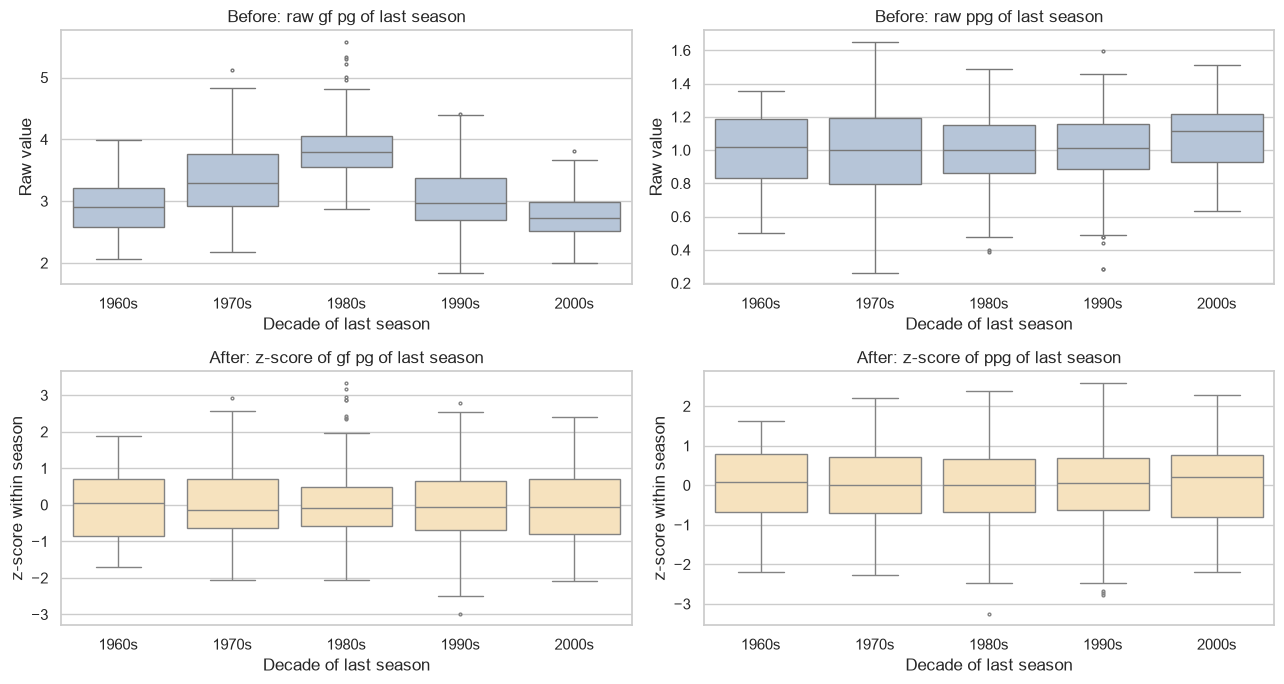

Skewness of coach career games: raw 1.56 -> log1p -1.39


next_tier,bottom 25%,lower-middle,upper-middle,top 25%
prev_tier,,,,
bottom 25%,0.56,0.26,0.14,0.04
lower-middle,0.28,0.35,0.25,0.12
upper-middle,0.14,0.28,0.32,0.25
top 25%,0.02,0.11,0.28,0.59


Quartile tier last season vs this season: chi2 = 341.4, dof = 9, p = 4.17e-68, Cramer's V = 0.359


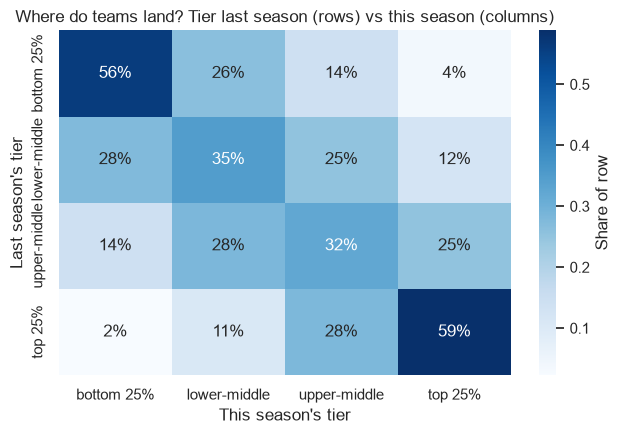

In [53]:
from scipy.stats import skew
def zscore(s):
    return (s - s.mean()) / s.std()

Z_FEATURES = [f for f in PROFILE_FEATURES if f not in ('made_playoffs', 'short_season')]
# z-scores of last season's stats inside their own season
prof = profile.copy()
for f in Z_FEATURES:
    prof[f + '_z'] = prof.groupby('year')[f].transform(zscore)
prev_z = prof[['year', 'franchID'] + [f + '_z' for f in Z_FEATURES]].rename(
    columns={'year': 'prev_year', **{f + '_z': 'prev_' + f + '_z' for f in Z_FEATURES}})
frame = frame.merge(prev_z, on=['prev_year', 'franchID'], how='left')
frame['target_ppg_z'] = frame.groupby('year')['target_ppg'].transform(zscore)
frame['coach_career_games_log'] = np.log1p(frame['coach_career_games'])

# Should match the table from section 2
chk = frame.merge(pairs[['year', 'tmID', 'prev_ppg_z', 'prev_luck_z']], on=['year', 'tmID'], suffixes=('', '_du'))
print(f"Cross-check with the section 2 table: max difference in prev_ppg_z = {np.abs(chk['prev_ppg_z'] - chk['prev_ppg_z_du']).max():.1e}, prev_luck_z = {np.abs(chk['prev_luck_z'] - chk['prev_luck_z_du']).max():.1e} ({len(chk)} rows)")

# Before/after boxplots by decade
d = frame[(frame['year'] <= 2008) & (frame['has_prev'] == 1)].copy()
d['prev_decade'] = (d['prev_year'] // 10 * 10).astype(int).astype(str) + 's'
order = sorted(d['prev_decade'].unique())
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for j, f in enumerate(['prev_gf_pg', 'prev_ppg']):
    for i, col in enumerate([f, f + '_z']):
        sns.boxplot(data=d, x='prev_decade', y=col, order=order, ax=ax[i, j], color='lightsteelblue' if i == 0 else 'moccasin', fliersize=2)
        ax[i, j].set(title=('Before: raw ' if i == 0 else 'After: z-score of ') + f.replace('prev_', '').replace('_', ' ') + ' of last season',
                     xlabel='Decade of last season', ylabel='Raw value' if i == 0 else 'z-score within season')
        h, p = stats.kruskal(*[g[col].dropna().values for _, g in d.groupby('prev_decade')])
        print(f"{col:>14}: Kruskal-Wallis across decades H = {h:6.1f}, p = {p:.3g}")
plt.tight_layout()
plt.show()

print(f"Skewness of coach career games: raw {skew(frame['coach_career_games']):.2f} -> log1p {skew(frame['coach_career_games_log']):.2f}")

# Quartile tiers: where teams land next season
labels = ['bottom 25%', 'lower-middle', 'upper-middle', 'top 25%']
d['prev_tier'] = pd.qcut(d['prev_ppg_z'], 4, labels=labels)
d['next_tier'] = pd.qcut(d['target_ppg_z'], 4, labels=labels)
ct = pd.crosstab(d['prev_tier'], d['next_tier'])
display(ct.div(ct.sum(axis=1), axis=0).round(2))
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Quartile tier last season vs this season: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramer's V = {np.sqrt(chi2 / (ct.values.sum() * 3)):.3f}")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=True, fmt='.0%', cmap='Blues', ax=ax, cbar_kws={'label': 'Share of row'})
ax.set(title='Where do teams land? Tier last season (rows) vs this season (columns)', xlabel="This season's tier", ylabel="Last season's tier")
plt.tight_layout()
plt.show()

**What we found:** Before standardizing, last season's goals for differ strongly by decade (Kruskal-Wallis H = 373.8, p = 1e-79) and points per game moderately (H = 21.1, p = 0.0003). After the within-season z-score both differences vanish (H = 0.0, p = 1 and H = 0.2, p = 0.996). The z-scores are identical to the section 2 table (maximum difference 0). Coach career games has skewness 1.56 raw and -1.39 after log1p: the log shrinks the long right tail (coaches with thousands of games), but the sign flips because first-time coaches (about 13% of rows) pile up at zero, so the transformation tames outliers without making the variable normal. The tier table shows persistence and regression to the mean: 56% of bottom-quartile teams and 59% of top-quartile teams stay in their tier, only 4% of the bottom jump to the top and 2% of the top fall to the bottom (chi-square = 341.4, dof = 9, p = 4e-68, Cramer's V = 0.36).

**Decision:** the exported features are within-season z-scores (extremes capped in 3.5) and coach career games is stored as log1p. Scale-sensitive models (Ridge, logistic, k-NN, SVM, neural networks) also get a StandardScaler inside their pipeline for the binary and coach columns; tree models use the same table unscaled. The tiers are for analysis and communication only: models predict points per game.

#### 3.4.1 Coach changes by tenure and last season's standing

Section 2.7 looked at last season's standing alone. Here we cross it with the opening-day coach's tenure (built in 3.3), to see whether the two interact. Each cell of the heatmap is the share of teams that changed coach during the season, with the number of team-seasons underneath. Development seasons only (1967-2008, teams with a previous season).


standing,bottom third,middle third,top third
tenure_band,,,
new,0.163,0.137,0.281
1-2,0.303,0.227,0.129
3-5,0.591,0.216,0.152
6+,0.250,0.062,0.118


standing,bottom third,middle third,top third
tenure_band,,,
new,104,73,57
1-2,165,154,124
3-5,22,51,79
6+,4,16,34


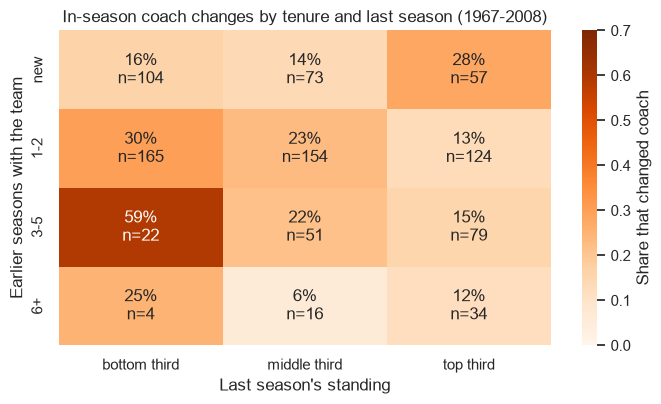

In [54]:
# Coach-change rate by tenure band and by last season's standing in thirds
tb = frame[(frame['year'] <= 2008) & (frame['has_prev'] == 1)].copy()
tb['tenure_band'] = pd.cut(tb['coach_tenure'], [-1, 0, 2, 5, 100], labels=['new', '1-2', '3-5', '6+'])
tb['standing'] = pd.qcut(tb['prev_ppg_z'], 3, labels=['bottom third', 'middle third', 'top third'])
rate = tb.pivot_table(index='tenure_band', columns='standing', values='target_coach_change', aggfunc='mean', observed=False)
count = tb.pivot_table(index='tenure_band', columns='standing', values='target_coach_change', aggfunc='size', observed=False)
display(rate.round(3))
display(count)

# Heatmap: rate on top, number of team-seasons underneath
labels = [[f'{rate.iat[i, j]:.0%}\nn={count.iat[i, j]}' for j in range(rate.shape[1])] for i in range(rate.shape[0])]
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(rate, annot=labels, fmt='', cmap='Oranges', vmin=0, vmax=0.7, ax=ax, cbar_kws={'label': 'Share that changed coach'})
ax.set(title='In-season coach changes by tenure and last season (1967-2008)',
       xlabel="Last season's standing", ylabel='Earlier seasons with the team')
plt.tight_layout()
plt.show()


**What we found:** Tenure and results interact. The highest change rate is for coaches with 3 to 5 earlier seasons whose team finished in the bottom third (about 59%), while long-serving coaches of middle and top teams are almost never replaced (about 6-12%). New coaches of top teams change surprisingly often (about 28%). Some cells are small (only 4 team-seasons with a 6+ coach and a bottom-third finish), so this is a hint, not a rule.

**Decision:** keep coach_tenure as a feature. Because the effect of last season's standing depends on tenure, tree-based models, which can find interactions on their own, are worth trying in notebook 3.


### 3.5 Outliers: z-score, IQR and Isolation Forest

Look for outliers with three methods: values beyond 3 standard deviations, the 1.5 x IQR rule, and an Isolation Forest (multivariate: finds teams that are unusual in the combination of features). Then we explain the extreme cases with domain knowledge and decide what to do.

**Why three methods.** The z-score and IQR rules look at one variable at a time and the Isolation Forest at all variables together. A value flagged by only one method is a weaker case. Statistics alone cannot say whether an outlier is an error or a real event, so each group of flagged rows is checked against hockey facts: the 1994 lockout season (48 games, so noisier statistics), expansion teams (new franchises, no history), and champions (many playoff series won).

,beyond 3 SD,outside 1.5 IQR
prev_ppg_z,1,1
prev_gf_pg_z,2,8
prev_ga_pg_z,2,4
prev_gd_pg_z,2,5
prev_pythag_z,2,2
prev_luck_z,0,1
prev_pp_pct_z,0,4
prev_pk_pct_z,1,1
prev_pim_pg_z,5,13
prev_shorthanded_net_pg_z,0,2


40 cells beyond 3 SD and 155 cells outside 1.5 IQR, out of 17148 non-missing cells
Target outliers by the IQR rule (kept: they are the real best and worst teams):


,year,name,target_points,games,target_ppg_z,has_prev
410,1989,Quebec Nordiques,31,80,-3.25,1


,year,name,anomaly,prev_ppg_z,prev_ga_pg_z,prev_luck_z,prev_playoff_series_won_z,prev_short_season
358,1987,Edmonton Oilers,0.62,2.14,-0.32,1.01,2.87,0
431,1990,Quebec Nordiques,0.62,-3.25,2.63,-2.29,-0.62,0
524,1994,Ottawa Senators,0.61,-2.74,3.11,0.56,-0.54,0
498,1993,Ottawa Senators,0.60,-2.46,2.07,-1.79,-0.57,0
669,2000,Atlanta Thrashers,0.60,-2.76,2.54,-0.55,-0.52,0
295,1984,Edmonton Oilers,0.60,1.82,-0.04,2.04,2.87,0
636,1998,Tampa Bay Lightning,0.58,-2.41,1.82,1.57,-0.54,0
316,1985,Edmonton Oilers,0.58,1.53,-0.28,1.46,2.87,0
502,1993,San Jose Sharks,0.57,-2.46,2.50,-2.07,-0.57,0
568,1996,Detroit Red Wings,0.57,2.59,-1.94,1.30,1.34,0


Isolation Forest flagged 18 rows. Of them: after the 1994 lockout season 0, last-season champion-like (3+ series won) 8, extreme last-season points (|z| > 2) 11


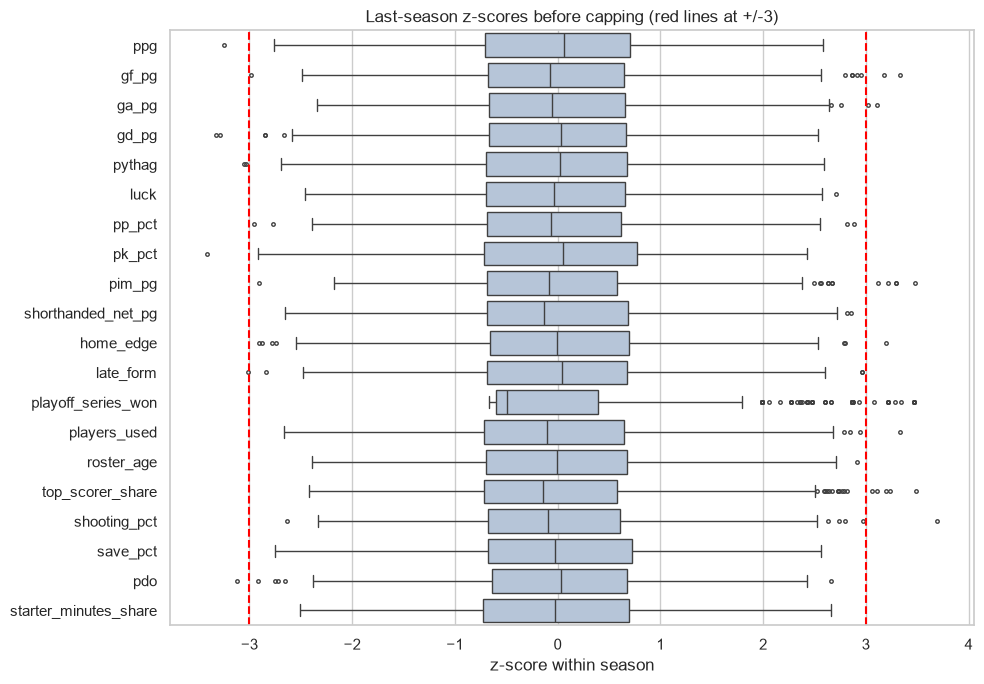

Capped 27 cells at +/-3 in 19 columns (playoff series won is a bounded count, not capped; targets never capped).


In [55]:
from sklearn.ensemble import IsolationForest

Z_COLS = ['prev_' + f + '_z' for f in Z_FEATURES]
dev = frame[(frame['year'] <= 2008) & (frame['has_prev'] == 1)].copy()

# Univariate rules: beyond 3 SD and outside 1.5 IQR
beyond = (dev[Z_COLS].abs() > 3).sum()
q1, q3 = dev[Z_COLS].quantile(0.25), dev[Z_COLS].quantile(0.75)
iqr_out = ((dev[Z_COLS] < q1 - 1.5 * (q3 - q1)) | (dev[Z_COLS] > q3 + 1.5 * (q3 - q1))).sum()
summary = pd.DataFrame({'beyond 3 SD': beyond, 'outside 1.5 IQR': iqr_out})
display(summary[(summary > 0).any(axis=1)])
print(f"{int(beyond.sum())} cells beyond 3 SD and {int(iqr_out.sum())} cells outside 1.5 IQR, out of {dev[Z_COLS].notna().sum().sum()} non-missing cells")

# Target outliers
tq1, tq3 = frame.loc[frame['year'] <= 2008, 'target_ppg_z'].quantile([0.25, 0.75])
rows = frame[(frame['year'] <= 2008) & ((frame['target_ppg_z'] < tq1 - 1.5 * (tq3 - tq1)) | (frame['target_ppg_z'] > tq3 + 1.5 * (tq3 - tq1)))]
print('Target outliers by the IQR rule (kept: they are the real best and worst teams):')
display(rows[['year', 'name', 'target_points', 'games', 'target_ppg_z', 'has_prev']].round(2))

# Isolation Forest on all features together
X = dev[Z_COLS].fillna(dev[Z_COLS].median())
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=42).fit(X)
dev['anomaly'] = -iso.score_samples(X)
dev['flagged'] = iso.predict(X) == -1
top = dev.nlargest(10, 'anomaly')[['year', 'name', 'anomaly', 'prev_ppg_z', 'prev_ga_pg_z', 'prev_luck_z', 'prev_playoff_series_won_z', 'prev_short_season']]
display(top.round(2))
fl = dev[dev['flagged']]
print(f"Isolation Forest flagged {len(fl)} rows. Of them: after the 1994 lockout season {int(fl['prev_short_season'].sum())}, "
      f"last-season champion-like (3+ series won) {int((fl['prev_playoff_series_won'] >= 3).sum())}, "
      f"extreme last-season points (|z| > 2) {int((fl['prev_ppg_z'].abs() > 2).sum())}")

# Boxplots before capping
fig, ax = plt.subplots(figsize=(10, 7))
sns.boxplot(data=dev[Z_COLS].rename(columns=lambda c: c.replace('prev_', '').replace('_z', '')), orient='h', fliersize=2.5, color='lightsteelblue', ax=ax)
ax.axvline(3, color='red', ls='--')
ax.axvline(-3, color='red', ls='--')
ax.set(title='Last-season z-scores before capping (red lines at +/-3)', xlabel='z-score within season', ylabel='')
plt.tight_layout()
plt.show()

# Cap at +/-3 (not playoff series won, never the targets)
CAP_COLS = [c for c in Z_COLS if c != 'prev_playoff_series_won_z']
n_cap = int((frame[CAP_COLS].abs() > 3).sum().sum())
frame[CAP_COLS] = frame[CAP_COLS].clip(-3, 3)
print(f"Capped {n_cap} cells at +/-3 in {len(CAP_COLS)} columns (playoff series won is a bounded count, not capped; targets never capped).")

**Before and after capping.** The first boxplot above shows the data before capping. The next one shows both versions side by side, only for the rows used here (1967-2008 with a previous season).

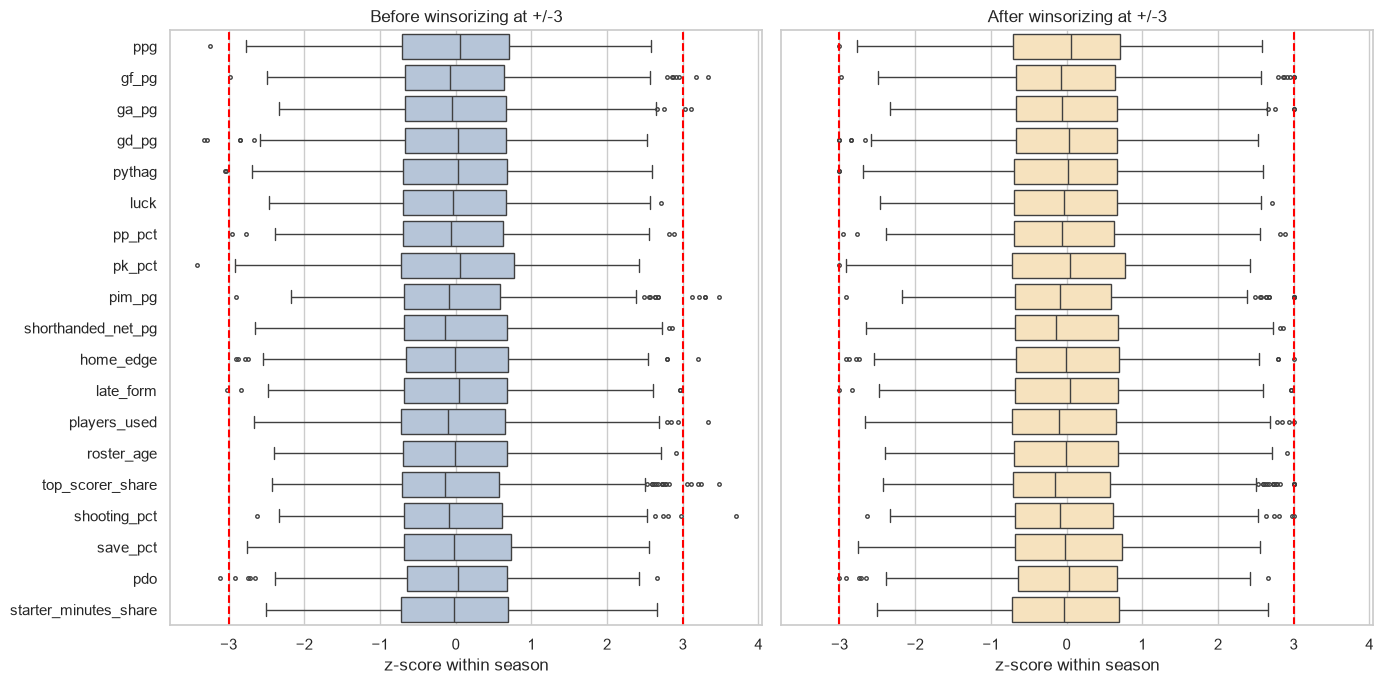

Largest absolute z: before 3.70, after 3.00
Cells changed in these rows: 25 of 16265


,std before,std after,skew before,skew after
ppg,0.98,0.98,-0.19,-0.18
gf_pg,0.98,0.98,0.35,0.33
ga_pg,0.98,0.98,0.28,0.28
gd_pg,0.98,0.97,-0.21,-0.19
pythag,0.98,0.98,-0.15,-0.15
pk_pct,0.98,0.98,-0.22,-0.21
pim_pg,0.98,0.97,0.50,0.46
home_edge,0.98,0.98,0.02,0.01
late_form,0.98,0.98,-0.09,-0.09
players_used,0.98,0.98,0.42,0.41


In [56]:
# Effect of the cap on these rows
def rename(c):
    return c.replace('prev_', '').replace('_z', '')

cap_before, cap_after = dev[CAP_COLS], frame.loc[dev.index, CAP_COLS]
changed = (cap_before - cap_after).abs() > 0
fig, ax = plt.subplots(1, 2, figsize=(14, 7), sharey=True, sharex=True)
for a, data, t in [(ax[0], cap_before, 'Before'), (ax[1], cap_after, 'After')]:
    sns.boxplot(data=data.rename(columns=rename), orient='h', fliersize=2.5, color='lightsteelblue' if t == 'Before' else 'moccasin', ax=a)
    a.axvline(3, color='red', ls='--')
    a.axvline(-3, color='red', ls='--')
    a.set(title=f'{t} winsorizing at +/-3', xlabel='z-score within season', ylabel='')
plt.tight_layout()
plt.show()
print(f"Largest absolute z: before {cap_before.abs().max().max():.2f}, after {cap_after.abs().max().max():.2f}")
print(f"Cells changed in these rows: {int(changed.sum().sum())} of {int(cap_before.notna().sum().sum())}")
chg = pd.DataFrame({'std before': cap_before.std(), 'std after': cap_after.std(), 'skew before': cap_before.skew(), 'skew after': cap_after.skew()})
display(chg.loc[changed.any()].rename(index=rename).round(2))

**What we found (before and after):** Capping at +/-3 moves the largest absolute z-score from 3.70 to 3.00 and changes only 25 of 16,265 cells in these rows (the other 2 of the 27 capped cells are in 2009). In the boxplots the isolated points beyond the red lines disappear while the boxes and whiskers stay the same. The effect on the distribution is tiny: the standard deviation stays at 0.97-0.98 and the skewness changes by at most 0.04 (penalty minutes 0.50 to 0.46, top-scorer share 0.61 to 0.59). So the cap removes the leverage of a few extreme values and keeps the real spread.

**What we found:** Only 40 of 17,148 non-missing feature values (0.23%) lie beyond 3 SD, and 155 (0.9%) outside the IQR fences. The largest group is playoff series won (15 beyond 3 SD, 69 by IQR): a champion wins four series, which is real. Penalty minutes (5 and 13) and top-scorer share (5 and 17) follow. Only one target value is an IQR outlier: Quebec 1989 with 31 points (z = -3.25), the weakest team of the sample, which is real. The Isolation Forest flagged 18 rows (2%). Its top ten are the Edmonton dynasty (1984, 1985, 1987, after champion seasons with points z between +1.5 and +2.1), very weak or expansion teams (Quebec 1990, Ottawa 1993 and 1994, Atlanta 2000, Tampa Bay 1998, San Jose 1993) and Detroit 1996 after a season with points z = +2.59. Of the 18 flagged rows, 8 follow a champion-like season (3 or more series won), 11 an extreme points season (|z| > 2) and none follows the 1994 lockout season. Every flagged case has a domain explanation, and the quality checks (3.2) found no impossible values.

**Decision:** keep all real extremes: they are exactly the teams a ranking must get right. Cap the z-scored continuous features at +/-3 (27 cells over all seasons including 2009; a fixed constant, so nothing is learned from the test season), not playoff series won (a bounded count) and never the targets. The 1994 lockout (48 games) is flagged by prev_short_season, and expansion teams by has_prev and the missing indicators (3.6).

### 3.6 Missing data: reasons, imputation methods compared, and the decision

(1) Measure the missing share per feature and explain why each is missing. (2) Compare four imputation methods (mean, median, KNN, regression-based IterativeImputer) with a correct set-up: fit on training seasons only (target years up to 1999), then hide 15% of the known values in later held-out seasons (2000-2008) and measure the RMSE of the filled values (in standard deviations). Repeated with 5 different masks. (3) Decide the method and add missing indicators.

**Why this set-up.** Fitting the imputer on all seasons would let the held-out seasons influence the fill values. Hiding known values gives us the truth to compare against, which a genuinely missing value cannot. Repeating the mask shows how stable the ranking is.

**Why reasons matter.** If values are missing for structural reasons (a statistic was not recorded yet, or a team has no previous season), a model-based guess can be wrong in a systematic way, and the fact of being missing can itself carry information. So we keep NaN in the exported table and add indicator columns.

,missing % (all rows),missing % (rows with a previous season),reason
prev_ppg_z,2.8,0.0,new franchise has no previous season (structural)
prev_gf_pg_z,2.8,0.0,new franchise has no previous season (structural)
prev_ga_pg_z,2.8,0.0,new franchise has no previous season (structural)
prev_gd_pg_z,2.8,0.0,new franchise has no previous season (structural)
prev_pythag_z,2.8,0.0,new franchise has no previous season (structural)
prev_luck_z,2.8,0.0,new franchise has no previous season (structural)
prev_pp_pct_z,2.8,0.0,new franchise has no previous season (structural)
prev_pk_pct_z,2.8,0.0,new franchise has no previous season (structural)
prev_pim_pg_z,2.8,0.0,new franchise has no previous season (structural)
prev_shorthanded_net_pg_z,2.8,0.0,new franchise has no previous season (structural)


25 new-franchise rows (1967-2008): average first-season points z = -1.14, coach change rate = 0.20
First season with prev_save_pct available: 1983 (last season used as source: 1982 )
First-time coaches (0 career games before the season): 123


,RMSE (SD units),sd over 5 masks
mean,0.986,0.019
median,1.018,0.021
KNN (k=10),0.806,0.023
iterative (Bayesian ridge),0.715,0.021


Training rows 645, held-out rows 238, hidden cells per mask about 993


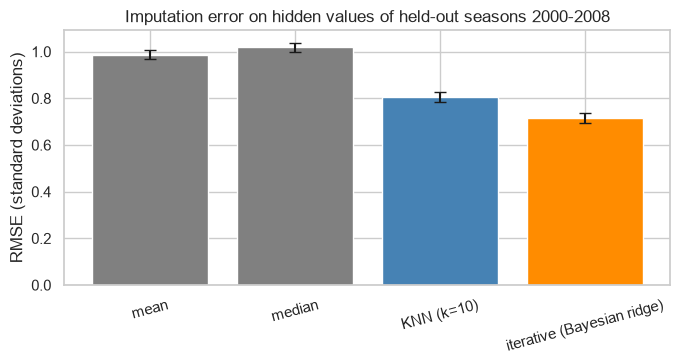

Indicator counts (1967-2009): {'has_prev': 913, 'prev_goalie_data_missing': 253, 'coach_first_time': 125}


In [57]:
COACH_FEATURES = ['coach_new', 'coach_tenure', 'coach_career_games_log', 'coach_career_pct', 'prev_coach_change']
CANDIDATES = Z_COLS + ['prev_made_playoffs', 'prev_short_season'] + COACH_FEATURES
# Missing share and reason per feature
dev = frame[frame['year'] <= 2008]
miss = pd.DataFrame({'missing % (all rows)': dev[CANDIDATES].isna().mean() * 100,
                     'missing % (rows with a previous season)': dev.loc[dev['has_prev'] == 1, CANDIDATES].isna().mean() * 100})
miss = miss[miss['missing % (all rows)'] > 0]

def reason(c):
    if c in ('prev_save_pct_z', 'prev_pdo_z'):
        return 'goalie shots against recorded from 1982 only (structural), plus new franchises'
    if c == 'prev_coach_change' or c == 'coach_new':
        return 'new franchise has no previous coach (structural)'
    if c == 'coach_career_pct':
        return 'first-time coach has no career record (structural)'
    return 'new franchise has no previous season (structural)' if miss.loc[c, 'missing % (rows with a previous season)'] == 0 else 'source field incomplete in some seasons'
miss['reason'] = [reason(c) for c in miss.index]
pd.set_option('display.max_colwidth', 100)
display(miss.round(1))

# New franchises, save % and first-time coaches
new_rows = frame[(frame['has_prev'] == 0) & (frame['year'] <= 2008)]
print(f"{len(new_rows)} new-franchise rows (1967-2008): average first-season points z = {new_rows['target_ppg_z'].mean():.2f}, coach change rate = {new_rows['target_coach_change'].mean():.2f}")
print('First season with prev_save_pct available:', int(frame.loc[frame['prev_save_pct_z'].notna(), 'year'].min()), '(last season used as source:',
      int(frame.loc[frame['prev_save_pct_z'].notna(), 'prev_year'].min()), ')')
print('First-time coaches (0 career games before the season):', int((frame.loc[frame['year'] <= 2008, 'coach_career_games'] == 0).sum()))

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

# Imputation test: fit on seasons up to 1999, hide 15% of known values in 2000-2008
cols = [c for c in CANDIDATES]
train = frame.loc[(frame['year'] <= 1999) & (frame['has_prev'] == 1), cols]
hold = frame.loc[frame['year'].between(2000, 2008) & (frame['has_prev'] == 1), cols]
mu, sd = train.mean(), train.std()
train, hold = (train - mu) / sd, (hold - mu) / sd
imputers = {'mean': SimpleImputer(), 'median': SimpleImputer(strategy='median'), 'KNN (k=10)': KNNImputer(n_neighbors=10),
            'iterative (Bayesian ridge)': IterativeImputer(max_iter=20, random_state=0)}
for imp in imputers.values():
    imp.fit(train)
errors = {k: [] for k in imputers}
for rep in range(5):
    hide = hold.notna() & (np.random.default_rng(rep).random(hold.shape) < 0.15)
    for name, imp in imputers.items():
        filled = pd.DataFrame(imp.transform(hold.mask(hide)), index=hold.index, columns=hold.columns)
        errors[name].append(np.sqrt(((filled - hold)[hide] ** 2).stack().mean()))
imp_res = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in errors.items()}, index=['RMSE (SD units)', 'sd over 5 masks']).T
display(imp_res.round(3))
print(f"Training rows {len(train)}, held-out rows {len(hold)}, hidden cells per mask about {int(hide.values.sum())}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(imp_res.index, imp_res['RMSE (SD units)'], yerr=imp_res['sd over 5 masks'], capsize=4, color=['grey', 'grey', 'steelblue', 'darkorange'])
ax.set(title='Imputation error on hidden values of held-out seasons 2000-2008', ylabel='RMSE (standard deviations)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Missing indicators
frame['prev_goalie_data_missing'] = ((frame['has_prev'] == 1) & frame['prev_save_pct_z'].isna()).astype(int)
frame['coach_first_time'] = (frame['coach_career_games'] == 0).astype(int)
INDICATORS = ['has_prev', 'prev_goalie_data_missing', 'coach_first_time']
print('Indicator counts (1967-2009):', {c: int(frame[c].sum()) for c in INDICATORS})

**What we found:** The missing values are structural. 25 new-franchise rows (2.8% of 1967-2008) have no previous season, so all prev_* features are missing together. Save percentage and PDO are missing in 30.6% of rows (28.7% among rows with a previous season) because goalie shots exist only from 1982 (first usable target season 1983). Shooting percentage is missing in 3.4% (0.7% with a previous season; shot counts absent in some team-seasons). Career points share is missing in 13.5% because 123 rows (1967-2008) have a first-time coach without a record; coach_new and prev_coach_change are missing only for new franchises. The missingness is informative: new franchises score -1.14 SD on average in their first season, so we add the indicators has_prev, prev_goalie_data_missing and coach_first_time (1 in 913, 253 and 125 rows of 1967-2009).

Imputation test (train: target seasons up to 1999, 645 rows; held out: 2000-2008, 238 rows; about 990 hidden values per mask; RMSE in standard deviations, mean and SD over 5 masks): mean 0.986 (0.019), median 1.018 (0.021), KNN 0.806 (0.023), iterative Bayesian ridge 0.715 (0.021). The regression-based imputer is clearly best: about 27% below mean imputation, with a gap many times larger than the spread over masks.

**Decision:** use the IterativeImputer (regression-based), fitted only on the training folds inside the model pipeline (imputer, scaler, model) in notebooks 2-4, together with the three indicators. The exported table is not imputed. Tree models with native NaN support (for example HistGradientBoosting) can use the NaN directly. The quick experiments in 3.9 use a median imputer to stay simple and fast.

#### 3.6.1 Missingness pattern by season, and what imputation does to the data

(1) Draw a missingness matrix (one row per team-season, sorted by season, black = missing) and the share of missing values per season for three features. (2) Fit the IterativeImputer and, for comparison, a mean imputer on the training seasons only (target years up to 1999). Compare observed and imputed values for save percentage and career points share with density plots. (3) Check whether imputation keeps the variance of each feature and the correlations between features.

The matrix shows whether missingness is random or tied to seasons, which decides if imputation is safe. Mean imputation puts every missing value on one number, which shrinks the variance and weakens correlations. A regression-based imputer should keep more of the structure.

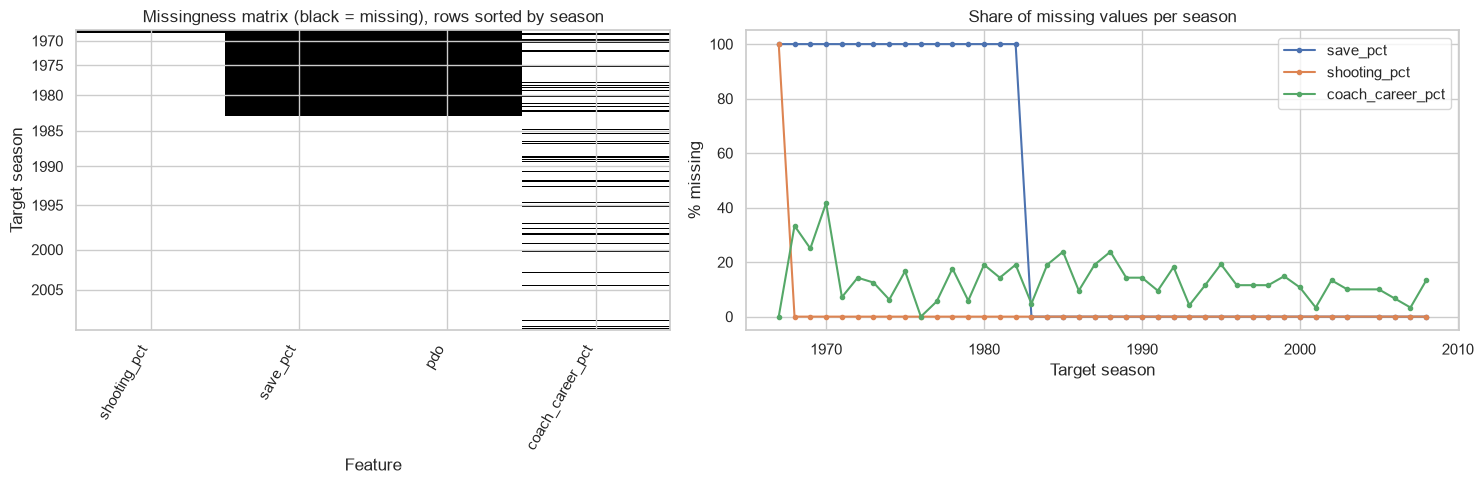

Save percentage: 100% missing before 1983, 0.0% from 1983
Career points share: 0% to 42% missing per season (first-time coaches, spread over all seasons)
          save_pct: observed mean 0.00, sd 0.98 | iterative imputed mean 0.02, sd 0.61
  coach_career_pct: observed mean 0.51, sd 0.09 | iterative imputed mean 0.36, sd 0.06


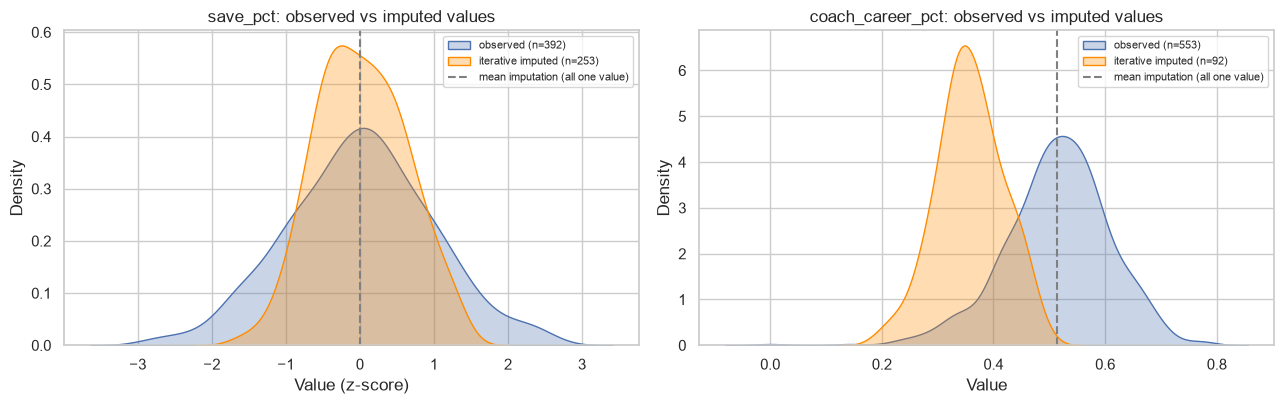

,sd observed,sd after mean,sd after iterative,"variance kept, mean (%)","variance kept, iterative (%)"
shooting_pct,0.97,0.97,0.97,99.07,99.69
save_pct,0.98,0.76,0.85,60.71,75.71
pdo,0.98,0.76,0.91,60.71,86.18
coach_career_pct,0.09,0.09,0.11,85.71,124.67


Mean absolute change of a correlation that involves an incomplete feature (vs observed pairs): mean imputation 0.045, iterative 0.028


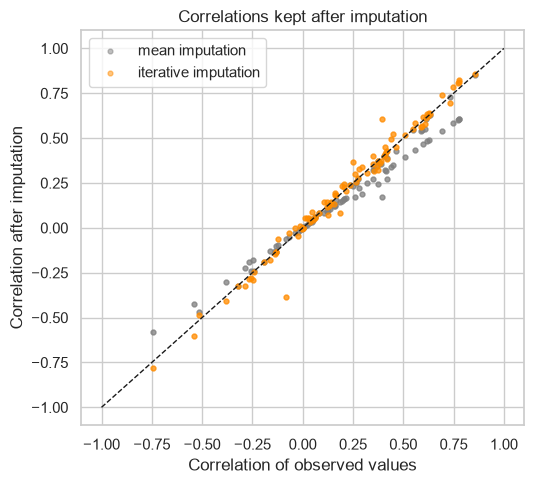

corr(save_pct, ga_pg): observed -0.74, mean imputed -0.58, iterative -0.78
corr(save_pct, pdo): observed 0.73, mean imputed 0.73, iterative 0.70
corr(coach_career_pct, coach_tenure): observed 0.25, mean imputed 0.24, iterative 0.37


In [58]:
# Missingness matrix and share per season
mdev = frame[(frame['year'] <= 2008) & (frame['has_prev'] == 1)].sort_values('year')
mcols = [c for c in CANDIDATES if mdev[c].isna().any()]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.2]})
ax[0].imshow(mdev[mcols].isna().values, aspect='auto', cmap='Greys', interpolation='nearest')
yrs = mdev['year'].values
ticks = [int(np.argmax(yrs >= y)) for y in range(1970, 2010, 5)]
ax[0].set_yticks(ticks)
ax[0].set_yticklabels(range(1970, 2010, 5))
ax[0].set_xticks(range(len(mcols)))
ax[0].set_xticklabels([c.replace('prev_', '').replace('_z', '') for c in mcols], rotation=60, ha='right')
ax[0].set(title='Missingness matrix (black = missing), rows sorted by season', xlabel='Feature', ylabel='Target season')
share = mdev.groupby('year')[mcols].apply(lambda g: g.isna().mean() * 100)
for c in ['prev_save_pct_z', 'prev_shooting_pct_z', 'coach_career_pct']:
    ax[1].plot(share.index, share[c], marker='o', ms=3, label=rename(c))
ax[1].set(title='Share of missing values per season', xlabel='Target season', ylabel='% missing')
ax[1].legend()
plt.tight_layout()
plt.show()
first_ok = int(mdev.loc[mdev['prev_save_pct_z'].notna(), 'year'].min())
print(f"Save percentage: {mdev.loc[mdev['year'] < first_ok, 'prev_save_pct_z'].isna().mean() * 100:.0f}% missing before {first_ok}, {mdev.loc[mdev['year'] >= first_ok, 'prev_save_pct_z'].isna().mean() * 100:.1f}% from {first_ok}")
print(f"Career points share: {share['coach_career_pct'].min():.0f}% to {share['coach_career_pct'].max():.0f}% missing per season (first-time coaches, spread over all seasons)")

# Observed vs imputed values (training seasons only)
tr = frame.loc[(frame['year'] <= 1999) & (frame['has_prev'] == 1), CANDIDATES]
it_imp = IterativeImputer(max_iter=20, random_state=0).fit(tr)
tr_it = pd.DataFrame(it_imp.transform(tr), index=tr.index, columns=CANDIDATES)
tr_mean = pd.DataFrame(SimpleImputer().fit_transform(tr), index=tr.index, columns=CANDIDATES)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, c in zip(ax, ['prev_save_pct_z', 'coach_career_pct']):
    miss_rows = tr[c].isna()
    sns.kdeplot(tr.loc[~miss_rows, c], ax=a, fill=True, alpha=0.3, label=f'observed (n={int((~miss_rows).sum())})')
    sns.kdeplot(tr_it.loc[miss_rows, c], ax=a, fill=True, alpha=0.3, color='darkorange', label=f'iterative imputed (n={int(miss_rows.sum())})')
    a.axvline(tr[c].mean(), color='grey', ls='--', label='mean imputation (all one value)')
    a.set(title=f'{rename(c)}: observed vs imputed values', xlabel='Value' + (' (z-score)' if c.endswith('_z') else ''), ylabel='Density')
    a.legend(fontsize=8)
    print(f"{rename(c):>18}: observed mean {tr.loc[~miss_rows, c].mean():.2f}, sd {tr.loc[~miss_rows, c].std():.2f} | iterative imputed mean {tr_it.loc[miss_rows, c].mean():.2f}, sd {tr_it.loc[miss_rows, c].std():.2f}")
plt.tight_layout()
plt.show()

# Variance kept by each imputer
var_tab = pd.DataFrame({'sd observed': tr[mcols].std(), 'sd after mean': tr_mean[mcols].std(), 'sd after iterative': tr_it[mcols].std()}).rename(index=rename)
var_tab['variance kept, mean (%)'] = (var_tab['sd after mean'] / var_tab['sd observed']) ** 2 * 100
var_tab['variance kept, iterative (%)'] = (var_tab['sd after iterative'] / var_tab['sd observed']) ** 2 * 100
display(var_tab.round(2))

# How much the correlations change
c_obs, c_mean, c_it = tr.corr(), tr_mean.corr(), tr_it.corr()
off = ~np.eye(len(CANDIDATES), dtype=bool)
pairs_mask = off & (tr.isna().values.any(axis=0)[:, None] | tr.isna().values.any(axis=0)[None, :])
print(f"Mean absolute change of a correlation that involves an incomplete feature (vs observed pairs): mean imputation {np.abs(c_mean - c_obs).values[pairs_mask].mean():.3f}, iterative {np.abs(c_it - c_obs).values[pairs_mask].mean():.3f}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(c_obs.values[pairs_mask], c_mean.values[pairs_mask], s=12, alpha=0.5, label='mean imputation', color='grey')
ax.scatter(c_obs.values[pairs_mask], c_it.values[pairs_mask], s=12, alpha=0.5, label='iterative imputation', color='darkorange')
ax.plot([-1, 1], [-1, 1], 'k--', lw=1)
ax.set(title='Correlations kept after imputation', xlabel='Correlation of observed values', ylabel='Correlation after imputation')
ax.legend()
plt.tight_layout()
plt.show()
for a, b in [('prev_save_pct_z', 'prev_ga_pg_z'), ('prev_save_pct_z', 'prev_pdo_z'), ('coach_career_pct', 'coach_tenure')]:
    print(f"corr({rename(a)}, {rename(b)}): observed {c_obs.loc[a, b]:.2f}, mean imputed {c_mean.loc[a, b]:.2f}, iterative {c_it.loc[a, b]:.2f}")

**What we found (pattern and imputation effects):** The matrix shows blocks, not scattered holes. Save percentage and PDO are 100% missing for target seasons before 1983 and 0.0% missing from 1983 on (goalie shots were not recorded earlier). Career points share is missing at a rate of 0% to 42% per season (first-time coaches, spread over all seasons). The remaining gaps are the new-franchise rows (all features missing together) and a few shooting-percentage values. So missingness follows the season and the coach history, not chance, and the other features carry information a regression-based imputer can use.

Observed vs imputed (training seasons up to 1999): the iterative imputer fills save percentage with a mean of 0.02 and sd 0.61 (observed: mean 0.00, sd 0.98), and career points share with mean 0.36 and sd 0.06 (observed: mean 0.51, sd 0.09). The imputed values are centred near the observed ones for save percentage, but less spread, because a regression gives the expected value and not a random draw. For career points share the imputed values are lower: these coaches are first-timers, so a lower share is plausible, but we cannot check it. Mean imputation puts every missing value on one number (dashed line).

Variance kept (percent of the observed variance): mean imputation keeps 60.7% for save percentage and PDO, 85.7% for career points share and 99.1% for shooting percentage; iterative imputation keeps 75.7%, 86.2%, 124.7% and 99.7%. So iterative imputation shrinks the variance less, but it is not perfect (career points share even gets 25% more variance). Correlations: the mean absolute change of a correlation involving an incomplete feature is 0.045 for mean imputation and 0.028 for iterative. Save percentage vs goals against: observed -0.74, mean imputed -0.58, iterative -0.78; save percentage vs PDO: 0.73, 0.73, 0.70; career points share vs tenure: 0.25, 0.24, 0.37.

**Decision:** unchanged. The iterative imputer keeps the relations between features better than mean imputation (smaller shrinkage for most features, smaller correlation error, lowest RMSE in 3.6). Because it does not recover the full variance and can exaggerate some correlations, the missing indicators stay in the table, and tree models can also use the NaN directly.

### 3.7 Redundancy: correlation clusters and VIF

A systematic two-step removal on the development seasons. Step 1: hierarchical clustering of the features on distance 1 - |Spearman correlation|, cut at 0.1, so that features in a cluster have average rank correlation above 0.9; we keep the most central feature of each cluster, preferring a raw measure over a derived one (goal difference and Pythagorean expectation are built from goals for and against). Step 2: iteratively remove the feature with the highest variance inflation factor (VIF) until all are below 10. We list everything we drop.

Highly correlated features carry the same information, make linear coefficients unstable and slow down every model. Some are redundant by construction here: goal difference is goals for minus goals against, and luck is points share minus Pythagorean expectation, so points, luck and Pythagorean expectation are tied together. VIF catches combinations of several features that pairwise correlation misses. Only features are used, not targets, so nothing leaks.

Cluster ['prev_ppg_z', 'prev_gd_pg_z', 'prev_pythag_z'] -> keep prev_ppg_z

VIF after step 1: max 49.2 (prev_ppg_z)
Dropped features:


,feature,reason
0,prev_gd_pg_z,"rho cluster > 0.9, kept prev_ppg_z"
1,prev_pythag_z,"rho cluster > 0.9, kept prev_ppg_z"
2,prev_ppg_z,VIF = 49.2


27 candidates -> 24 kept; final max VIF = 7.40 (prev_pdo_z)


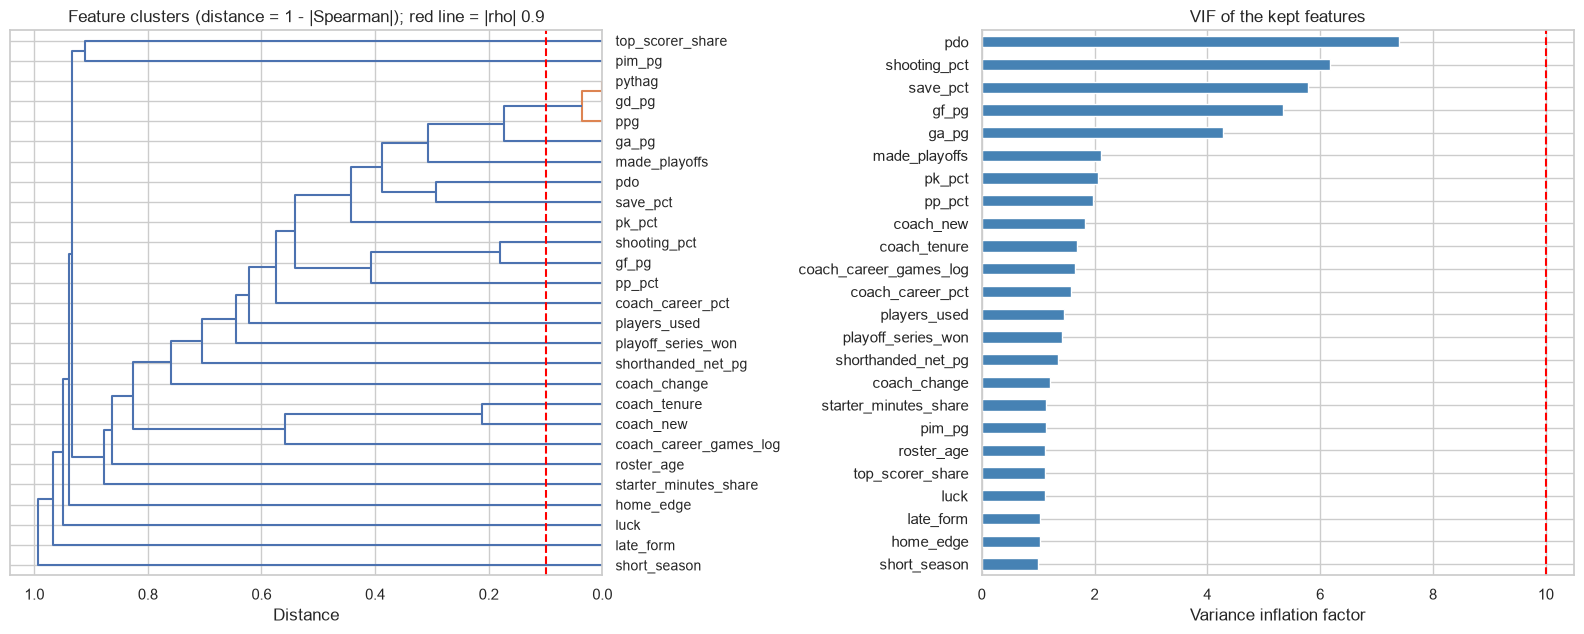

In [59]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Step 1: cluster features on 1 - |Spearman| and keep one per cluster
dev = frame[(frame['year'] <= 2008) & (frame['has_prev'] == 1)]
R = dev[CANDIDATES].corr(method='spearman').abs().fillna(0)
link = hierarchy.linkage(squareform(1 - R.values, checks=False), method='average')
cl = hierarchy.fcluster(link, t=0.1, criterion='distance')
groups = pd.Series(CANDIDATES).groupby(cl).apply(list)
DERIVED = ['prev_gd_pg_z', 'prev_pythag_z']  # built from goals for and against
dropped = []
for members in groups[groups.apply(len) > 1]:
    raw_members = [m for m in members if m not in DERIVED] or members
    centre = max(raw_members, key=lambda c: R.loc[c, [m for m in members if m != c]].mean())
    print(f"Cluster {members} -> keep {centre}")
    dropped += [(m, f'rho cluster > 0.9, kept {centre}') for m in members if m != centre]
kept = [c for c in CANDIDATES if c not in [d[0] for d in dropped]]

# Step 2: drop the highest VIF until all are below 10
def vif_table(cols):
    X = SimpleImputer(strategy='median').fit_transform(dev[cols])
    X = np.column_stack([np.ones(len(X)), X])
    return pd.Series([min(variance_inflation_factor(X, i + 1), 1e6) for i in range(len(cols))], index=cols)

vif = vif_table(kept)
print(f"\nVIF after step 1: max {vif.max():.1f} ({vif.idxmax()})")
while vif.max() > 10:
    worst = vif.idxmax()
    dropped.append((worst, f'VIF = {vif.max():.1f}'))
    kept.remove(worst)
    vif = vif_table(kept)
print('Dropped features:')
display(pd.DataFrame(dropped, columns=['feature', 'reason']))
print(f"{len(CANDIDATES)} candidates -> {len(kept)} kept; final max VIF = {vif.max():.2f} ({vif.idxmax()})")
FEATURES = kept + INDICATORS

# Dendrogram and VIF
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1, 1]})
hierarchy.dendrogram(link, labels=[c.replace('prev_', '').replace('_z', '') for c in CANDIDATES], orientation='left', color_threshold=0.1, ax=ax[0])
ax[0].axvline(0.1, color='red', ls='--')
ax[0].set(title='Feature clusters (distance = 1 - |Spearman|); red line = |rho| 0.9', xlabel='Distance')
vif.sort_values().rename(lambda c: c.replace('prev_', '').replace('_z', '')).plot.barh(ax=ax[1], color='steelblue')
ax[1].axvline(10, color='red', ls='--')
ax[1].set(title='VIF of the kept features', xlabel='Variance inflation factor')
plt.tight_layout()
plt.show()

**What we found:** One cluster has average |Spearman| above 0.9: points per game, goal difference per game and Pythagorean expectation. We keep points (the raw measure) and drop the two derived ones. Step 2 then finds VIF = 49.2 for points per game: it is almost completely explained by goals for, goals against and luck (points share is the Pythagorean expectation, which depends on goals for and against, plus luck), so it is removed as well. Afterwards the highest VIF is 7.40 (PDO). We go from 27 candidates to 24 features, plus 3 indicators. Dropped: prev_gd_pg_z, prev_pythag_z, prev_ppg_z. No other cluster passes the 0.9 threshold in the dendrogram.

**Decision:** keep goals for, goals against and luck as the three separate ingredients of last season's strength. Last season's raw points per game is exported as a baseline column (baseline_prev_ppg) for the persistence baseline, not as a feature.

**Before and after removal.** The heatmaps show the rank correlations of the 27 candidates and of the 24 kept features (development seasons, rows with a previous season).

Before removal: 27 features, max |rho| = 1.00, pairs with |rho| > 0.7: 20, > 0.5: 45
After removal: 24 features, max |rho| = 0.82, pairs with |rho| > 0.7: 5, > 0.5: 15


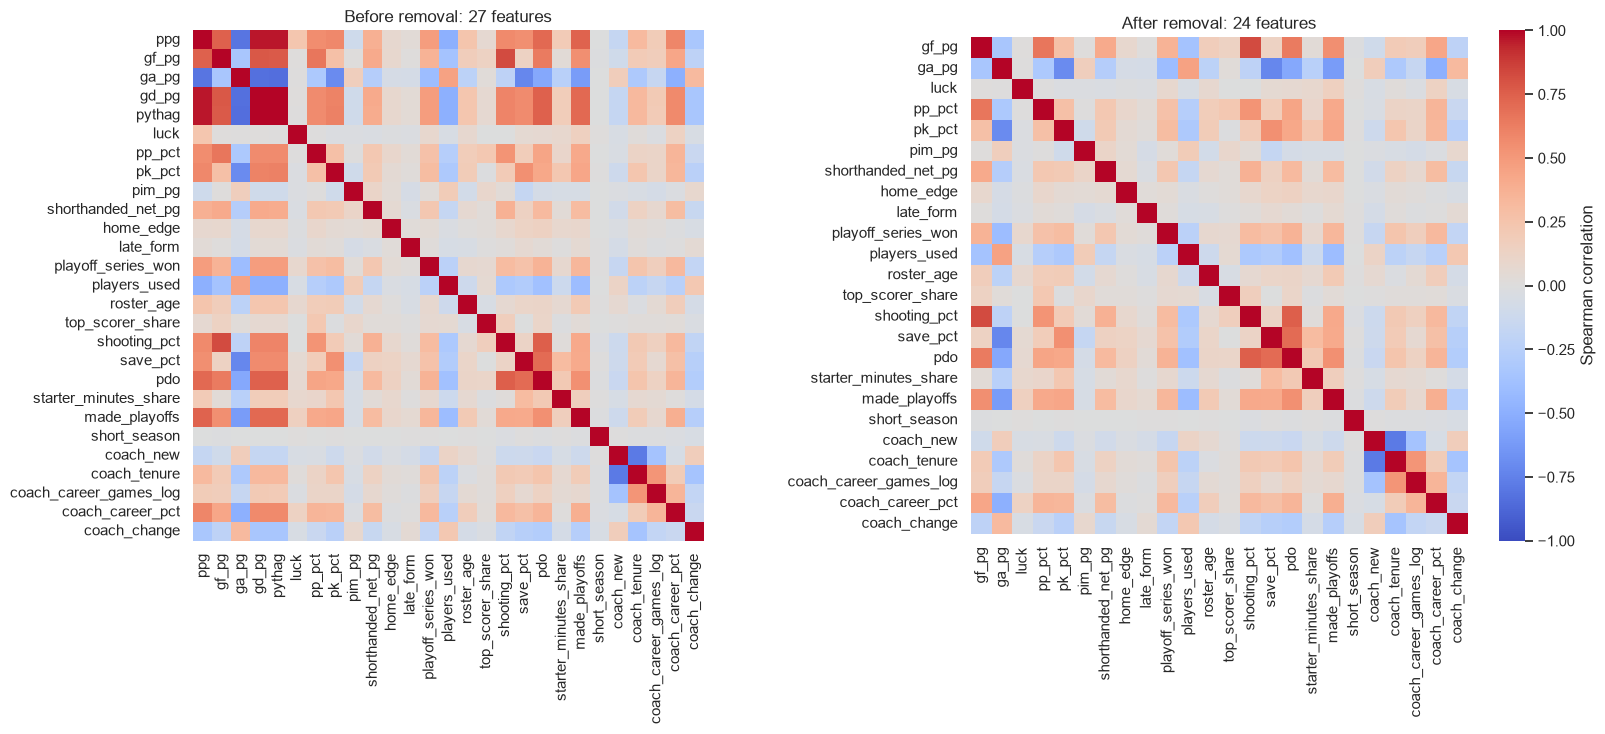

In [60]:
# Correlations before and after removal
fig, ax = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={'width_ratios': [len(CANDIDATES), len(kept)]})
for a, cols, t in [(ax[0], CANDIDATES, 'Before removal'), (ax[1], kept, 'After removal')]:
    cm = dev[cols].corr(method='spearman')
    sns.heatmap(cm.rename(index=rename, columns=rename), cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar=a is ax[1], ax=a,
                cbar_kws={'label': 'Spearman correlation'}, xticklabels=True, yticklabels=True)
    a.set_title(f'{t}: {len(cols)} features')
    upper = cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).abs().stack()
    print(f"{t}: {len(cols)} features, max |rho| = {upper.max():.2f}, pairs with |rho| > 0.7: {int((upper > 0.7).sum())}, > 0.5: {int((upper > 0.5).sum())}")
plt.tight_layout()
plt.show()

**What we found (before and after):** Before removal the 27 candidates have 20 pairs with |rho| above 0.7 and 45 above 0.5, and a maximum of 1.00 (points, goal difference and Pythagorean expectation are almost the same variable). After removing three features, 24 remain with 5 pairs above 0.7, 15 above 0.5 and a maximum |rho| of 0.82. The remaining correlations are moderate, and all VIF values are below 10 (maximum 7.40), so the features still carry different information.

### 3.8 Sampling for the domain: why NHL from 1967

Compare three NHL eras (early 1917-1941, Original Six 1942-1966, expansion era from 1967) on size, completeness of the fields we need, and structure (number of teams, games). We then show the final sample sizes.

The population is "NHL team-seasons", but the game and the league changed. A sample should come from the same process as the seasons we want to predict. With six teams per season a within-season ranking has only six points, and the special-teams and goalie fields are missing in the early eras. We choose the era from structure and completeness, not from model scores.

,era,team_seasons,seasons,teams_per_season,pct_with_special_teams,pct_with_shorthanded_goals,pct_with_division,min_games,max_games
0,1. 1917-1941 early,177,25,7.1,0.0,0.0,62.0,6,48
1,2. 1942-1966 Original Six,150,25,6.0,16.0,16.0,0.0,50,70
2,3. 1967-2009 expansion era,938,42,22.3,100.0,100.0,100.0,48,84


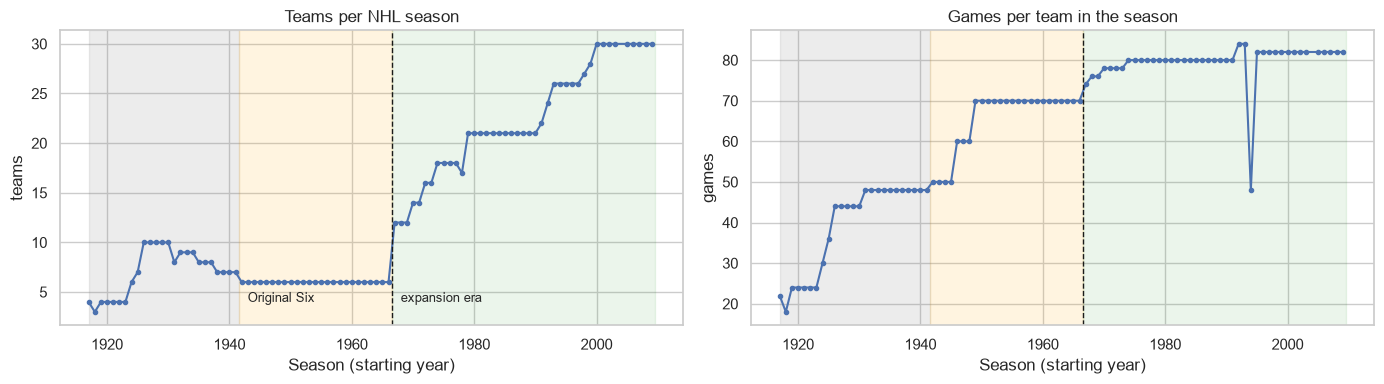

,rows,seasons,first_year,last_year,rows_with_previous_season
split,,,,,
test,30,1,2009,2009,30
train_pool,535,28,1967,1994,514
validation,373,13,1995,2008,369


Teams per season, 1967 vs 2008: 12 vs 30


In [61]:
# Compare the three NHL eras
era = con.execute("""
WITH t AS (SELECT *, CASE WHEN year < 1942 THEN '1. 1917-1941 early' WHEN year < 1967 THEN '2. 1942-1966 Original Six' ELSE '3. 1967-2009 expansion era' END AS era
           FROM Teams WHERE lgID = 'NHL')
SELECT era, count(*) AS team_seasons, count(DISTINCT year) AS seasons, round(count(*) / count(DISTINCT year), 1) AS teams_per_season,
       round(100 * avg((PPC IS NOT NULL)::INT), 0) AS pct_with_special_teams, round(100 * avg((SHF IS NOT NULL)::INT), 0) AS pct_with_shorthanded_goals,
       round(100 * avg((divID IS NOT NULL)::INT), 0) AS pct_with_division, min(G) AS min_games, max(G) AS max_games
FROM t GROUP BY era ORDER BY era""").df()
display(era)

# Teams and games per season
by_year = con.execute("SELECT year, count(*) AS teams, max(G) AS games FROM Teams WHERE lgID = 'NHL' GROUP BY year ORDER BY year").df()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, ttl in [(ax[0], 'teams', 'Teams per NHL season'), (ax[1], 'games', 'Games per team in the season')]:
    a.plot(by_year['year'], by_year[col], 'o-', ms=3)
    a.axvspan(1917, 1941.5, color='grey', alpha=0.15)
    a.axvspan(1941.5, 1966.5, color='orange', alpha=0.12)
    a.axvspan(1966.5, 2009.5, color='green', alpha=0.08)
    a.axvline(1966.5, color='k', ls='--', lw=1)
    a.set(title=ttl, xlabel='Season (starting year)', ylabel=col)
ax[0].text(1968, by_year['teams'].min() + 1, 'expansion era', fontsize=9)
ax[0].text(1943, by_year['teams'].min() + 1, 'Original Six', fontsize=9)
plt.tight_layout()
plt.show()

# Splits: train pool to 1994, validation 1995-2008, test 2009
frame['split'] = np.where(frame['year'] <= 1994, 'train_pool', np.where(frame['year'] <= 2008, 'validation', 'test'))
frame['fold'] = frame['year'].where(frame['split'] == 'validation')
size = frame.groupby('split').agg(rows=('year', 'size'), seasons=('year', 'nunique'), first_year=('year', 'min'), last_year=('year', 'max'),
                                  rows_with_previous_season=('has_prev', 'sum'))
display(size)
print('Teams per season, 1967 vs 2008:', int((frame['year'] == 1967).sum()), 'vs', int((frame['year'] == 2008).sum()))

**What we found:** The eras differ in structure. 1917-1941: 177 team-seasons, about 7.1 teams per season, 6 to 48 games, no special-teams fields (0%). 1942-1966 (Original Six): 150 team-seasons, 6.0 teams per season, special-teams fields in only 16%, no divisions. From 1967: 938 team-seasons in 42 seasons, 22.3 teams on average (12 in 1967, 30 in 2008), special-teams, short-handed and division fields 100% complete, 48 to 84 games. Sample sizes: 535 training-pool rows (28 seasons, 1967-1994), 373 validation rows (13 seasons, 1995-2008, 2004 absent) and 30 test rows (2009); 514, 369 and 30 of them have a previous season.

**Decision:** use the NHL from 1967 (first expansion). It is the first era where a ranking among 12 to 30 teams makes sense, all needed fields are complete and the structure (divisions, expansion) is comparable to 2009. The choice rests on structure and completeness, not on model scores. Earlier seasons and the WHA stay out.

### 3.9 Sampling for development: learning curve and the "is old history outdated?" experiment

Two experiments with simple models (a Ridge regression for points and a logistic regression for coach change, each in a pipeline with median imputation and scaling inside, so nothing is fitted outside the training data).

1. **Learning curve.** Start from a very small sample (10 team-seasons) and grow it to the whole training pool (target seasons 1967-1999), always testing on the seasons 2000-2008. Random row samples are used only here, to show how much data the models need; the test seasons are always later than the training data.
2. **Validation-design experiment.** The team asked: is pre-2004 history outdated? We evaluate with a **rolling origin**: for each validation season from 1995 to 2008 (2004 does not exist) we train only on earlier seasons and predict that one season. We compare training windows of the last 5, 10, 20 and 30 seasons against an expanding window with all earlier seasons.

The learning curve tells us whether more data still helps or whether we have plateaued. The rolling origin copies how the model will be used (predict next season from the past), keeps each season whole, and gives one score per season, so we can test differences between windows. Metrics: within-season Spearman for points (compared with the persistence baseline: rank by last season's points) and PR-AUC for coach change (compared with prevalence).

,spearman,spearman_sd,pr_auc,pr_auc_sd
n,,,,
10,0.357,0.121,0.257,0.042
20,0.358,0.130,0.253,0.052
40,0.441,0.086,0.261,0.047
80,0.498,0.055,0.255,0.045
160,0.537,0.033,0.283,0.041
320,0.568,0.018,0.289,0.040
668,0.596,NaN,0.299,NaN


Baselines on validation seasons 2000-2008: persistence Spearman 0.555, coach-change prevalence 0.204


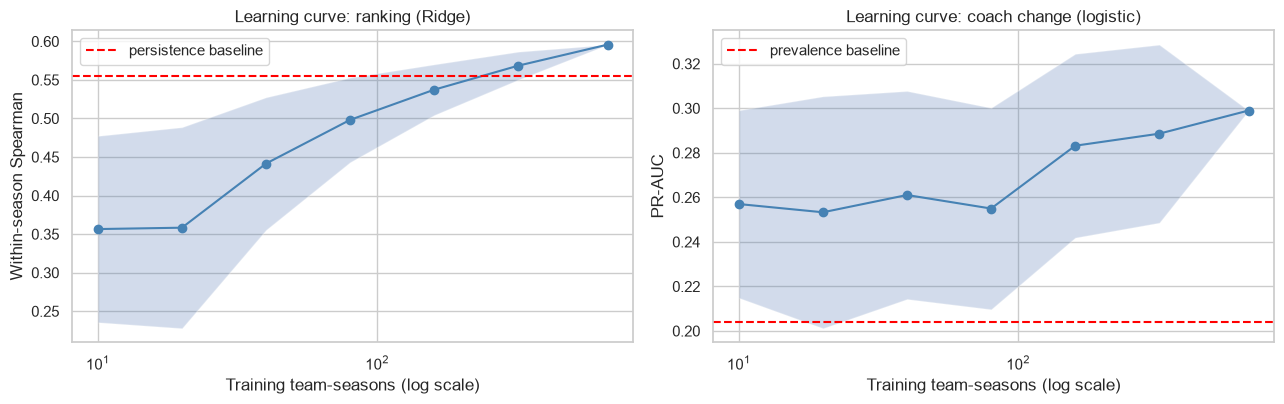

In [62]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import average_precision_score

# Simple models; imputation and scaling inside the pipeline
def ridge():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10))

def logit():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000))


def season_spearman(df, pred):
    d = df.assign(pred=pred)
    return np.mean([stats.spearmanr(g['pred'], g['target_ppg_z'])[0] for _, g in d.groupby('year')])

# Train on 1967-1999, test on 2000-2008
pool = frame[frame['year'].between(1967, 1999)]
val = frame[frame['year'].between(2000, 2008)]
base_rho = np.mean([stats.spearmanr(g['prev_ppg_z'], g['target_ppg_z'], nan_policy='omit')[0] for _, g in val.groupby('year')])
base_prev = val['target_coach_change'].mean()

# Learning curve: random samples of growing size
rng = np.random.default_rng(42)
rows = []
for n in [10, 20, 40, 80, 160, 320, len(pool)]:
    reps = 1 if n == len(pool) else 25
    for r in range(reps):
        while True:
            s = pool.sample(n, random_state=int(rng.integers(1e9)))
            if 0 < s['target_coach_change'].sum() < len(s):
                break
        rho = season_spearman(val, ridge().fit(s[FEATURES], s['target_ppg_z']).predict(val[FEATURES]))
        pr = average_precision_score(val['target_coach_change'], logit().fit(s[FEATURES], s['target_coach_change']).predict_proba(val[FEATURES])[:, 1])
        rows.append({'n': n, 'spearman': rho, 'pr_auc': pr})
lc = pd.DataFrame(rows).groupby('n').agg(spearman=('spearman', 'mean'), spearman_sd=('spearman', 'std'), pr_auc=('pr_auc', 'mean'), pr_auc_sd=('pr_auc', 'std'))
display(lc.round(3))
print(f"Baselines on validation seasons 2000-2008: persistence Spearman {base_rho:.3f}, coach-change prevalence {base_prev:.3f}")

# Plot
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, m, sdv, base, lab, ttl in [(ax[0], 'spearman', 'spearman_sd', base_rho, 'persistence baseline', 'Learning curve: ranking (Ridge)'),
                                 (ax[1], 'pr_auc', 'pr_auc_sd', base_prev, 'prevalence baseline', 'Learning curve: coach change (logistic)')]:
    a.plot(lc.index, lc[m], 'o-', color='steelblue')
    a.fill_between(lc.index, lc[m] - lc[sdv].fillna(0), lc[m] + lc[sdv].fillna(0), alpha=0.25)
    a.axhline(base, color='red', ls='--', label=lab)
    a.set(xscale='log', xlabel='Training team-seasons (log scale)', ylabel='Within-season Spearman' if m == 'spearman' else 'PR-AUC', title=ttl)
    a.legend()
plt.tight_layout()
plt.show()

**What we found:** With 10 team-seasons the Ridge ranking has a within-season Spearman of 0.357 (SD 0.121 over 25 random samples). It grows to 0.441 (40 rows), 0.537 (160), 0.568 (320) and 0.596 with all 668 training rows of 1967-1999, and the spread shrinks from 0.121 to 0.018 at 320 rows. The curve crosses the persistence baseline (0.555) between 160 and 320 rows and is still rising at the end. Coach-change PR-AUC grows slowly and noisily, from 0.257 to 0.299 (prevalence 0.204), with SD 0.04-0.05 at small sizes.

the ranking model is data-hungry: it needs several hundred rows to beat persistence and still improves with more, so more history helps. The coach model has a flat start and a small positive slope; its problem is weak signal rather than too little data.

,mean_train_rows,mean_train_positives,spearman,spearman_sd,pr_auc_per_season,pr_auc_pooled,seasons beating persistence,Wilcoxon p vs expanding (Spearman)
window,,,,,,,,
last 5,137.385,25.077,0.516,0.129,0.296,0.235,5,0.000
last 10,259.077,45.385,0.548,0.141,0.357,0.282,7,0.244
last 20,471.923,89.615,0.560,0.130,0.367,0.265,6,0.110
last 30,643.231,135.846,0.564,0.128,0.347,0.255,7,0.010
expanding (all),701.538,150.923,0.581,0.118,0.352,0.261,8,NaN


Validation seasons: 13 (1995-2008, 2004 absent). Persistence Spearman mean 0.561; coach-change prevalence 0.196
Seasons available before the first validation season (1995): 28


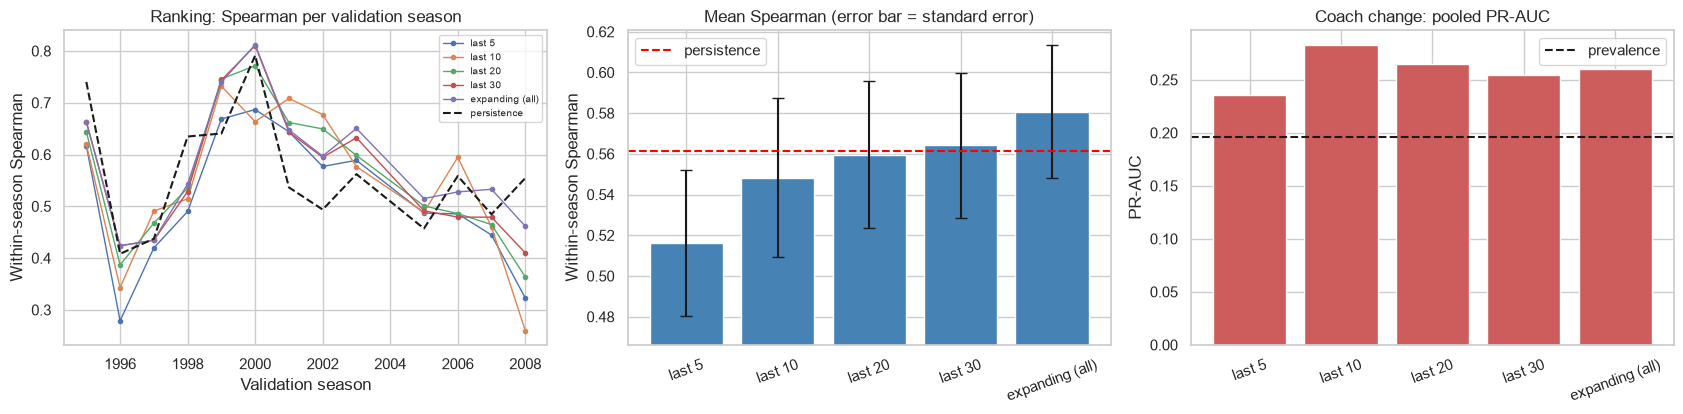

In [63]:
all_seasons = sorted(frame['year'].unique())
val_seasons = [s for s in all_seasons if 1995 <= s <= 2008]
# Rolling origin: for each validation season, train only on earlier seasons
windows = {'last 5': 5, 'last 10': 10, 'last 20': 20, 'last 30': 30, 'expanding (all)': None}

per_season, pooled = [], {}
for name, w in windows.items():
    probs, truth, ntrain, npos = [], [], [], []
    for v in val_seasons:
        past = [s for s in all_seasons if s < v]
        past = past[-w:] if w else past
        tr, te = frame[frame['year'].isin(past)], frame[frame['year'] == v]
        rho = stats.spearmanr(ridge().fit(tr[FEATURES], tr['target_ppg_z']).predict(te[FEATURES]), te['target_ppg_z'])[0]
        p = logit().fit(tr[FEATURES], tr['target_coach_change']).predict_proba(te[FEATURES])[:, 1]
        pr = average_precision_score(te['target_coach_change'], p) if te['target_coach_change'].sum() else np.nan
        per_season.append({'window': name, 'season': v, 'spearman': rho, 'pr_auc': pr, 'train_rows': len(tr), 'train_positives': int(tr['target_coach_change'].sum())})
        probs += list(p)
        truth += list(te['target_coach_change'])
    pooled[name] = average_precision_score(truth, probs)
# Compare every window with persistence and with the expanding window
ps = pd.DataFrame(per_season)
persist = pd.Series({v: stats.spearmanr(g['prev_ppg_z'], g['target_ppg_z'], nan_policy='omit')[0] for v, g in frame[frame['year'].isin(val_seasons)].groupby('year')})
prev_rate = frame[frame['year'].isin(val_seasons)]['target_coach_change'].mean()

summary = ps.groupby('window', sort=False).agg(mean_train_rows=('train_rows', 'mean'), mean_train_positives=('train_positives', 'mean'),
                                              spearman=('spearman', 'mean'), spearman_sd=('spearman', 'std'), pr_auc_per_season=('pr_auc', 'mean'))
summary['pr_auc_pooled'] = pd.Series(pooled)
summary['seasons beating persistence'] = [int((ps[ps['window'] == w].set_index('season')['spearman'] > persist).sum()) for w in summary.index]
exp = ps[ps['window'] == 'expanding (all)'].set_index('season')
summary['Wilcoxon p vs expanding (Spearman)'] = [np.nan if w == 'expanding (all)' else stats.wilcoxon(ps[ps['window'] == w].set_index('season')['spearman'], exp['spearman']).pvalue for w in summary.index]
display(summary.round(3))
print(f"Validation seasons: {len(val_seasons)} ({val_seasons[0]}-{val_seasons[-1]}, 2004 absent). Persistence Spearman mean {persist.mean():.3f}; coach-change prevalence {prev_rate:.3f}")
print('Seasons available before the first validation season (1995):', len([s for s in all_seasons if s < 1995]))

# Plot
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for name in windows:
    d = ps[ps['window'] == name]
    ax[0].plot(d['season'], d['spearman'], 'o-', ms=3, lw=1, label=name)
ax[0].plot(persist.index, persist.values, 'k--', label='persistence')
ax[0].set(title='Ranking: Spearman per validation season', xlabel='Validation season', ylabel='Within-season Spearman')
ax[0].legend(fontsize=7)
ax[1].bar(summary.index, summary['spearman'], yerr=summary['spearman_sd'] / np.sqrt(len(val_seasons)), capsize=4, color='steelblue')
ax[1].axhline(persist.mean(), color='red', ls='--', label='persistence')
ax[1].set_ylim(summary['spearman'].min() - 0.05, summary['spearman'].max() + 0.04)
ax[1].set(title='Mean Spearman (error bar = standard error)', ylabel='Within-season Spearman')
ax[1].legend()
ax[2].bar(summary.index, summary['pr_auc_pooled'], color='indianred')
ax[2].axhline(prev_rate, color='k', ls='--', label='prevalence')
ax[2].set(title='Coach change: pooled PR-AUC', ylabel='PR-AUC')
ax[2].legend()
for a in ax[1:]:
    a.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

**What we found** (13 validation seasons 1995-2008; persistence mean Spearman 0.561; coach-change prevalence 0.196):

| Training window | Mean train rows | Spearman (mean) | SD over seasons | Seasons beating persistence | Wilcoxon p vs expanding | Pooled PR-AUC | PR-AUC per season (mean) |
|---|---|---|---|---|---|---|---|
| last 5 | 137 | 0.516 | 0.129 | 5 of 13 | < 0.001 | 0.235 | 0.296 |
| last 10 | 259 | 0.548 | 0.141 | 7 of 13 | 0.244 | 0.282 | 0.357 |
| last 20 | 472 | 0.560 | 0.130 | 6 of 13 | 0.110 | 0.265 | 0.367 |
| last 30 | 643 | 0.564 | 0.128 | 7 of 13 | 0.010 | 0.255 | 0.347 |
| expanding (all) | 702 | 0.581 | 0.118 | 8 of 13 | - | 0.261 | 0.352 |

For the ranking, a longer window is better: 0.516 for 5 seasons up to 0.581 for all history. The 5-season window is clearly worse than expanding (p < 0.001) and so is the 30-season window (p = 0.010), so older seasons help; pre-2004 history is not outdated. The expanding window is best but only 0.020 above persistence (0.581 vs 0.561) and beats it in 8 of 13 seasons, so the +0.03 target of section 1 is not reached by this simple model; notebook 2 must improve on it. For coach change every window is above prevalence (pooled PR-AUC 0.235-0.282 vs 0.196), but differences between windows are small and noisy with only 25-151 positives for training, with no clear winner.

**Decision (validation scheme for notebooks 2-4):** rolling-origin evaluation, one season ahead, with the 13 validation seasons 1995-2008 as folds (stored in the fold column). Each fold trains on all earlier seasons from 1967 (expanding window) and predicts that whole season; hyper-parameters are chosen on the mean fold score, with seasons kept together. The last 10 seasons stay as a sensitivity check for the classifier. After tuning, models are refit on 1967-2008 and evaluated once on 2009. Caveat: the choices made in this notebook (dropped features, imputer, window) looked at seasons up to 2008, including the validation seasons, so validation scores are slightly optimistic. The 2009 season stays clean.

### 3.10 Class imbalance: prevalence over time and the plan

Look at how common coach changes are over the years (per season, 5-season moving average, per decade), test for a time trend and for differences between decades, and count how many positive cases each training window contains.

If the rate drifts over time, a model trained on old seasons faces a different base rate in new seasons, and probabilities need recalibration. The number of positives also limits how complex a classifier can be. The treatment of imbalance (class weights, SMOTE) must be applied only to the training part of each fold, otherwise synthetic copies leak into validation.

,mean,sum,count
decade,,,
1960s,0.194,7,36
1970s,0.276,47,170
1980s,0.233,49,210
1990s,0.155,39,252
2000s,0.204,49,240


Overall rate 1967-2008: 0.210 (191 of 908)
Trend of the yearly rate with time: Spearman rho = -0.36, p = 0.022 | differences between decades: chi2 = 9.9, dof = 4, p = 0.041


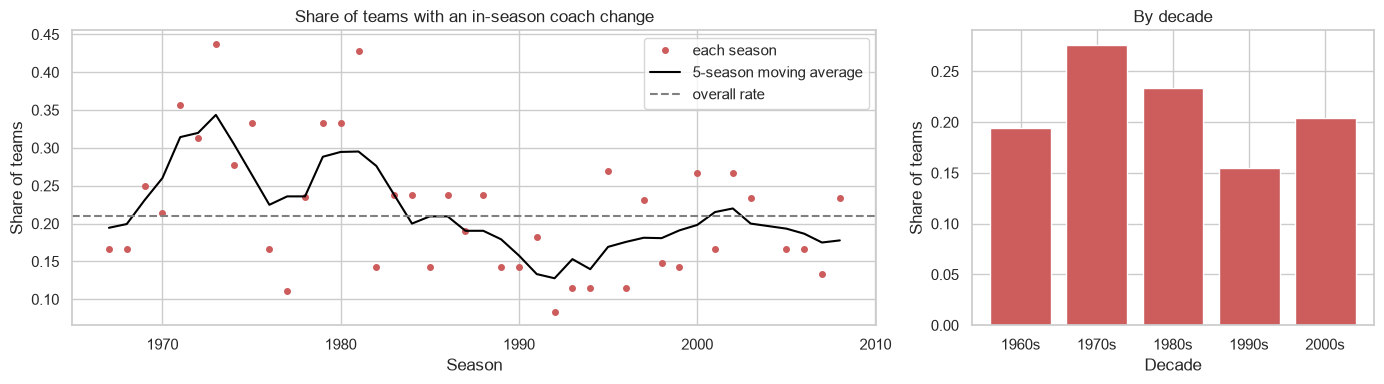

,training window (before 2008),rows,positives,share positive
0,last 5,150,29,0.193
1,last 10,291,56,0.192
2,last 20,525,93,0.177
3,last 30,728,143,0.196
4,expanding (all),878,184,0.210


In [64]:
# Coach-change rate per season and per decade
dv = frame[frame['year'] <= 2008]
rate = dv.groupby('year')['target_coach_change'].agg(['mean', 'sum', 'count'])
rate['moving avg (5 seasons)'] = rate['mean'].rolling(5, center=True, min_periods=3).mean()
rho, p = stats.spearmanr(rate.index, rate['mean'])
dv = dv.assign(decade=(dv['year'] // 10 * 10).astype(str) + 's')
dec = dv.groupby('decade')['target_coach_change'].agg(['mean', 'sum', 'count'])
chi2, p2, dof, _ = stats.chi2_contingency(pd.crosstab(dv['decade'], dv['target_coach_change']))
display(dec.round(3))
print(f"Overall rate 1967-2008: {dv['target_coach_change'].mean():.3f} ({int(dv['target_coach_change'].sum())} of {len(dv)})")
print(f"Trend of the yearly rate with time: Spearman rho = {rho:.2f}, p = {p:.3f} | differences between decades: chi2 = {chi2:.1f}, dof = {dof}, p = {p2:.3f}")

# Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [2, 1]})
ax[0].plot(rate.index, rate['mean'], 'o', color='indianred', ms=4, label='each season')
ax[0].plot(rate.index, rate['moving avg (5 seasons)'], '-', color='black', label='5-season moving average')
ax[0].axhline(dv['target_coach_change'].mean(), color='grey', ls='--', label='overall rate')
ax[0].set(title='Share of teams with an in-season coach change', xlabel='Season', ylabel='Share of teams')
ax[0].legend()
ax[1].bar(dec.index, dec['mean'], color='indianred')
ax[1].set(title='By decade', xlabel='Decade', ylabel='Share of teams')
plt.tight_layout()
plt.show()

# Positives available in each training window
wins = []
for name, w in [('last 5', 5), ('last 10', 10), ('last 20', 20), ('last 30', 30), ('expanding (all)', None)]:
    past = [s for s in all_seasons if s < 2008]
    past = past[-w:] if w else past
    t = frame[frame['year'].isin(past)]
    wins.append({'training window (before 2008)': name, 'rows': len(t), 'positives': int(t['target_coach_change'].sum()), 'share positive': round(t['target_coach_change'].mean(), 3)})
display(pd.DataFrame(wins))

**What we found:** The coach-change rate is 21.0% overall (191 of 908 team-seasons, 1967-2008) but it drifts: 19.4% (1960s), 27.6% (1970s), 23.3% (1980s), 15.5% (1990s), 20.4% (2000s). The yearly rate falls with time (Spearman rho = -0.36, p = 0.022) and the decades differ (chi-square = 9.9, dof = 4, p = 0.041). Training windows before 2008 contain from 29 positives (last 5 seasons, 19.3%) to 184 (all seasons, 21.0%).

**Plan:** the imbalance is moderate (about 1 change in 5), not extreme, but the base rate varies over time, so a model trained on old seasons faces another prevalence in new seasons. Plan for notebook 3: (1) class_weight = balanced as the first remedy; (2) SMOTE or random oversampling only inside each training fold with an imblearn pipeline, never on validation or test rows; (3) compare with no resampling; (4) choose the decision threshold on validation folds only, aiming at recall at an acceptable precision (or F2), and check calibration because resampling distorts probabilities; (5) report PR-AUC, recall, precision and lift, not accuracy (always answering "no change" would be right about 79% of the time).

### 3.11 Export for notebooks 2-4

Write `data/processed/model_table_v2.csv`: identifiers, split and fold columns, the kept features (NaN left as they are, with the three missing indicators), and the targets. We check the leakage rules with assertions and print shape and columns.

The modeling notebooks must start from one agreed table. Leaving NaN and adding indicators keeps imputation inside the training folds (in a pipeline), as decided in 3.6. The split columns encode the validation design from 3.9, so every notebook uses the same folds.

In [65]:
IDS = ['year', 'lgID', 'tmID', 'franchID', 'name', 'confID', 'divID', 'games', 'prev_year', 'prev_gap', 'split', 'fold']
TARGETS = ['target_ppg', 'target_ppg_z', 'target_points', 'target_rank_league', 'target_rank_division', 'target_coach_change']
# Leakage checks
assert all(f.startswith(('prev_', 'coach_')) or f == 'has_prev' for f in FEATURES), 'a feature is not from season t-1 or an opening-day fact'
assert not any('target' in f for f in FEATURES)
assert (frame.loc[frame['has_prev'] == 1, 'prev_year'] < frame.loc[frame['has_prev'] == 1, 'year']).all()
assert frame['prev_gap'].dropna().isin([1, 2]).all() and frame[['year', 'tmID']].duplicated().sum() == 0
assert frame['target_coach_change'].notna().all() and frame['target_ppg_z'].notna().all()

# Persistence baseline column
frame['baseline_prev_ppg'] = frame['prev_ppg']
BASELINE = ['baseline_prev_ppg']
# Write the table
model_table = frame[IDS + FEATURES + BASELINE + TARGETS].copy()
out = ROOT / 'data' / 'processed' / 'modeling_table.csv'
out.parent.mkdir(parents=True, exist_ok=True)
model_table.round(10).to_csv(out, index=False)  # rounding makes the file identical on every run
back = pd.read_csv(out)
print(f"Saved {out.name}: shape {back.shape} (rows x columns)")
print('Columns by role:')
print('  ids and folds :', IDS)
print(f'  features ({len(FEATURES)}):', FEATURES)
print('  baseline col  :', BASELINE, '(last season points per game, raw, for the persistence baseline; not a feature)')
print('  targets       :', TARGETS)
print('Rows per split:', back['split'].value_counts().to_dict(), '| validation folds:', sorted(back['fold'].dropna().astype(int).unique())[:3], '...', int(back['fold'].max()))
display(back[FEATURES].isna().mean().mul(100).round(1).rename('% missing').to_frame().T)

Saved modeling_table.csv: shape (938, 46) (rows x columns)
Columns by role:
  ids and folds : ['year', 'lgID', 'tmID', 'franchID', 'name', 'confID', 'divID', 'games', 'prev_year', 'prev_gap', 'split', 'fold']
  features (27): ['prev_gf_pg_z', 'prev_ga_pg_z', 'prev_luck_z', 'prev_pp_pct_z', 'prev_pk_pct_z', 'prev_pim_pg_z', 'prev_shorthanded_net_pg_z', 'prev_home_edge_z', 'prev_late_form_z', 'prev_playoff_series_won_z', 'prev_players_used_z', 'prev_roster_age_z', 'prev_top_scorer_share_z', 'prev_shooting_pct_z', 'prev_save_pct_z', 'prev_pdo_z', 'prev_starter_minutes_share_z', 'prev_made_playoffs', 'prev_short_season', 'coach_new', 'coach_tenure', 'coach_career_games_log', 'coach_career_pct', 'prev_coach_change', 'has_prev', 'prev_goalie_data_missing', 'coach_first_time']
  baseline col  : ['baseline_prev_ppg'] (last season points per game, raw, for the persistence baseline; not a feature)
  targets       : ['target_ppg', 'target_ppg_z', 'target_points', 'target_rank_league', 'target_ran

,prev_gf_pg_z,prev_ga_pg_z,prev_luck_z,prev_pp_pct_z,prev_pk_pct_z,prev_pim_pg_z,prev_shorthanded_net_pg_z,prev_home_edge_z,prev_late_form_z,prev_playoff_series_won_z,prev_players_used_z,prev_roster_age_z,prev_top_scorer_share_z,prev_shooting_pct_z,prev_save_pct_z,prev_pdo_z,prev_starter_minutes_share_z,prev_made_playoffs,prev_short_season,coach_new,coach_tenure,coach_career_games_log,coach_career_pct,prev_coach_change,has_prev,prev_goalie_data_missing,coach_first_time
% missing,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7,2.7,3.3,29.6,29.6,2.7,2.7,2.7,2.7,0.0,0.0,13.3,2.7,0.0,0.0,0.0


**What we found:** `data/processed/modeling_table.csv` has shape (938, 46): 12 identifier and split columns, 27 feature columns (24 kept candidates plus 3 indicators), 1 baseline column and 6 target columns. Splits: train_pool 535 rows (1967-1994), validation 373 rows (folds 1995-2008) and test 30 rows (2009). The share of missing values per feature is 2.7% for most last-season features, 29.6% for save percentage and PDO, 13.3% for career points share and 0% for the indicators, tenure and career games. All assertions pass: every feature is a prev_* value, a coach fact or an indicator, the previous season is always before the target season, gaps are 1 or 2, and keys are unique.

**Note:** the column games (games of season t) is kept as an identifier for checks only, not as a feature.

## 4. Conclusion

**Decisions taken in this notebook**

| # | Decision | Reason | Evidence (section) |
|---|---|---|---|
| 1 | NHL only, target seasons 1967-2009 | Only league with data to 2009; from 1967 12-30 teams per season and complete special-teams fields (earlier eras 0-16% complete, 6-7 teams) | 3.8: 938 rows, 100% completeness |
| 2 | Targets: points per game (rank = sort within season) and coach change = more than one coach stint | Team decisions (section 1); offseason hires are known before the cutoff | 1.3, 2.2 |
| 3 | Features only from season t-1 and the opening-day coach; lag = previous completed NHL season of the same franchise (2005 uses 2003) | No leakage; franchID survives team-code changes, WHA entrants of 1979 have no NHL lag | 3.1: 913 vs 903 matches, 13 franchises with several codes; assertions in 3.11 |
| 4 | Goal features use goals in play (shootout goals removed) | Team totals count one goal per shootout win from 2005 | 3.2: 149 mismatches become 0 |
| 5 | Phoenix 2009 coach corrected to Tippett in a derived copy | Accuracy check; raw data untouched | 3.2 |
| 6 | Non-parametric tests; within-season z-scores | Normality rejected (Shapiro p = 0.006); era drift (goals H = 384.5, epsilon^2 = 0.42) vanishes after z-scoring (H = 0.0) | 2.3, 2.4, 3.4 |
| 7 | Keep real extremes; cap continuous z at +/-3; flag the 1994 lockout | All flagged cases have domain explanations; 27 capped cells (largest absolute z 3.70 -> 3.00, skewness changes by at most 0.04) | 3.5 |
| 8 | Leave NaN in the export; add 3 indicators; IterativeImputer inside training folds | RMSE 0.715 vs mean 0.986, median 1.018, KNN 0.806 on hidden values of held-out seasons; 3.6.1: save percentage keeps 75.7% of its variance (mean imputation 60.7%) and the correlation error is 0.028 vs 0.045 | 3.6, 3.6.1 |
| 9 | Drop prev_gd_pg_z, prev_pythag_z and prev_ppg_z | Rank-correlation cluster above 0.9, then VIF 49.2; final max VIF 7.40; 24 features plus 3 indicators; pairs with absolute rho above 0.7 fall from 20 to 5 (maximum 1.00 -> 0.82) | 3.7 |
| 10 | Validation: rolling origin, one season ahead, folds 1995-2008, expanding training window; refit on 1967-2008 and test once on 2009 | Spearman 0.581 for expanding vs 0.516 (last 5, p < 0.001) and 0.564 (last 30, p = 0.010); pre-2004 history is not outdated | 3.9 |
| 11 | Imbalance: class weights first, SMOTE only inside training folds; judge by PR-AUC, recall, lift | Prevalence 21.0%, drifting by decade (chi-square p = 0.041) | 3.10 |
| 12 | Use luck, goals for and goals against as separate features; keep clusters out of the features | Partial r of luck = -0.172; silhouette at most 0.22 | 2.9, 2.12 |

**Baselines to beat (validation seasons 1995-2008):** persistence Spearman 0.561; simple Ridge with expanding window 0.581; coach-change prevalence 0.196 (simple logistic pooled PR-AUC 0.261). Success criteria from section 1: Spearman at least 0.03 above persistence, PR-AUC at least 1.25 times prevalence, top-quartile recall at least 40%.

**Hand-off**
- **2_regression** reads `data/processed/model_table_v2.csv`. Features: columns starting with `prev_` or `coach_` plus `has_prev`; target `target_ppg_z` (rank targets `target_rank_league`, `target_rank_division`); baseline column `baseline_prev_ppg`. Use the `fold` column for the rolling origin. Imputer (iterative) and scaler go inside every pipeline. Compare several algorithm families with systematic tuning, within-season Spearman, MAE of points per game, rank error, significance tests over the 13 folds, learning and overfitting curves, feature importance and a interpretable model.
- **3_classification** uses `target_coach_change` with the same folds. Class weights and SMOTE inside training folds, threshold chosen on validation folds only, PR-AUC, recall, precision, lift, calibration, readable rules or odds ratios.
- **4_feature_selection** starts from the 27 columns: filter (mutual information, correlation), embedded (L1) and wrapper (forward selection or RFE) steps, all fitted inside the training folds.
- **Test season 2009:** untouched until the final evaluation. Its 30 rows are in the export (`split = test`). A single season is a small and noisy test, so confidence intervals are needed.

**Caveats and doubts**
- The opening-day coach is taken as the stint-1 coach (largest games count in the rare case of co-coaches). The target is an in-season appointment change, not a verified dismissal, and the Detroit 1998 and Ottawa 2001 rows are special cases.
- The dropped features, the imputer and the window were chosen looking at seasons up to 2008, which include the validation seasons, so validation scores carry a small optimism. The 2009 season was not used in any choice.
- Within-season z-scores need all teams of a season, which exist on the day before the next season (they come from the previous season). The target z-score uses only the target season's own teams and is needed for training and evaluation, not as an input.
- Task (c) of the assignment is TBA and not covered.

**Where each rubric criterion is covered**

| Criterion | Where |
|---|---|
| BU: requirements, business goals, DM goals | 1.1, 1.2, 1.3 |
| DU: diversity and complexity of methods, interpretation, knowledge | 2.3 to 2.14 (normality, Kruskal-Wallis, Spearman with FDR, OLS, logistic regression, partial correlation, PCA, k-means, mutual information) |
| DU: diversity and complexity of plots, visual knowledge | histogram/KDE, Q-Q, boxplots, heatmaps, regression and added-variable plots, forest plot, pair plot, biplot, parallel coordinates, dendrogram |
| DP: integration, quality, features | 3.1, 3.2, 3.3 |
| DP: pipeline overview | diagram at the start of section 3 |
| DP: transformation, outliers, missing data, redundancy (with before/after plots) | 3.4, 3.5, 3.6, 3.6.1, 3.7 |
| DP: sampling (domain and development), imbalance | 3.8, 3.9, 3.10 |
| DP: feature selection | notebook 4 |
| Tools: database, Python stack | DuckDB SQL throughout; pandas, scikit-learn, statsmodels, seaborn |